Numbers, Data, and Tokenization
### A hands-on Python companion to Lecture 2a (INFSCI / PS 0702)

* **Link to lecture slides:** https://docs.google.com/presentation/d/1p2Q4ZHmMov7q0o4IJb26eDil79QBHWhzKA0n018OcZ4/edit?usp=sharing 
* **Who this notebook is for:** students with little to no programming experience. Every line of code is explained. You are not expected to write code from scratch yet, but I would like for you to become comfortable to run code.

| Lecture topic | Notebook section |
|---|---|
| What are data? The wisdom hierarchy (data → information → knowledge) | 1 |
| Data are "nature's evidence seen through a measuring instrument"; mis-sampling | 2 |
| Why numbers matter; SI prefixes; million vs. billion; estimation; translation | 3 |
| Rates, ratios, odds, percentages | 4 |
| The same numbers sliced three different ways | 5 |
| What computers use: bits, bytes, hexadecimal, qubits | 6 |
| Structured data: rows = samples, columns = features | 7 |
| Explanation or prediction: ŷ = f(x₁, …, xₙ) | 8 |
| Missing data, imputation, covariates, dimensionality | 9 |
| Semi-structured data (citations) | 10 |
| Unstructured text data; designed vs. found data; n-grams | 11 |
| Network (graph) data | 12 |
| Taxonomic data (the radio spectrum as a tree) | 13 |
| Metadata: generative, destructive, triangulated | 14 |
| Tokenization (the fintech / advertising-ID sense) | 15 |
| Beyond tokenization: fine-grained sensing of human activity | 16 |
| Recap: one small pipeline from raw data to knowledge | 17 |
| **Glossary of every term used** | 18 |
| Exercises (with answers) | 19 |




# Section 1: What *are* data? The wisdom hierarchy

**Slides 2, 3, 4, 6, 7.**

The lecture defines data as *the raw, uncoded record of the world — before we give it meaning*:
births and deaths, votes, someone entering a building, rainfall, a soccer game. Then it stacks four
levels on top of each other:

| Level | Slide's phrasing | The other view (*The Secret Life of Data*) |
|---|---|---|
| **Data** | raw (e.g., bell peppers at a farmers market) | discrete quantitative values extracted from a larger, more complex phenomenon |
| **Information** | total sales | those values put into context and given social meaning |
| **Knowledge** | models | actionable inferences drawn by interested parties |
| **Wisdom** | inference? | (the slide leaves this one with a question mark — deliberately) |

Each layer builds on the one below it. Notice that **every step upward throws information away and
adds interpretation.** That is the whole lesson of this notebook, and we are going to watch it
happen in code.

Let's build the pyramid first, then climb it with a real (small) dataset.


In [14]:
# Python by itself is small. "Libraries" are add-on toolboxes. We import them once, here, and use
# them for the rest of the notebook. If a cell later says "NameError: np is not defined",
# it means you did not run THIS cell.

import numpy as np                # numpy: fast arrays of numbers, random number generation
import pandas as pd               # pandas: tables of data (rows and columns), like a spreadsheet
import matplotlib.pyplot as plt   # matplotlib: charts and plots

# A shared "random number generator". The number 7 is a "seed": it makes the random numbers
# reproducible, so your figures look exactly like the ones described in the text.
rng = np.random.default_rng(7)

# Make all our charts a consistent, readable size.
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11

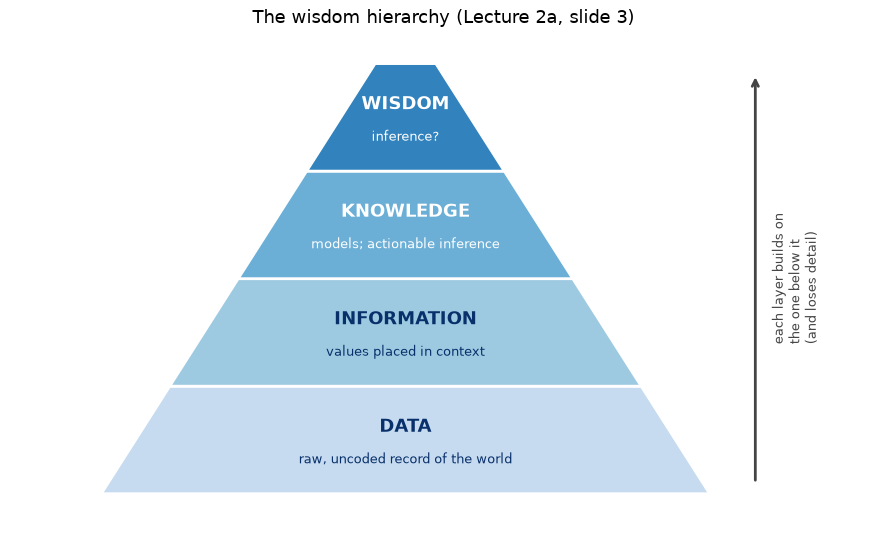

In [15]:
# Draw the wisdom hierarchy as a pyramid.
# You do not need to understand this drawing code -- it is here so the figure is reproducible.
# Read it as: for each of four levels, draw a trapezoid and write two labels on it.

fig, ax = plt.subplots(figsize=(9, 5.5))

levels = [
    # (label,      subtitle,                             y_bottom, y_top, half_width_bottom, half_width_top)
    ("DATA",       "raw, uncoded record of the world",   0.0, 1.0, 4.0, 3.1),
    ("INFORMATION","values placed in context",           1.0, 2.0, 3.1, 2.2),
    ("KNOWLEDGE",  "models; actionable inference",       2.0, 3.0, 2.2, 1.3),
    ("WISDOM",     "inference?",                         3.0, 4.0, 1.3, 0.4),
]
shades = ["#c6dbef", "#9ecae1", "#6baed6", "#3182bd"]

for i, ((label, subtitle, y0, y1, w0, w1), colour) in enumerate(zip(levels, shades)):
    # A trapezoid is just a 4-cornered polygon: bottom-left, bottom-right, top-right, top-left.
    ax.fill([-w0, w0, w1, -w1], [y0, y0, y1, y1], color=colour, edgecolor="white", linewidth=2)
    text_colour = "white" if i >= 2 else "#08306b"      # dark layers need light text
    ax.text(0, (y0 + y1) / 2 + 0.12, label, ha="center", va="center",
            fontsize=13, fontweight="bold", color=text_colour)
    ax.text(0, (y0 + y1) / 2 - 0.18, subtitle, ha="center", va="center", fontsize=9,
            color=text_colour)

# An arrow up the side to show that each layer builds on the one below.
ax.annotate("", xy=(4.6, 3.9), xytext=(4.6, 0.1),
            arrowprops=dict(arrowstyle="->", linewidth=2, color="#444444"))
ax.text(4.8, 2.0, "each layer builds on\nthe one below it\n(and loses detail)",
        rotation=90, va="center", fontsize=9, color="#444444")

ax.set_xlim(-5.2, 6.2)
ax.set_ylim(-0.3, 4.3)
ax.axis("off")
ax.set_title("The wisdom hierarchy (Lecture 2a, slide 3)", fontsize=13)
plt.tight_layout()
plt.show()


### 1.1 Level one: raw data

The slide's example is *bell peppers at a farmers market*. So let's make that concrete. Below is a
**raw record**: one row per transaction, exactly as a till or a clipboard would capture it. Nobody
has summarised anything yet. This is what "raw and uncoded" means.

Note what a raw record looks like in practice: it is long, repetitive, boring, and slightly messy.
Human beings cannot read it. That is *why* we need the layers above.


In [16]:
# Build a raw transaction log for one Saturday at a farmers market.
# We SIMULATE it (generate plausible fake numbers) because we want a dataset small enough to
# print but real enough to behave like real data.

n_transactions = 240                                  # 240 sales over the day

hours = rng.choice([8, 9, 10, 11, 12, 13, 14],        # market runs 8am-2pm
                   size=n_transactions,
                   p=[0.08, 0.14, 0.20, 0.22, 0.16, 0.12, 0.08])   # busiest mid-morning
minutes = rng.integers(0, 60, size=n_transactions)

items = rng.choice(["bell pepper", "tomato", "kale", "peach"],
                   size=n_transactions, p=[0.40, 0.28, 0.17, 0.15])

unit_price = {"bell pepper": 1.25, "tomato": 0.90, "kale": 3.00, "peach": 0.75}

quantity = rng.integers(1, 7, size=n_transactions)    # 1 to 6 units per sale

raw_log = pd.DataFrame({
    "hour": hours,
    "minute": minutes,
    "item": items,
    "quantity": quantity,
})
raw_log["unit_price"] = raw_log["item"].map(unit_price)     # look up the price for each row
raw_log["amount"] = raw_log["quantity"] * raw_log["unit_price"]
raw_log = raw_log.sort_values(["hour", "minute"]).reset_index(drop=True)

print(f"The raw log has {raw_log.shape[0]} rows and {raw_log.shape[1]} columns.")
print("\nThe first 12 rows -- this is DATA:")
print(raw_log.head(12))


The raw log has 240 rows and 6 columns.

The first 12 rows -- this is DATA:
    hour  minute         item  quantity  unit_price  amount
0      8       1  bell pepper         6        1.25    7.50
1      8       3       tomato         4        0.90    3.60
2      8      11       tomato         1        0.90    0.90
3      8      12       tomato         1        0.90    0.90
4      8      15        peach         4        0.75    3.00
5      8      17  bell pepper         3        1.25    3.75
6      8      18  bell pepper         6        1.25    7.50
7      8      29       tomato         4        0.90    3.60
8      8      32  bell pepper         5        1.25    6.25
9      8      34  bell pepper         5        1.25    6.25
10     8      35         kale         6        3.00   18.00
11     8      38         kale         2        3.00    6.00


A few pieces of vocabulary from that cell, because they recur everywhere:

- **`pd.DataFrame`** — pandas' name for a table. Rows and columns, like a spreadsheet tab.
- **`.shape`** — `(number of rows, number of columns)`.
- **`.head(12)`** — show me the first 12 rows. (`.tail()` shows the last ones.)
- **`.map(dictionary)`** — go down a column and replace each value using a lookup table.

Now: what does raw data *look* like when you plot it? Like noise.


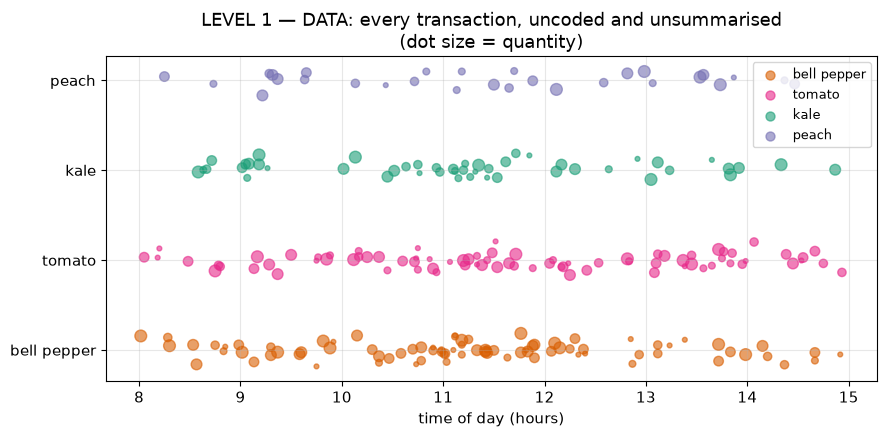

Can you answer 'how did the market do today?' from this picture? Not really. That is the point.


In [17]:
# Plot every single transaction as one dot. This is the DATA layer, visualised.

fig, ax = plt.subplots()

# Convert hour + minute into "hours since midnight" as a decimal, so dots spread across the day.
time_of_day = raw_log["hour"] + raw_log["minute"] / 60

# Give each item type its own colour and vertical position.
item_order = ["bell pepper", "tomato", "kale", "peach"]
colours = {"bell pepper": "#d95f02", "tomato": "#e7298a", "kale": "#1b9e77", "peach": "#7570b3"}

for i, item in enumerate(item_order):
    mask = raw_log["item"] == item          # a "mask" is a column of True/False: which rows match?
    ax.scatter(time_of_day[mask],
               np.full(mask.sum(), i) + rng.normal(0, 0.08, mask.sum()),  # jitter so dots don't overlap
               s=raw_log.loc[mask, "quantity"] * 12,     # dot size = quantity sold
               alpha=0.6, color=colours[item], label=item)

ax.set_yticks(range(len(item_order)))
ax.set_yticklabels(item_order)
ax.set_xlabel("time of day (hours)")
ax.set_title("LEVEL 1 — DATA: every transaction, uncoded and unsummarised\n(dot size = quantity)")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

print("Can you answer 'how did the market do today?' from this picture? Not really. That is the point.")


### 1.2 Level two: information ("total sales")

The slide's example of *information* is literally **total sales**. Turning 240 rows into a handful of
totals is called **aggregation**, and it is the single most common operation in data analysis.

In pandas the pattern is `df.groupby("some column")["another column"].sum()`, which reads in English
as: *split the table into groups by this column, then add up that column within each group.*


In [18]:
# AGGREGATE the raw log into information.

# (a) Total revenue and units, by item.
by_item = raw_log.groupby("item").agg(
    units_sold=("quantity", "sum"),
    revenue=("amount", "sum"),
    transactions=("amount", "count"),
    mean_basket=("amount", "mean"),
)
by_item = by_item.sort_values("revenue", ascending=False)

print("LEVEL 2 -- INFORMATION: the same 240 rows, now summarised")
print(by_item.round(2))
print(f"\nTotal revenue for the day: ${raw_log['amount'].sum():,.2f}")

# (b) Total revenue by hour.
by_hour = raw_log.groupby("hour")["amount"].sum()
print("\nRevenue by hour:")
print(by_hour.round(2))


LEVEL 2 -- INFORMATION: the same 240 rows, now summarised
             units_sold  revenue  transactions  mean_basket
item                                                       
kale                174   522.00            48        10.88
bell pepper         295   368.75            83         4.44
tomato              269   242.10            80         3.03
peach               104    78.00            29         2.69

Total revenue for the day: $1,210.85

Revenue by hour:
hour
8     113.05
9     192.15
10    204.95
11    280.55
12    142.45
13    193.40
14     84.30
Name: amount, dtype: float64


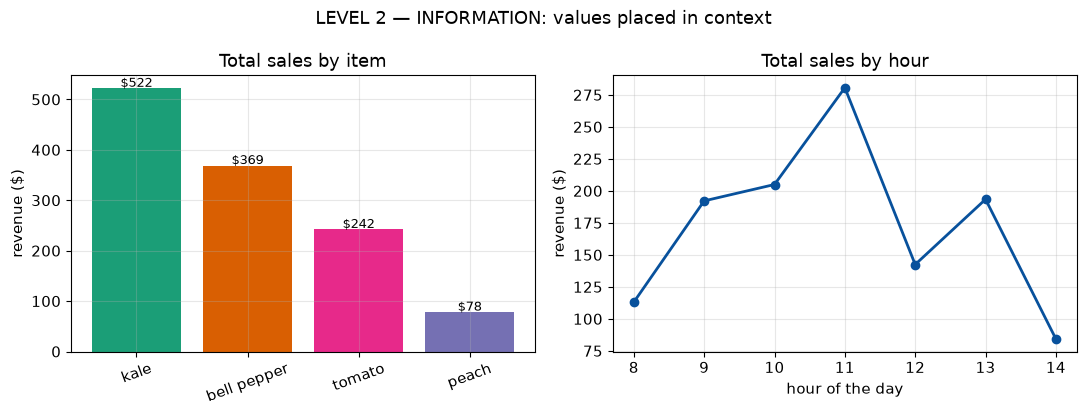

Now the day has a shape: peppers lead, mid-morning is the peak.
Notice what we LOST: we can no longer see any individual customer.


In [19]:
# Visualise the information layer: two small charts side by side.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: revenue by item (a bar chart -- the right choice for comparing categories).
ax1.bar(by_item.index, by_item["revenue"],
        color=[colours[i] for i in by_item.index])
for x, v in zip(by_item.index, by_item["revenue"]):
    ax1.text(x, v + 3, f"${v:,.0f}", ha="center", fontsize=9)
ax1.set_ylabel("revenue ($)")
ax1.set_title("Total sales by item")
ax1.tick_params(axis="x", rotation=20)

# Right: revenue by hour (a line, because hours have a natural order).
ax2.plot(by_hour.index, by_hour.values, marker="o", color="#08519c", linewidth=2)
ax2.set_xlabel("hour of the day")
ax2.set_ylabel("revenue ($)")
ax2.set_title("Total sales by hour")

fig.suptitle("LEVEL 2 — INFORMATION: values placed in context", fontsize=13)
plt.tight_layout()
plt.show()

print("Now the day has a shape: peppers lead, mid-morning is the peak.")
print("Notice what we LOST: we can no longer see any individual customer.")


### 1.3 Level three: knowledge (a *model*)

The slide says knowledge is **models**, and *The Secret Life of Data* calls it **actionable
inferences drawn by interested parties**. A model is a compressed claim about how the world works.
It lets you say something about a situation you have **not** observed.

Here is the smallest useful model: a straight line through the relationship between price and units
sold. We will generate a small price experiment (different prices on different Saturdays) and fit a
line to it.

`np.polyfit(x, y, 1)` fits a straight line — the `1` means "degree 1", i.e. a line. It hands back
the slope and the intercept.


Fitted model:  units_sold  =  150.5  +  (-47.5) x price
Reading it in English: every extra $1.00 on the price loses about 48 peppers of sales.
  At $1.00 the model predicts 103 units sold.
  At $1.35 the model predicts 86 units sold.
  At $2.50 the model predicts 32 units sold.


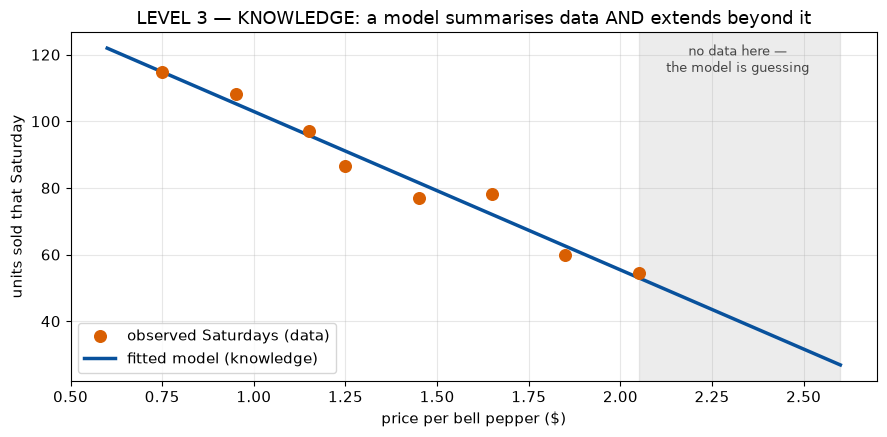

In [20]:
# A small "price experiment": eight Saturdays, eight different pepper prices.
prices  = np.array([0.75, 0.95, 1.15, 1.25, 1.45, 1.65, 1.85, 2.05])
true_slope, true_intercept = -55.0, 160.0      # the "truth" we are pretending nature obeys
units   = true_intercept + true_slope * prices + rng.normal(0, 8, size=len(prices))

# FIT THE MODEL: find the line that best matches these eight points.
slope, intercept = np.polyfit(prices, units, 1)

print(f"Fitted model:  units_sold  =  {intercept:.1f}  +  ({slope:.1f}) x price")
print(f"Reading it in English: every extra $1.00 on the price loses about {abs(slope):.0f} peppers of sales.")

# USE THE MODEL to predict a price we never actually tried:
for p in [1.00, 1.35, 2.50]:
    predicted = intercept + slope * p
    print(f"  At ${p:.2f} the model predicts {predicted:.0f} units sold.")

fig, ax = plt.subplots()
ax.scatter(prices, units, s=70, color="#d95f02", zorder=3, label="observed Saturdays (data)")
line_x = np.linspace(0.6, 2.6, 100)
ax.plot(line_x, intercept + slope * line_x, color="#08519c", linewidth=2.5,
        label="fitted model (knowledge)")
ax.axvspan(2.05, 2.6, color="grey", alpha=0.15)
ax.text(2.32, units.max(), "no data here —\nthe model is guessing", ha="center", fontsize=9, color="#444")
ax.set_xlabel("price per bell pepper ($)")
ax.set_ylabel("units sold that Saturday")
ax.set_title("LEVEL 3 — KNOWLEDGE: a model summarises data AND extends beyond it")
ax.legend()
plt.tight_layout()
plt.show()


Look hard at the grey band on the right. The model happily produces a number for a $2.50 pepper, but
we never sold peppers at 2.50. **The model's confidence is not evidence.** This is the first of the
"pitfalls and precautions" the lecture promises to cover later, and it is worth naming now:
extrapolation beyond your data is where models quietly stop being knowledge and start being fiction.

### 1.4 Level four: wisdom (the slide's question mark)

The slide writes "Wisdom — inference?" with a question mark, and does not define it.
Code cannot do this layer. Wisdom is deciding *whether the model should be used at all*: should we
raise the pepper price to maximise revenue if the market serves a neighbourhood with few grocery
options? No `groupby` answers that.

What computation *can* do is make the trade-off visible so a human can judge it.


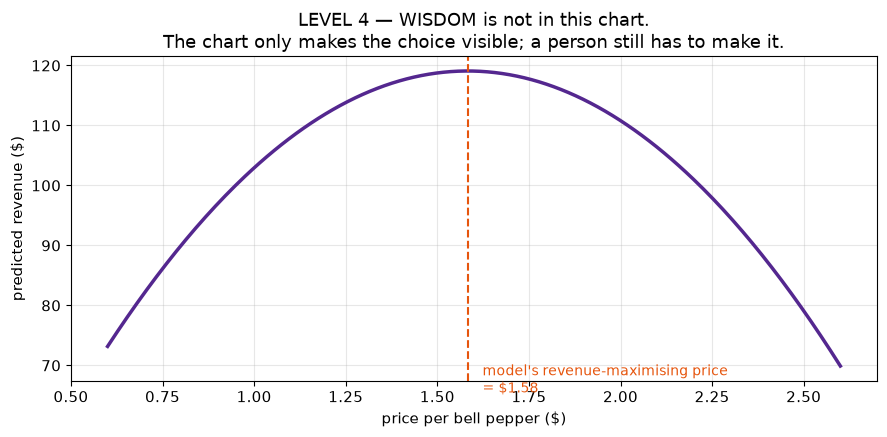

Computation says: charge $1.58.
Computation does not say: whether you should, who can afford it, or what it does to the
neighbourhood. That is the layer the slide marks with a question mark.


In [21]:
# The model says revenue = price x units. Where is revenue maximised?
p_grid = np.linspace(0.60, 2.60, 300)
units_pred = intercept + slope * p_grid
revenue_pred = p_grid * np.clip(units_pred, 0, None)     # clip: units can never go below zero
best_p = p_grid[np.argmax(revenue_pred)]                 # argmax = "position of the largest value"

fig, ax = plt.subplots()
ax.plot(p_grid, revenue_pred, color="#54278f", linewidth=2.5)
ax.axvline(best_p, color="#e6550d", linestyle="--")
ax.text(best_p + 0.04, revenue_pred.max() * 0.55,
        f"model's revenue-maximising price\n= ${best_p:.2f}", fontsize=10, color="#e6550d")
ax.set_xlabel("price per bell pepper ($)")
ax.set_ylabel("predicted revenue ($)")
ax.set_title("LEVEL 4 — WISDOM is not in this chart.\nThe chart only makes the choice visible; a person still has to make it.")
plt.tight_layout()
plt.show()

print(f"Computation says: charge ${best_p:.2f}.")
print("Computation does not say: whether you should, who can afford it, or what it does to the")
print("neighbourhood. That is the layer the slide marks with a question mark.")


> ### Summary of Section 1
> - **Data** = 240 boring rows. Unreadable, but complete.
> - **Information** = 4 totals and a daily curve. Readable, but the customers are gone.
> - **Knowledge** = a model with two numbers (slope, intercept). Powerful, and dangerous outside its range.
> - **Wisdom** = not in the code.
>
> The lecture also notes (slide 6) that *finite data are unlikely to tell us the whole story*, which
> makes it *all the more important to understand the data*. Sections 2 and 9 are about exactly that.

---
---

# Section 2 — Data as evidence seen through an instrument

**Slide 5.** The slide quotes David J. Hand:

> Data are nature's evidence, seen through the lens of the measuring instrument.

and then asks two questions that you should ask of every dataset you ever touch:

1. **What is the measuring instrument, and what are its limitations?**
2. **Can we "mis-sample" the universe we wish to study?**

We are going to answer both by simulation. The trick of a simulation is that we get to *know the
truth* — we invent it — and then watch how much of it survives the instrument. With real data you
never get to see the truth, which is precisely why practising on simulated data is useful.


In [22]:
# Invent a "universe we wish to study": the commute times of 20,000 people in a city.
# In real life we can never see this. Here we can, because we made it up.

TRUE_N = 20_000
true_commute = np.concatenate([
    rng.normal(18, 5, int(TRUE_N * 0.55)),     # people who live close in
    rng.normal(38, 9, int(TRUE_N * 0.35)),     # suburban commuters
    rng.normal(72, 15, int(TRUE_N * 0.10)),    # long-distance commuters
])
true_commute = np.clip(true_commute, 2, None)   # nobody commutes in negative minutes

print(f"THE TRUTH (which we normally never get to see):")
print(f"  population size : {len(true_commute):,}")
print(f"  mean commute    : {true_commute.mean():.1f} minutes")
print(f"  median commute  : {np.median(true_commute):.1f} minutes")
print(f"  longest commute : {true_commute.max():.1f} minutes")


THE TRUTH (which we normally never get to see):
  population size : 20,000
  mean commute    : 30.4 minutes
  median commute  : 23.7 minutes
  longest commute : 118.6 minutes


### 2.1 Three limitations of a measuring instrument

Every real instrument distorts in at least three ways. We will apply them one at a time to the same
truth:

- **Resolution (rounding).** A survey that asks "how long is your commute, to the nearest 15
  minutes?" cannot see a 22-minute commute. It sees 15 or 30.
- **Range (clipping / censoring).** A question with a top answer of "60+ minutes" flattens every
  long commute into one bucket. The 140-minute commuter *disappears*.
- **Noise (error).** People misremember. Self-reported numbers wobble.


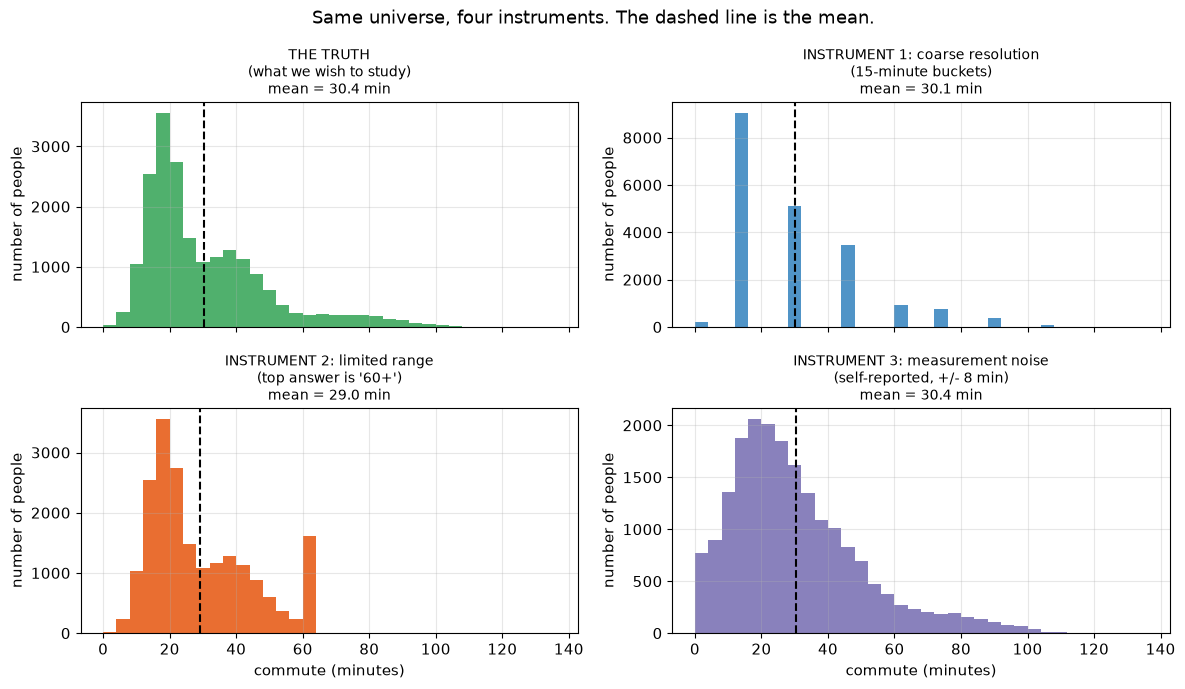

Notice how each distortion behaves DIFFERENTLY:
  truth mean            30.39
  rounded mean          30.09   <- barely moved, but the SHAPE is gone (combs)
  clipped mean          29.01   <- badly biased DOWN; long commutes erased
  noisy mean            30.39   <- mean survives, but the spread is inflated


In [23]:
# Apply each instrument limitation to the same underlying truth.

instrument_rounded = np.round(true_commute / 15) * 15                 # resolution: 15-minute buckets
instrument_clipped = np.clip(true_commute, 0, 60)                     # range: everything 60+ becomes 60
instrument_noisy   = true_commute + rng.normal(0, 8, len(true_commute))  # noise: +/- 8 min of memory error
instrument_noisy   = np.clip(instrument_noisy, 1, None)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
bins = np.arange(0, 140, 4)

panels = [
    (axes[0, 0], true_commute,       "THE TRUTH\n(what we wish to study)",            "#31a354"),
    (axes[0, 1], instrument_rounded, "INSTRUMENT 1: coarse resolution\n(15-minute buckets)", "#3182bd"),
    (axes[1, 0], instrument_clipped, "INSTRUMENT 2: limited range\n(top answer is '60+')",  "#e6550d"),
    (axes[1, 1], instrument_noisy,   "INSTRUMENT 3: measurement noise\n(self-reported, +/- 8 min)", "#756bb1"),
]
for ax, values, title, colour in panels:
    ax.hist(values, bins=bins, color=colour, alpha=0.85)
    ax.axvline(values.mean(), color="black", linestyle="--", linewidth=1.5)
    ax.set_title(f"{title}\nmean = {values.mean():.1f} min", fontsize=10)
    ax.set_ylabel("number of people")
axes[1, 0].set_xlabel("commute (minutes)")
axes[1, 1].set_xlabel("commute (minutes)")

fig.suptitle("Same universe, four instruments. The dashed line is the mean.", fontsize=13)
plt.tight_layout()
plt.show()

print("Notice how each distortion behaves DIFFERENTLY:")
print(f"  truth mean          {true_commute.mean():7.2f}")
print(f"  rounded mean        {instrument_rounded.mean():7.2f}   <- barely moved, but the SHAPE is gone (combs)")
print(f"  clipped mean        {instrument_clipped.mean():7.2f}   <- badly biased DOWN; long commutes erased")
print(f"  noisy mean          {instrument_noisy.mean():7.2f}   <- mean survives, but the spread is inflated")


This is one of the most useful lessons in the whole notebook: **different instrument flaws damage
different things.** Random noise often leaves the *average* nearly intact while ruining the *spread*.
Clipping wrecks the average. Coarse resolution can leave both roughly right while destroying the
*shape* — and shape is what tells you there are three kinds of commuter in this city.

Slide 7 asks "how are the values of an attribute distributed?" and "does visualizing the data help?"
The four panels above are the answer to the second question. The mean alone would not have told you.

### 2.2 Mis-sampling the universe

Now the second question. Suppose our instrument is fine, but we recruit respondents badly. This is
**sampling bias**, and it does not go away when you collect more data — a bigger biased sample is
just a more confident wrong answer.


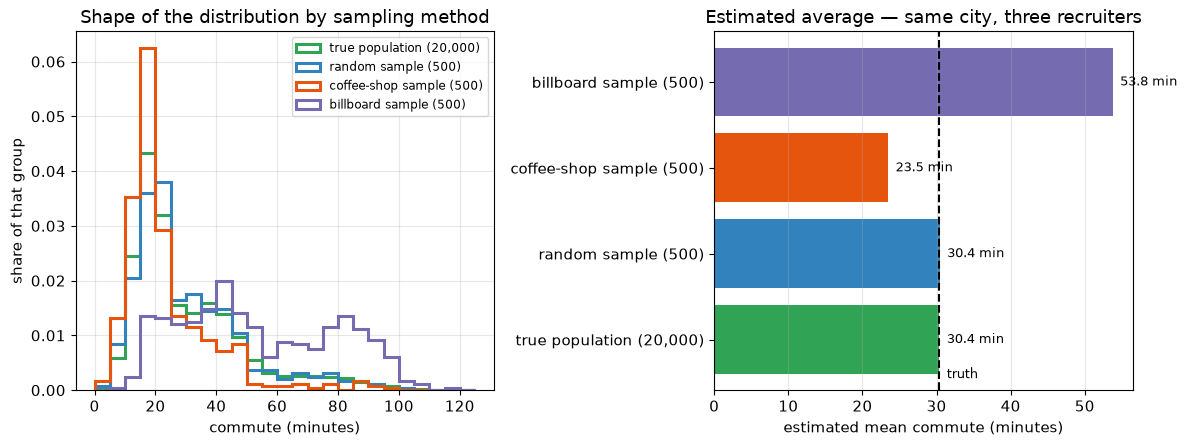

Three honest researchers, three instruments pointed at ONE city, three different 'facts'.
None of them lied. Each mis-sampled the universe they wished to study.


In [24]:
# Three ways of choosing 500 people out of our 20,000.

SAMPLE_N = 500

# (a) A proper random sample: every person equally likely.
idx_random = rng.choice(len(true_commute), size=SAMPLE_N, replace=False)
sample_random = true_commute[idx_random]

# (b) Convenience sample at a downtown coffee shop at 8:05am -- over-represents SHORT commutes,
#     because people with long commutes are still on the road.
weights_short = 1 / (true_commute + 5)                # short commute -> big weight
weights_short = weights_short / weights_short.sum()
sample_coffee = true_commute[rng.choice(len(true_commute), size=SAMPLE_N, p=weights_short, replace=False)]

# (c) A survey advertised on a highway billboard -- over-represents LONG commutes.
weights_long = true_commute ** 2
weights_long = weights_long / weights_long.sum()
sample_billboard = true_commute[rng.choice(len(true_commute), size=SAMPLE_N, p=weights_long, replace=False)]

samples = {
    "true population (20,000)": (true_commute, "#31a354"),
    "random sample (500)":      (sample_random, "#3182bd"),
    "coffee-shop sample (500)": (sample_coffee, "#e6550d"),
    "billboard sample (500)":   (sample_billboard, "#756bb1"),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

for label, (values, colour) in samples.items():
    # density=True rescales each histogram so we can compare shapes despite different sizes.
    ax1.hist(values, bins=np.arange(0, 130, 5), density=True, histtype="step",
             linewidth=2.2, color=colour, label=label)
ax1.set_xlabel("commute (minutes)")
ax1.set_ylabel("share of that group")
ax1.set_title("Shape of the distribution by sampling method")
ax1.legend(fontsize=8.5)

names = list(samples.keys())
means = [samples[n][0].mean() for n in names]
ax2.barh(names, means, color=[samples[n][1] for n in names])
ax2.axvline(true_commute.mean(), color="black", linestyle="--")
ax2.text(true_commute.mean() + 1, -0.45, "truth", fontsize=9)
for i, m in enumerate(means):
    ax2.text(m + 1, i, f"{m:.1f} min", va="center", fontsize=9)
ax2.set_xlabel("estimated mean commute (minutes)")
ax2.set_title("Estimated average — same city, three recruiters")
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

print("Three honest researchers, three instruments pointed at ONE city, three different 'facts'.")
print("None of them lied. Each mis-sampled the universe they wished to study.")


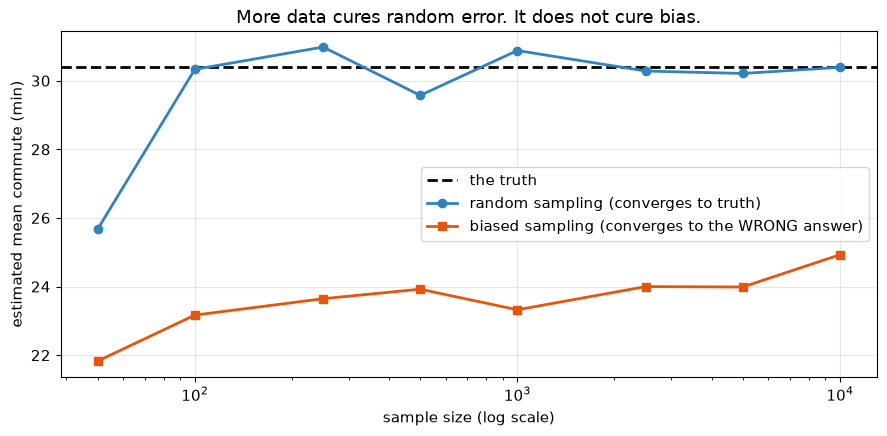

In [25]:
# Does collecting MORE data fix bias? Let's check directly -- this is worth seeing once.

sizes = [50, 100, 250, 500, 1000, 2500, 5000, 10000]
random_means, biased_means = [], []

for n in sizes:
    random_means.append(true_commute[rng.choice(len(true_commute), n, replace=False)].mean())
    biased_means.append(true_commute[rng.choice(len(true_commute), n, p=weights_short, replace=False)].mean())

fig, ax = plt.subplots()
ax.axhline(true_commute.mean(), color="black", linestyle="--", linewidth=2, label="the truth")
ax.plot(sizes, random_means, marker="o", color="#3182bd", linewidth=2,
        label="random sampling (converges to truth)")
ax.plot(sizes, biased_means, marker="s", color="#e6550d", linewidth=2,
        label="biased sampling (converges to the WRONG answer)")
ax.set_xscale("log")     # log scale because sizes span 50 to 10,000
ax.set_xlabel("sample size (log scale)")
ax.set_ylabel("estimated mean commute (min)")
ax.set_title("More data cures random error. It does not cure bias.")
ax.legend()
plt.tight_layout()
plt.show()


> ### Summary of Section 2
> - Ask of every dataset: **what instrument produced this, and what can it not see?**
> - Resolution, range, and noise each damage a *different* property of the data.
> - Sampling bias is not a small-sample problem. The orange line above never reaches the truth.
> - Slide 6 quotes Vivek Kundra: *"Release data even if it's imperfect."* Reasonable — as long as the
>   imperfections travel with the data. That is a job for **metadata** (Section 14).


---
---

# Section 3 — Why numbers matter (and why our brains fail at them)

**Slides 9, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22.**

The lecture's argument, compressed:

- There is **no computation without numbers** (slide 15). Data are made of counts, dollars,
  scientific notation.
- Numbers are a **language** (slide 16). Being fluent lets you contrast and interpret — greater,
  lesser, closer, farther.
- But the human brain **grasps small numbers easily and then goes hazy**: 1, 2, 3, 4, 5, … *lots*
  (slide 17). Millions vs. trillions, mega vs. zetta, micro vs. zepto all collapse into "big" and
  "small".
- Heath and Starr: *"Numbers are only fun if they make sense to everyone"* (slide 13).

The fix is a small set of habits: know the **prefixes**, learn to **estimate**, and **translate** big
figures onto a human scale. We will practise all three.


### 3.1 The SI prefixes

Slide 14 says you don't need to memorise *zettabyte* or *zeptosecond*, but you **do** need the
prefixes. Here is the full standard table. Two things to internalise:

- Each step is **1,000×** (three zeros), not 10×.
- The English words and the prefixes line up like this: **kilo = thousand, mega = million,
  giga = billion, tera = trillion.** Slide 18 states this directly: *1 Million = 1 Mega, 1 Billion =
  1 Giga.* Going down: **milli = thousandth, micro = millionth, nano = billionth, pico =
  trillionth.**

(If you have seen a table that pairs *giga* with "trillion" or *micro* with "one billionth", it has
slipped by one row. Use the exponents below as the authority — exponents never lie.)


In [26]:
# The SI prefixes as a Python dictionary: name -> (symbol, power of ten, everyday English word)
SI_PREFIXES = {
    "quetta": ("Q",  30, "nonillion"),
    "ronna":  ("R",  27, "octillion"),
    "yotta":  ("Y",  24, "septillion"),
    "zetta":  ("Z",  21, "sextillion"),
    "exa":    ("E",  18, "quintillion"),
    "peta":   ("P",  15, "quadrillion"),
    "tera":   ("T",  12, "trillion"),
    "giga":   ("G",   9, "billion"),
    "mega":   ("M",   6, "million"),
    "kilo":   ("k",   3, "thousand"),
    "(none)": ("",    0, "one"),
    "milli":  ("m",  -3, "thousandth"),
    "micro":  ("u",  -6, "millionth"),
    "nano":   ("n",  -9, "billionth"),
    "pico":   ("p", -12, "trillionth"),
    "femto":  ("f", -15, "quadrillionth"),
    "atto":   ("a", -18, "quintillionth"),
    "zepto":  ("z", -21, "sextillionth"),
    "yocto":  ("y", -24, "septillionth"),
}

# Turn the dictionary into a pandas table so it prints neatly.
si_table = pd.DataFrame(
    [(name, sym, exp, word, f"1e{exp}") for name, (sym, exp, word) in SI_PREFIXES.items()],
    columns=["prefix", "symbol", "power of 10", "English word", "as a number"],
)
print(si_table.to_string(index=False))


prefix symbol  power of 10  English word as a number
quetta      Q           30     nonillion        1e30
 ronna      R           27     octillion        1e27
 yotta      Y           24    septillion        1e24
 zetta      Z           21    sextillion        1e21
   exa      E           18   quintillion        1e18
  peta      P           15   quadrillion        1e15
  tera      T           12      trillion        1e12
  giga      G            9       billion         1e9
  mega      M            6       million         1e6
  kilo      k            3      thousand         1e3
(none)                   0           one         1e0
 milli      m           -3    thousandth        1e-3
 micro      u           -6     millionth        1e-6
  nano      n           -9     billionth        1e-9
  pico      p          -12    trillionth       1e-12
 femto      f          -15 quadrillionth       1e-15
  atto      a          -18 quintillionth       1e-18
 zepto      z          -21  sextillionth      

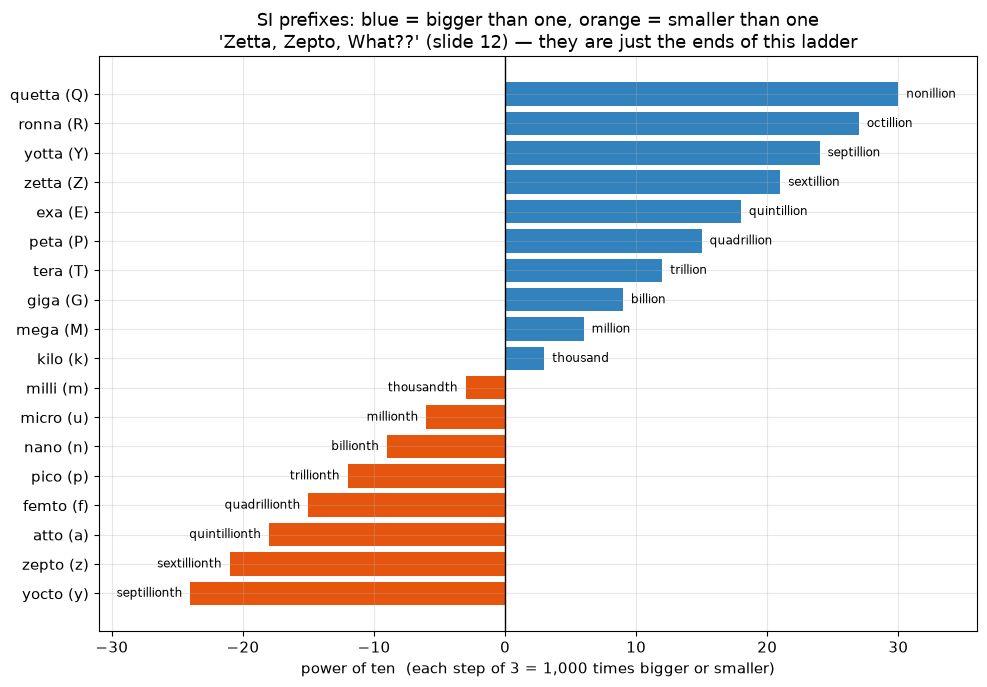

In [27]:
# Visualise the prefixes on a LOG scale. This is the only way to draw them on one chart at all:
# on a normal (linear) axis, "kilo" and "zetta" cannot coexist -- kilo would be an invisible speck.

names = [n for n in SI_PREFIXES if n != "(none)"]
exps  = [SI_PREFIXES[n][1] for n in names]
words = [SI_PREFIXES[n][2] for n in names]

fig, ax = plt.subplots(figsize=(10, 7))
bar_colours = ["#3182bd" if e > 0 else "#e6550d" for e in exps]
ax.barh(range(len(names)), exps, color=bar_colours)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(range(len(names)))
ax.set_yticklabels([f"{n} ({SI_PREFIXES[n][0]})" for n in names])
ax.invert_yaxis()
for i, (e, w) in enumerate(zip(exps, words)):
    offset = 0.6 if e > 0 else -0.6
    ax.text(e + offset, i, w, va="center", ha="left" if e > 0 else "right", fontsize=8.5)
ax.set_xlabel("power of ten  (each step of 3 = 1,000 times bigger or smaller)")
ax.set_xlim(-31, 36)
ax.set_title("SI prefixes: blue = bigger than one, orange = smaller than one\n"
             "'Zetta, Zepto, What??' (slide 12) — they are just the ends of this ladder")
plt.tight_layout()
plt.show()


In [28]:
# A function that converts any number into a readable prefixed string.
# This is genuinely useful; keep it.

def humanise(value, unit="", decimals=2):
    # Pick the largest SI prefix that leaves a number between 1 and 1000.
    if value == 0:
        return f"0 {unit}".strip()
    sign = "-" if value < 0 else ""
    value = abs(value)
    for name, (symbol, exp, word) in SI_PREFIXES.items():
        if value >= 10.0 ** exp:
            scaled = value / 10.0 ** exp
            return f"{sign}{scaled:.{decimals}f} {symbol}{unit}".strip()
    return f"{sign}{value:.{decimals}e} {unit}".strip()

# Try it on quantities straight from the lecture:
# NOTE: humanise() puts the prefix in front of the unit, the way scientists write it
# (2.5 EB, 45 um). For money we pass no unit and say "dollars" in words, because "T$" is not
# how anyone writes 27 trillion dollars.
examples = [
    (2.5e18,  "B/day", "2.5 quintillion bytes of data generated every day (Forbes, 2018)"),
    (175e21,  "B",     "175 zettabytes of data expected by 2025"),
    (1e-21,   "s",     "one zeptosecond (the unit 'Zepto' the grocery company is named for)"),
    (27e12,   "",      "US national debt IN DOLLARS (slide 20)"),
    (330e6,   "",      "US population, in people (slide 20)"),
    (303_255, "",      "population of Pittsburgh, in people"),
    (0.000_045, "m",   "diameter of a human hair, roughly"),
]
for value, unit, description in examples:
    print(f"{humanise(value, unit):>18}   <-  {description}")


       2.50 EB/day   <-  2.5 quintillion bytes of data generated every day (Forbes, 2018)
         175.00 ZB   <-  175 zettabytes of data expected by 2025
           1.00 zs   <-  one zeptosecond (the unit 'Zepto' the grocery company is named for)
           27.00 T   <-  US national debt IN DOLLARS (slide 20)
          330.00 M   <-  US population, in people (slide 20)
          303.25 k   <-  population of Pittsburgh, in people
          45.00 um   <-  diameter of a human hair, roughly


### 3.2 A million or a billion? (slide 18)

The slide's device: spend **\$100,000 a day**, every day, at a constant rate.

- \$1 **million** runs out in **10 days**.
- \$1 **billion** runs out in about **27 years**.

Same verb, same rate, same-sounding words — and a ratio of a thousand. Let's compute it, then draw
it, because the drawing is the part that sticks.


In [29]:
SPEND_PER_DAY = 100_000

for label, amount in [("$1 million", 1e6), ("$1 billion", 1e9), ("$1 trillion", 1e12)]:
    days = amount / SPEND_PER_DAY
    years = days / 365.25
    if years < 1:
        print(f"{label:>12}: {days:,.0f} days to spend it all")
    else:
        print(f"{label:>12}: {days:,.0f} days  =  {years:,.1f} years to spend it all")


  $1 million: 10 days to spend it all
  $1 billion: 10,000 days  =  27.4 years to spend it all
 $1 trillion: 10,000,000 days  =  27,378.5 years to spend it all


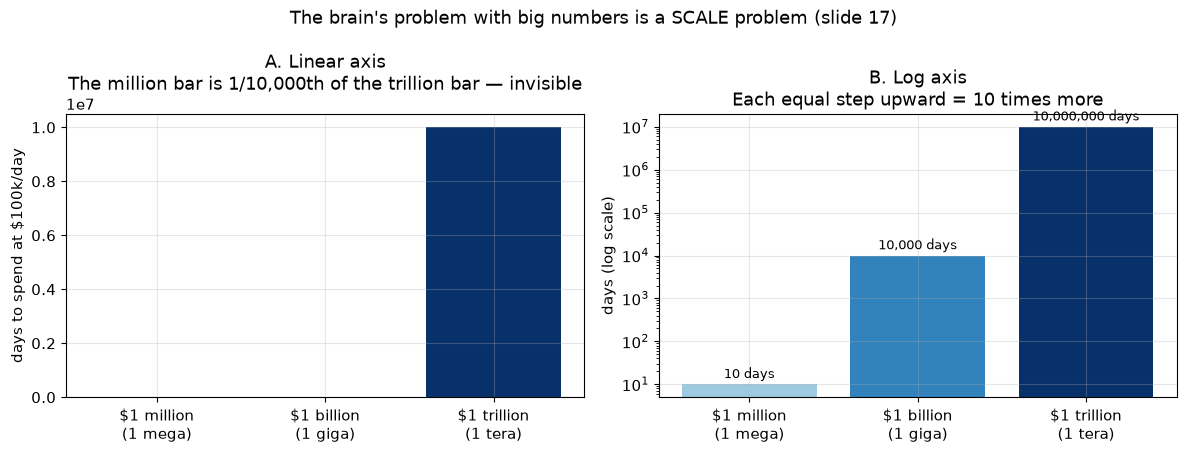

In [30]:
# Two ways to draw the same comparison. Panel A is honest and useless.
# Panel B is honest and useful. Understanding WHY is a core numeracy skill.

labels = ["$1 million\n(1 mega)", "$1 billion\n(1 giga)", "$1 trillion\n(1 tera)"]
values = np.array([1e6, 1e9, 1e12])
days   = values / SPEND_PER_DAY

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

ax1.bar(labels, days, color=["#9ecae1", "#3182bd", "#08306b"])
ax1.set_ylabel("days to spend at $100k/day")
ax1.set_title("A. Linear axis\nThe million bar is 1/10,000th of the trillion bar — invisible")

ax2.bar(labels, days, color=["#9ecae1", "#3182bd", "#08306b"])
ax2.set_yscale("log")
ax2.set_ylabel("days (log scale)")
ax2.set_title("B. Log axis\nEach equal step upward = 10 times more")
for i, d in enumerate(days):
    ax2.text(i, d * 1.4, f"{d:,.0f} days", ha="center", fontsize=9)

fig.suptitle("The brain's problem with big numbers is a SCALE problem (slide 17)", fontsize=13)
plt.tight_layout()
plt.show()


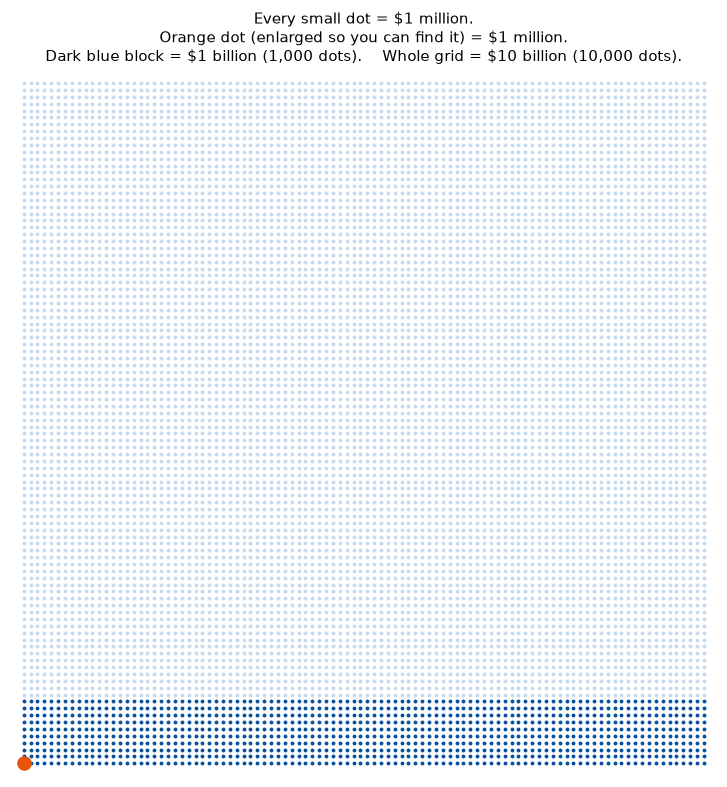

The orange dot had to be drawn OVERSIZE to be findable at all -- at its true scale it is
one of the pale specks.
And $1 trillion would need 100 grids like this one, side by side.
That is the gap the words 'million', 'billion', and 'trillion' hide.


In [31]:
# The dot-grid trick: draw 1,000 dots. Each dot is a million. The whole grid is a billion.
# This is the single most effective way to feel the million/billion gap.

fig, ax = plt.subplots(figsize=(8, 8))
side = 100                     # 100 x 100 = 10,000 dots
xs, ys = np.meshgrid(np.arange(side), np.arange(side))
ax.scatter(xs, ys, s=3, color="#c6dbef")

# Highlight the first 10 dots to represent one million out of one billion... except
# 1 billion / 1 million = 1,000 dots, so let each dot be a million and use 1,000 of them.
highlight = 1000
hx, hy = xs.ravel()[:highlight], ys.ravel()[:highlight]
ax.scatter(hx, hy, s=3, color="#08519c")
ax.scatter([xs.ravel()[0]], [ys.ravel()[0]], s=90, color="#e6550d", zorder=5)

ax.set_xlim(-2, side + 1)
ax.set_ylim(-2, side + 1)
ax.set_aspect("equal")
ax.axis("off")
# NOTE: matplotlib treats a $...$ pair as mathematical notation, so a chart title with
# several dollar amounts needs each one written as \$ inside a RAW string (the r"..." prefix)
# to print literally.
title_lines = [
    r"Every small dot = \$1 million.",
    r"Orange dot (enlarged so you can find it) = \$1 million.",
    r"Dark blue block = \$1 billion (1,000 dots).    Whole grid = \$10 billion (10,000 dots).",
]
ax.set_title("\n".join(title_lines), fontsize=11)
plt.tight_layout()
plt.show()

print("The orange dot had to be drawn OVERSIZE to be findable at all -- at its true scale it is")
print("one of the pale specks.")
print(f"And $1 trillion would need {1e12/1e6/10_000:,.0f} grids like this one, side by side.")
print("That is the gap the words 'million', 'billion', and 'trillion' hide.")


### 3.3 Learn to estimate (slide 19)

The slide's recipe: *start with a round number close to the target*, then adjust.

> 150% of 250 ≈ 250 + half of 250 = 250 + 125 = **375**
> The slide notes the exact answer is **391** — "close enough for a quick sense-check".

Read that carefully, because it is doing something subtle. 150% of exactly 250 is exactly 375. The
fact that the *real* answer was 391 tells you the actual quantity was not a round 250 (150% of 260.7
≈ 391) — the "250" was the round number we substituted in. The estimate lands within **about 4%** of
the truth, and it took two seconds and no calculator.

The skill is not "getting 375". The skill is **knowing how wrong you are allowed to be**. Let's
quantify that.


                             problem      estimate         exact  error %
 150% of 260.7  (slide 19's example)        375.00        391.05    -4.10
          18% tip on a $63.40 dinner         12.60         11.41    10.41
   Time to drive 137 miles at 62 mph          2.33          2.21     5.60
         31,412 students, 47% female     15,500.00     14,763.64     4.99
     Cost of 24 items at $18.75 each        475.00        450.00     5.56
7,900,000,000 people / 195 countries 40,000,000.00 40,512,820.51    -1.27


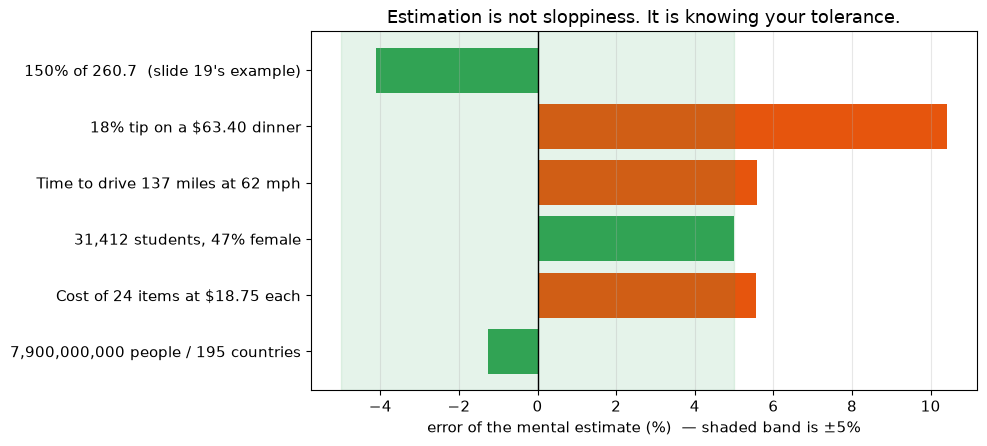

In [32]:
# Compare quick estimates against exact answers, and measure the error.

def percent_error(estimate, exact):
    # How far off is the estimate, as a percentage of the true value?
    return 100 * (estimate - exact) / exact

problems = [
    # (description,                          my quick estimate, the exact value)
    ("150% of 260.7  (slide 19's example)",   375,        391.05),
    ("18% tip on a $63.40 dinner",            0.20 * 63,  0.18 * 63.40),
    ("Time to drive 137 miles at 62 mph",     140 / 60,   137 / 62),
    ("31,412 students, 47% female",           31000*0.5,  31412 * 0.47),
    ("Cost of 24 items at $18.75 each",       25 * 19,    24 * 18.75),
    ("7,900,000,000 people / 195 countries",  8e9 / 200,  7.9e9 / 195),
]

rows = []
for desc, est, exact in problems:
    rows.append({"problem": desc, "estimate": est, "exact": exact,
                 "error %": percent_error(est, exact)})
estimation = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print(estimation.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.6))
err = estimation["error %"]
ax.barh(estimation["problem"], err, color=["#31a354" if abs(e) < 5 else "#e6550d" for e in err])
ax.axvline(0, color="black", linewidth=1)
for lo, hi, c in [(-5, 5, "#31a354")]:
    ax.axvspan(lo, hi, color=c, alpha=0.12)
ax.set_xlabel("error of the mental estimate (%)  — shaded band is ±5%")
ax.set_title("Estimation is not sloppiness. It is knowing your tolerance.")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
pd.reset_option("display.float_format")


**When ±5% is fine:** sanity-checking a computer's output, choosing between two options that differ
by 2×, deciding whether a claim is plausible in a news article.

**When it is not fine:** anything money is paid on, anything reported as a finding, anything where
the *difference* between two numbers is small compared to the numbers themselves. (If two candidates
poll at 47% and 49%, a 5% estimation error is larger than the entire result.)

Slide 22's homework — *practise slightly larger computations WITHOUT a calculator* — is really about
building the reflex that says "wait, that answer smells wrong". Code has no such reflex. You are the
reflex.


In [33]:
# A practice generator. Re-run this cell as many times as you like -- new problems every time.
# Try to estimate the answer in your head BEFORE you scroll to the printed solution.

practice_rng = np.random.default_rng()      # no seed: genuinely different each run

print("MENTAL MATH PRACTICE (slide 22). Estimate first, then check.\n")
for _ in range(6):
    kind = practice_rng.integers(0, 4)
    if kind == 0:
        pct, base = practice_rng.integers(5, 96), practice_rng.integers(200, 9000)
        print(f"  {pct}% of {base:,}  ...  answer: {pct/100*base:,.1f}")
    elif kind == 1:
        a, b = practice_rng.integers(12, 99), practice_rng.integers(12, 99)
        print(f"  {a} x {b}  ...  answer: {a*b:,}")
    elif kind == 2:
        total, people = practice_rng.integers(1, 90) * 1e9, practice_rng.integers(2, 400) * 1e6
        print(f"  ${total:,.0f} spread over {people:,.0f} people  ...  answer: ${total/people:,.2f} each")
    else:
        miles, mph = practice_rng.integers(40, 900), practice_rng.integers(25, 75)
        print(f"  {miles} miles at {mph} mph  ...  answer: {miles/mph:.2f} hours")


MENTAL MATH PRACTICE (slide 22). Estimate first, then check.

  44 x 41  ...  answer: 1,804
  17% of 479  ...  answer: 81.4
  65% of 8,248  ...  answer: 5,361.2
  $25,000,000,000 spread over 375,000,000 people  ...  answer: $66.67 each
  22 x 38  ...  answer: 836
  24% of 7,275  ...  answer: 1,746.0


### 3.4 Translate where possible (slide 20)

The slide's example:

| The abstract figure | The human-scale version |
|---|---|
| \$27 trillion — U.S. national debt | ≈ \$82,000 per person (pop. ≈ 330 million) |

"\$27 trillion" is a number nobody feels. "\$82,000 each" is a number everyone feels, because it is
comparable to things in your life: a car, a year of private tuition, a down payment. **Translation is
division by something human.**


$27 trillion / 330 million people = $81,818 per person   (slide 20)


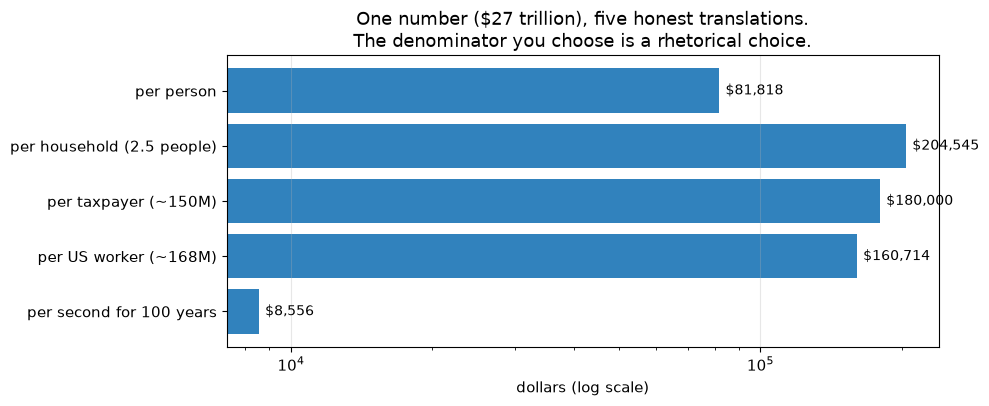

All five are arithmetically correct. 'Per taxpayer' sounds worse than 'per person'.
When you read a statistic in the news, always ask: divided by WHAT?


In [34]:
US_DEBT = 27e12
US_POP  = 330e6

per_person = US_DEBT / US_POP
print(f"$27 trillion / 330 million people = ${per_person:,.0f} per person   (slide 20)")

# Several other human-scale translations of the SAME number. Each one tells a different story.
translations = {
    "per person":                 US_DEBT / US_POP,
    "per household (2.5 people)": US_DEBT / (US_POP / 2.5),
    "per taxpayer (~150M)":       US_DEBT / 150e6,
    "per US worker (~168M)":      US_DEBT / 168e6,
    "per second for 100 years":   US_DEBT / (100 * 365.25 * 24 * 3600),
}
fig, ax = plt.subplots(figsize=(10, 4.2))
keys = list(translations)
vals = [translations[k] for k in keys]
ax.barh(keys, vals, color="#3182bd")
for i, v in enumerate(vals):
    ax.text(v * 1.03, i, f"${v:,.0f}", va="center", fontsize=10)
ax.set_xscale("log")
ax.set_xlabel("dollars (log scale)")
ax.set_title("One number ($27 trillion), five honest translations.\nThe denominator you choose is a rhetorical choice.")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("All five are arithmetically correct. 'Per taxpayer' sounds worse than 'per person'.")
print("When you read a statistic in the news, always ask: divided by WHAT?")


In [35]:
# A reusable translation helper you can point at any big number.

def translate(total, denominators, unit="$"):
    # denominators: dictionary of {name: count}
    print(f"{unit}{total:,.0f} translated:")
    for name, count in denominators.items():
        print(f"   {unit}{total/count:>14,.2f}  per {name}")

# Try it on the lecture's data-volume figures (slide 12).
translate(2.5e18, {"person on Earth (8.1 billion)": 8.1e9,
                   "second in a day": 86_400,
                   "smartphone on Earth (~7 billion)": 7e9}, unit="")


2,500,000,000,000,000,000 translated:
   308,641,975.31  per person on Earth (8.1 billion)
   28,935,185,185,185.18  per second in a day
   357,142,857.14  per smartphone on Earth (~7 billion)


### 3.5 Place values and scientific notation (slide 22)

Slide 22 asks you to get comfortable with **place values** (… 1/1000, 1/100, …, 1000, 10000 …) and to
**revisit scientific notation**. These are the same idea seen from two directions: every number is a
sum of powers of ten.


In [36]:
# Decompose a number into its place values.

def show_place_values(x):
    print(f"The number {x:,}")
    s = f"{abs(x):.4f}"
    whole, frac = s.split(".")
    for i, digit in enumerate(whole):
        power = len(whole) - 1 - i
        print(f"   digit {digit}  x  10^{power:<3} = {int(digit) * 10**power:>15,}")
    for i, digit in enumerate(frac):
        power = -(i + 1)
        if digit != "0":
            print(f"   digit {digit}  x  10^{power:<3} = {int(digit) * 10.0**power:>15.4f}")

show_place_values(12345.678)

print("\nThe same number in scientific notation:")
x = 12345.678
print(f"   {x:.4e}      <- 'e' means 'times ten to the power of'")
print(f"   readable    : {humanise(x)}")

print("\nWhy scientific notation earns its keep -- these are all real quantities from the lecture:")
for v in [2.5e18, 175e21, 1e-21, 27e12, 8e9, 6.022e23, 1.6e-19]:
    print(f"   {v:>12.3e}   =  {humanise(v)}")


The number 12,345.678
   digit 1  x  10^4   =          10,000
   digit 2  x  10^3   =           2,000
   digit 3  x  10^2   =             300
   digit 4  x  10^1   =              40
   digit 5  x  10^0   =               5
   digit 6  x  10^-1  =          0.6000
   digit 7  x  10^-2  =          0.0700
   digit 8  x  10^-3  =          0.0080

The same number in scientific notation:
   1.2346e+04      <- 'e' means 'times ten to the power of'
   readable    : 12.35 k

Why scientific notation earns its keep -- these are all real quantities from the lecture:
      2.500e+18   =  2.50 E
      1.750e+23   =  175.00 Z
      1.000e-21   =  1.00 z
      2.700e+13   =  27.00 T
      8.000e+09   =  8.00 G
      6.022e+23   =  602.20 Z
      1.600e-19   =  160.00 z


175 ZB / 2.5 EB per day = 70,000 days = 191.6 years
...at a CONSTANT rate. But the slide says 'and rising'. Rates that rise change everything:


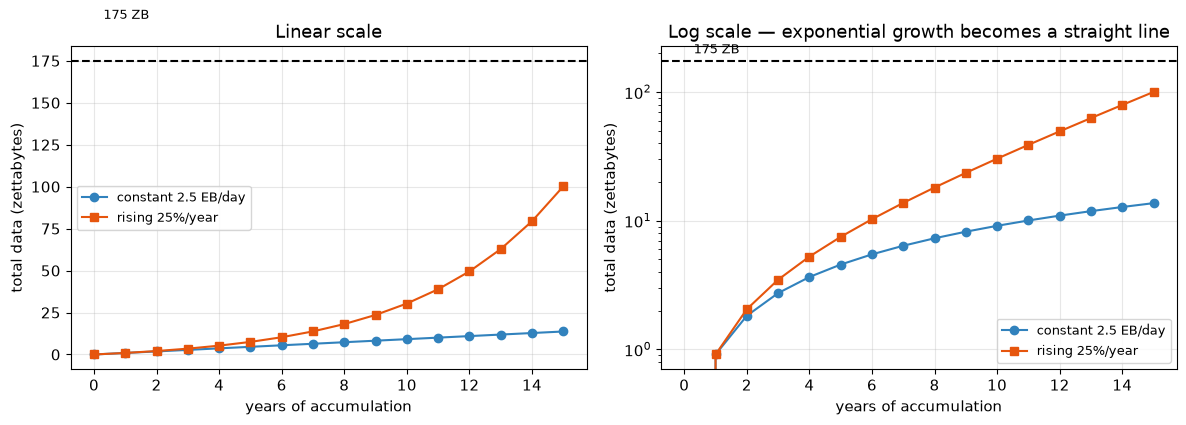

In [37]:
# The data explosion (slide 12): 2.5 quintillion bytes/day, 175 zettabytes expected.
# How long does it take to accumulate 175 zettabytes at 2.5 quintillion bytes per day?

BYTES_PER_DAY = 2.5e18          # 2.5 quintillion = 2.5 exabytes per day
TARGET        = 175e21          # 175 zettabytes

days_needed = TARGET / BYTES_PER_DAY
print(f"175 ZB / 2.5 EB per day = {days_needed:,.0f} days = {days_needed/365.25:,.1f} years")
print("...at a CONSTANT rate. But the slide says 'and rising'. Rates that rise change everything:")

years = np.arange(0, 16)
constant  = BYTES_PER_DAY * 365.25 * years                       # linear growth
growing   = BYTES_PER_DAY * 365.25 * ((1.25 ** years - 1) / 0.25) # 25% more each year (compounding)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, logscale in [(ax1, False), (ax2, True)]:
    ax.plot(years, constant / 1e21, marker="o", color="#3182bd", label="constant 2.5 EB/day")
    ax.plot(years, growing / 1e21, marker="s", color="#e6550d", label="rising 25%/year")
    ax.axhline(175, color="black", linestyle="--", linewidth=1.5)
    ax.text(0.3, 200, "175 ZB", fontsize=9)
    ax.set_xlabel("years of accumulation")
    ax.set_ylabel("total data (zettabytes)")
    if logscale:
        ax.set_yscale("log")
        ax.set_title("Log scale — exponential growth becomes a straight line")
    else:
        ax.set_title("Linear scale")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


The right-hand panel demonstrates a rule you can carry into any social-science reading:
**on a log axis, exponential growth is a straight line.** If someone shows you a curve that looks
frighteningly steep, check the axis. If it is linear, the steepness may just be compounding. If they
show it on a log axis and it is *still* curving upward, then something genuinely faster than
exponential is happening.

> ### Summary of Section 3
> - Prefixes go in steps of 1,000. kilo–mega–giga–tera = thousand–million–billion–trillion.
> - Log scales exist because the brain's number sense is roughly logarithmic anyway.
> - Estimate first; know your tolerance; treat exact answers with suspicion until they pass a smell test.
> - Translate abstract figures by dividing by something human — and notice that *which* human
>   denominator you pick is an argument, not a fact.

---
---

# Section 4 — Rates, ratios, odds (slide 21)

The slide lists more types of number, each with a signature:

| Type | Signature | The slide's example |
|---|---|---|
| **Rate** | the word **"per"** | 60 miles per hour; 10% per annum |
| **Ratio** | an implicit comparison | 2/3 of the park was consumed by flames |
| **Odds** | a special ratio of probabilities | odds are 2 to 1 that Ms. X wins the primaries |
| **…and more** | areas, volumes, weights, energy, temperature, **N-grams** | e.g. the Google N-Gram Viewer |

These are constantly confused in public discourse — often on purpose. Let's make each one behave.


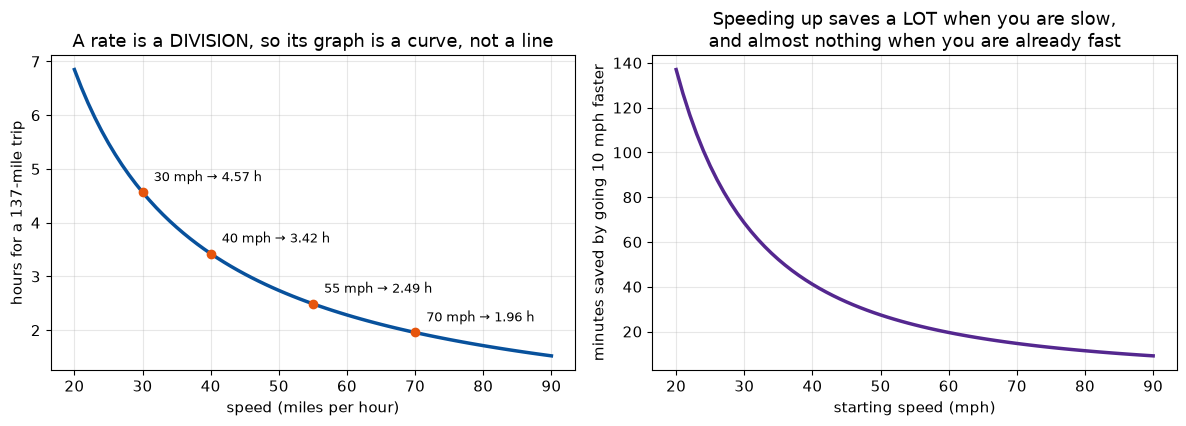

At 25 mph, +10 mph saves 94 minutes.
At 75 mph, +10 mph saves 13 minutes.


In [38]:
# RATES: anything with 'per'. The key property is that rates and totals are NOT proportional
# in the way people expect -- doubling speed does not halve a trip you have already started.

def travel_time_hours(miles, mph):
    return miles / mph

distance = 137
speeds = np.arange(20, 91, 1)
times = travel_time_hours(distance, speeds)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

ax1.plot(speeds, times, color="#08519c", linewidth=2.5)
for mph in [30, 40, 55, 70]:
    t = travel_time_hours(distance, mph)
    ax1.plot([mph], [t], "o", color="#e6550d")
    ax1.annotate(f"{mph} mph → {t:.2f} h", (mph, t), textcoords="offset points",
                 xytext=(8, 8), fontsize=9)
ax1.set_xlabel("speed (miles per hour)")
ax1.set_ylabel("hours for a 137-mile trip")
ax1.set_title("A rate is a DIVISION, so its graph is a curve, not a line")

# The counter-intuitive bit: minutes SAVED by driving 10 mph faster.
saved = (travel_time_hours(distance, speeds) - travel_time_hours(distance, speeds + 10)) * 60
ax2.plot(speeds, saved, color="#54278f", linewidth=2.5)
ax2.set_xlabel("starting speed (mph)")
ax2.set_ylabel("minutes saved by going 10 mph faster")
ax2.set_title("Speeding up saves a LOT when you are slow,\nand almost nothing when you are already fast")
plt.tight_layout()
plt.show()

print("At 25 mph, +10 mph saves", f"{(travel_time_hours(distance,25)-travel_time_hours(distance,35))*60:.0f}", "minutes.")
print("At 75 mph, +10 mph saves", f"{(travel_time_hours(distance,75)-travel_time_hours(distance,85))*60:.0f}", "minutes.")


Park size          : 1,240 acres
Burned (2/3)       : 827 acres
As a percentage    : 66.7%
As a ratio         : 827 : 413  (burned : unburned)
As 'x out of 10'   : about 6.7 out of every 10 acres


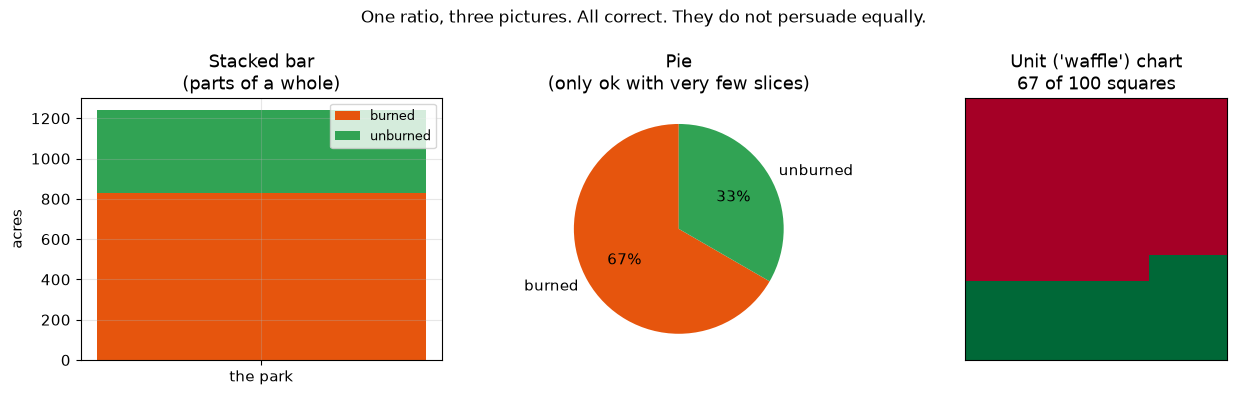

In [39]:
# RATIOS: '2/3 of the park was consumed by flames' (slide 21).
# A ratio needs a WHOLE. Half the confusion in public statistics is a missing denominator.

park_acres = 1_240
burned_fraction = 2 / 3
burned = park_acres * burned_fraction

print(f"Park size          : {park_acres:,} acres")
print(f"Burned (2/3)       : {burned:,.0f} acres")
print(f"As a percentage    : {burned_fraction * 100:.1f}%")
print(f"As a ratio         : {burned:.0f} : {park_acres - burned:.0f}  (burned : unburned)")
print(f"As 'x out of 10'   : about {burned_fraction * 10:.1f} out of every 10 acres")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4))

# (a) Stacked bar -- best for showing parts of one whole.
ax1.bar(["the park"], [burned], color="#e6550d", label="burned")
ax1.bar(["the park"], [park_acres - burned], bottom=[burned], color="#31a354", label="unburned")
ax1.set_ylabel("acres")
ax1.set_title("Stacked bar\n(parts of a whole)")
ax1.legend(fontsize=9)

# (b) Pie -- fine for ONE two-or-three-part comparison, bad for anything more.
ax2.pie([burned, park_acres - burned], labels=["burned", "unburned"],
        colors=["#e6550d", "#31a354"], autopct="%1.0f%%", startangle=90)
ax2.set_title("Pie\n(only ok with very few slices)")

# (c) A waffle/unit chart -- 100 squares, each 1%. Often the clearest of the three for a lay reader.
grid = np.zeros((10, 10))
n_burned_cells = int(round(burned_fraction * 100))
grid.ravel()[:n_burned_cells] = 1
ax3.imshow(grid, cmap="RdYlGn_r", vmin=0, vmax=1)
ax3.set_xticks([]); ax3.set_yticks([])
ax3.grid(visible=False)
ax3.set_title(f"Unit ('waffle') chart\n{n_burned_cells} of 100 squares")

fig.suptitle("One ratio, three pictures. All correct. They do not persuade equally.", fontsize=12)
plt.tight_layout()
plt.show()


### 4.1 Odds are not probabilities

The slide calls odds *"a special ratio of probabilities"*, and this is where most people slip.

- **Probability** = favourable outcomes ÷ **all** outcomes. Always between 0 and 1.
- **Odds** = favourable ÷ **unfavourable**. Between 0 and infinity.

"Odds are 2 to 1 that Ms. X wins" means she wins twice for every once she loses — a probability of
2/3 ≈ 67%, *not* 2/2 = 100% and not 2/1 = 200%. The conversions:

$$\text{odds} = \frac{p}{1-p} \qquad\qquad p = \frac{\text{odds}}{1+\text{odds}}$$


Slide 21: 'odds are 2 to 1 that Ms. X wins the primaries'
   odds 2:1  ->  probability 66.7%

 probability  odds (x : 1) stated as
      0.0100          0.01  1 to 100
      0.1000          0.11    1 to 9
      0.2500          0.33    1 to 3
      0.5000          1.00    1 to 1
      0.6667          2.00    2 to 1
      0.7500          3.00    3 to 1
      0.9000          9.00    9 to 1
      0.9500         19.00   19 to 1
      0.9900         99.00   99 to 1


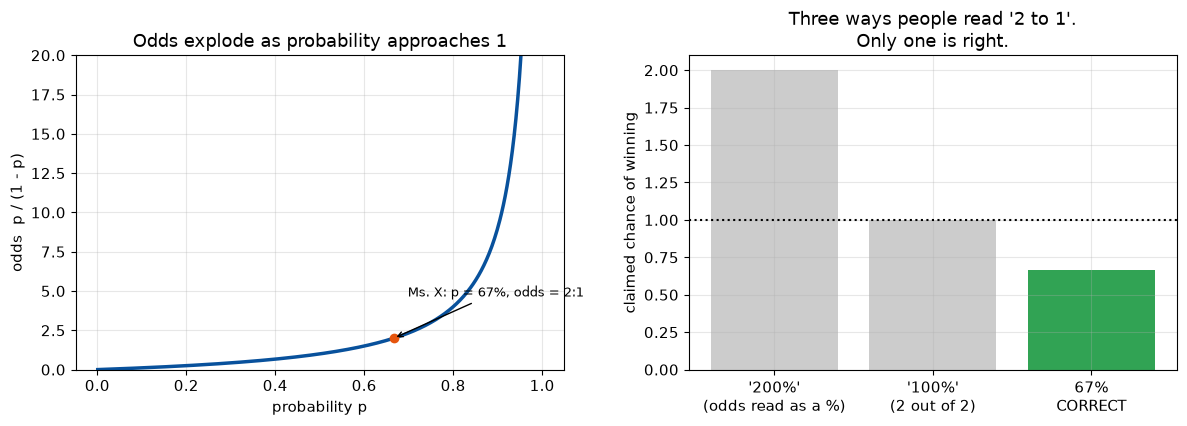

In [40]:
def prob_to_odds(p):
    return p / (1 - p)

def odds_to_prob(odds):
    return odds / (1 + odds)

print("Slide 21: 'odds are 2 to 1 that Ms. X wins the primaries'")
print(f"   odds 2:1  ->  probability {odds_to_prob(2):.1%}\n")

table = pd.DataFrame({"probability": [0.01, 0.10, 0.25, 0.50, 0.6667, 0.75, 0.90, 0.95, 0.99]})
table["odds (x : 1)"] = prob_to_odds(table["probability"]).round(2)
table["stated as"] = [f"{o:.0f} to 1" if o >= 1 else f"1 to {1/o:.0f}"
                      for o in table["odds (x : 1)"]]
print(table.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
p_grid = np.linspace(0.001, 0.999, 500)
ax1.plot(p_grid, prob_to_odds(p_grid), color="#08519c", linewidth=2.5)
ax1.set_ylim(0, 20)
ax1.set_xlabel("probability p")
ax1.set_ylabel("odds  p / (1 - p)")
ax1.set_title("Odds explode as probability approaches 1")
ax1.plot([2/3], [2], "o", color="#e6550d")
ax1.annotate("Ms. X: p = 67%, odds = 2:1", (2/3, 2), textcoords="offset points",
             xytext=(10, 30), fontsize=9, arrowprops=dict(arrowstyle="->"))

# The common error: reading '2 to 1' as if it were a probability.
wrong = [2/1, 2/2, odds_to_prob(2)]
ax2.bar(["'200%'\n(odds read as a %)", "'100%'\n(2 out of 2)", "67%\nCORRECT"],
        wrong, color=["#cccccc", "#cccccc", "#31a354"])
ax2.axhline(1.0, color="black", linestyle=":")
ax2.set_ylabel("claimed chance of winning")
ax2.set_title("Three ways people read '2 to 1'.\nOnly one is right.")
plt.tight_layout()
plt.show()


From 4% to 5%:
   an increase of 1 PERCENTAGE POINT
   an increase of 25 PERCENT
Both sentences are true. A headline can pick whichever sounds better.



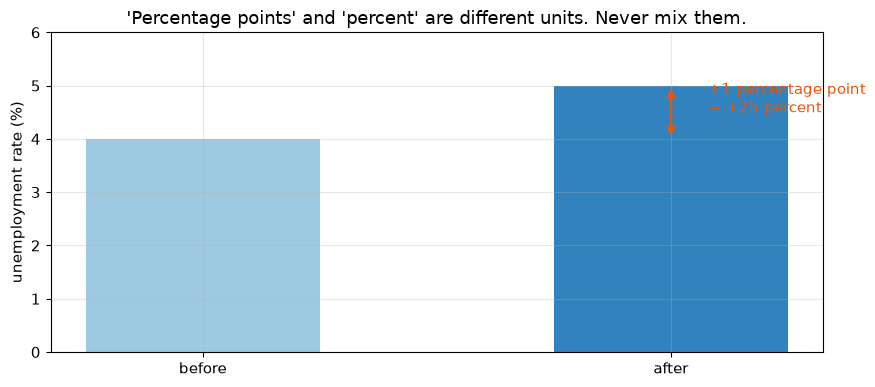

In [41]:
# One more number trap worth immunising against: percent CHANGE vs percentage POINTS.
# This appears constantly in polling, unemployment, and vote-share reporting.

before, after = 0.04, 0.05       # e.g. unemployment goes from 4% to 5%

points_change  = (after - before) * 100          # 1 percentage point
percent_change = (after - before) / before * 100 # 25 percent

print(f"From {before:.0%} to {after:.0%}:")
print(f"   an increase of {points_change:.0f} PERCENTAGE POINT")
print(f"   an increase of {percent_change:.0f} PERCENT")
print("Both sentences are true. A headline can pick whichever sounds better.\n")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(["before", "after"], [before * 100, after * 100], color=["#9ecae1", "#3182bd"], width=0.5)
ax.set_ylabel("unemployment rate (%)")
ax.set_ylim(0, 6)
ax.annotate("", xy=(1, after*100), xytext=(1, before*100),
            arrowprops=dict(arrowstyle="<->", color="#e6550d", linewidth=2))
ax.text(1.08, 4.5, "+1 percentage point\n= +25 percent", color="#e6550d", fontsize=11)
ax.set_title("'Percentage points' and 'percent' are different units. Never mix them.")
plt.tight_layout()
plt.show()


> ### Summary of Section 4
> - **"per"** signals a rate; rates graph as curves, and their effects are non-linear.
> - A ratio is meaningless without stating the whole. Always find the denominator.
> - **Odds ≠ probability.** 2-to-1 is 67%.
> - Percentage points and percent are different units, and the difference is exploitable.

---
---

# Section 5 — The same numbers, sliced three different ways

**Slide 11** points at a *Math With Bad Drawings* post: the finances of the American household in
three charts — **assets**, **liabilities**, and **creditors** (to whom the household owes money).
The slide's own description is the lesson: *"a light-hearted look at how the same numbers get sliced
three different ways."*

We will do it literally. One dataset. Three charts. Three impressions.


In [42]:
# An illustrative household balance sheet (round numbers, for teaching -- not real statistics).
assets = pd.Series({
    "primary home":        340_000,
    "retirement accounts": 195_000,
    "vehicles":             38_000,
    "cash & deposits":      21_000,
    "other investments":    46_000,
})
liabilities = pd.Series({
    "mortgage":         238_000,
    "student loans":     34_000,
    "auto loan":         19_000,
    "credit cards":       9_500,
    "medical debt":       4_200,
})
# The SAME liabilities, regrouped by WHO is owed rather than WHAT was bought.
creditors = pd.Series({
    "banks & mortgage servicers": 238_000 + 19_000,
    "federal government":          34_000,
    "card issuers":                 9_500,
    "hospitals & providers":        4_200,
})

print(f"Total assets      : ${assets.sum():,}")
print(f"Total liabilities : ${liabilities.sum():,}")
print(f"Net worth         : ${assets.sum() - liabilities.sum():,}")
print(f"\nLiabilities and creditors are the same money: "
      f"${liabilities.sum():,} vs ${creditors.sum():,}")


Total assets      : $640,000
Total liabilities : $304,700
Net worth         : $335,300

Liabilities and creditors are the same money: $304,700 vs $304,700


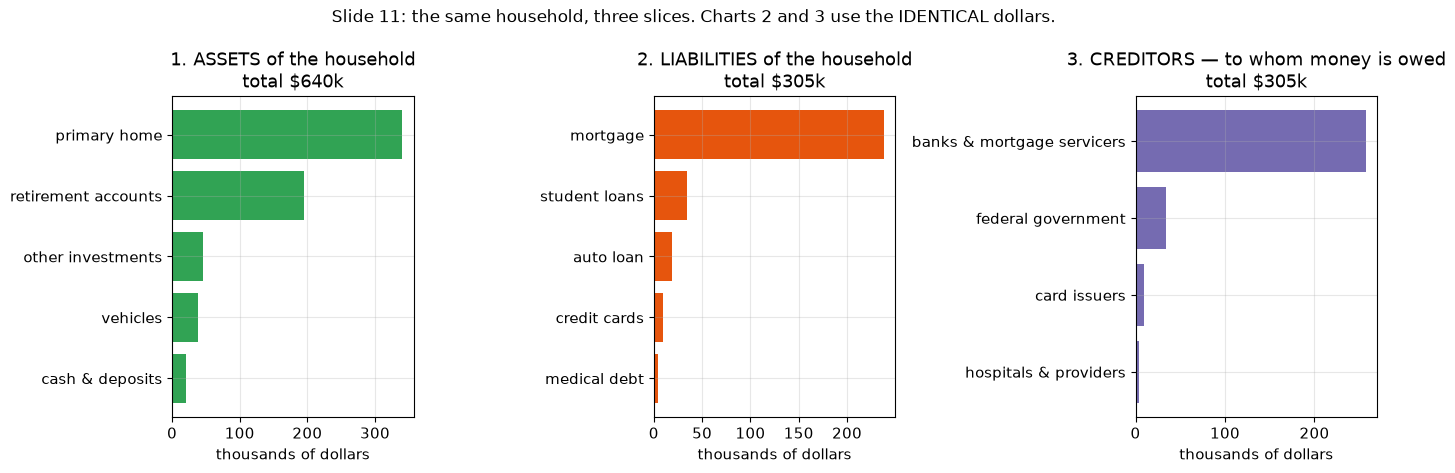

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))

# CHART 1 -- assets. Impression: "this household is doing fine."
a = assets.sort_values()
axes[0].barh(a.index, a.values / 1000, color="#31a354")
axes[0].set_xlabel("thousands of dollars")
axes[0].set_title(f"1. ASSETS of the household\ntotal ${assets.sum()/1000:,.0f}k")

# CHART 2 -- liabilities. Impression: "this household is drowning in debt."
l = liabilities.sort_values()
axes[1].barh(l.index, l.values / 1000, color="#e6550d")
axes[1].set_xlabel("thousands of dollars")
axes[1].set_title(f"2. LIABILITIES of the household\ntotal ${liabilities.sum()/1000:,.0f}k")

# CHART 3 -- creditors. Impression: "look who actually holds the household."
c = creditors.sort_values()
axes[2].barh(c.index, c.values / 1000, color="#756bb1")
axes[2].set_xlabel("thousands of dollars")
axes[2].set_title(f"3. CREDITORS — to whom money is owed\ntotal ${creditors.sum()/1000:,.0f}k")

fig.suptitle("Slide 11: the same household, three slices. Charts 2 and 3 use the IDENTICAL dollars.",
             fontsize=12)
plt.tight_layout()
plt.show()


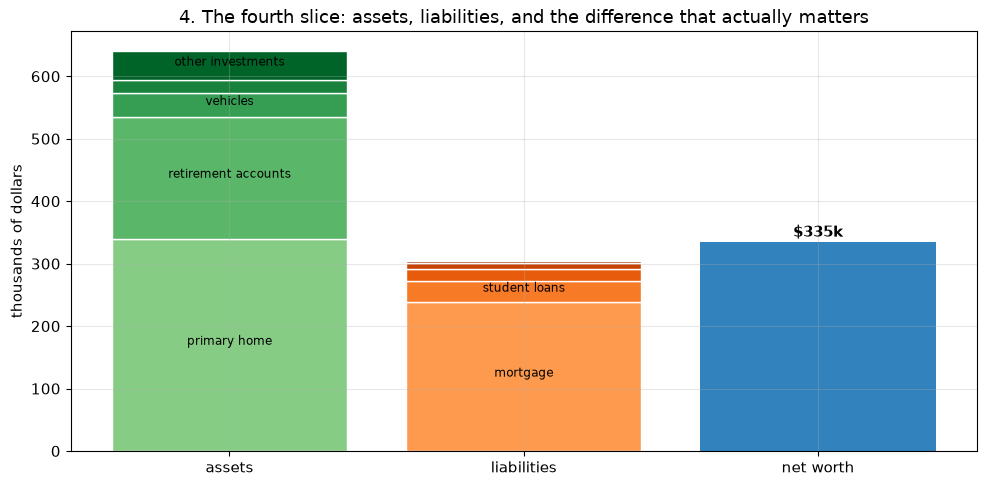

Ask, every time you see a chart: which slice is this, and which slice is MISSING?


In [44]:
# A fourth slice: put assets and liabilities side by side and show the net.
# This is the only one of the four that answers "how is this household actually doing?"

fig, ax = plt.subplots(figsize=(10, 5))

bottom_a, bottom_l = 0, 0
greens = plt.cm.Greens(np.linspace(0.45, 0.9, len(assets)))
oranges = plt.cm.Oranges(np.linspace(0.45, 0.9, len(liabilities)))

for (name, value), colour in zip(assets.items(), greens):
    ax.bar("assets", value / 1000, bottom=bottom_a / 1000, color=colour, edgecolor="white")
    if value > 30_000:
        ax.text(0, (bottom_a + value / 2) / 1000, name, ha="center", fontsize=8.5)
    bottom_a += value

for (name, value), colour in zip(liabilities.items(), oranges):
    ax.bar("liabilities", value / 1000, bottom=bottom_l / 1000, color=colour, edgecolor="white")
    if value > 30_000:
        ax.text(1, (bottom_l + value / 2) / 1000, name, ha="center", fontsize=8.5)
    bottom_l += value

net = (assets.sum() - liabilities.sum()) / 1000
ax.bar("net worth", net, color="#3182bd")
ax.text(2, net + 8, f"${net:,.0f}k", ha="center", fontsize=11, fontweight="bold")

ax.set_ylabel("thousands of dollars")
ax.set_title("4. The fourth slice: assets, liabilities, and the difference that actually matters")
plt.tight_layout()
plt.show()

print("Ask, every time you see a chart: which slice is this, and which slice is MISSING?")


> ### Summary of Section 5
> Nothing in charts 1–3 is false or manipulated. The *choice of slice* did all the persuading. This is
> the most transferable single habit in this notebook: when you meet a statistic, ask what the other
> slices of the same numbers would look like.


---
---

# Section 6 — What "computers" use: bits, bytes, hexadecimal, qubits

**Slide 23.** The slide gives one worked example:

> Binary / Hexadecimal — `8B` — `1 0 0 0 1 0 1 1` — where `8 = 1000` and `B = 1011`

and recommends practising on Khan Academy (converting binary ↔ decimal, adding in binary, storing
text in binary). Let's do all of that here.

**Why a social scientist should care.** Every number in every dataset you will ever analyse is stored
as bits. That storage has a *finite size*, which means it has finite **resolution** and finite
**range** — exactly the instrument limitations from Section 2, now baked into the computer itself.
Rounding errors in survey weights, dates that break in 2038, IDs that collide: all of these are
bit-level facts leaking into social-science results.


In [45]:
# Python speaks all three bases natively.

n = 139

print(f"decimal      : {n}")
print(f"binary       : {bin(n)}        (the '0b' prefix just means 'this is binary')")
print(f"binary, 8-bit: {n:08b}")
print(f"hexadecimal  : {hex(n)}        (the '0x' prefix means 'this is hex')")
print(f"hex, upper   : {n:X}")
print()

# ...and back again. int(text, base) reads a string written in the given base.
print("int('10001011', 2) =", int("10001011", 2))
print("int('8B', 16)      =", int("8B", 16))
print()
print("So slide 23's example checks out: 8B (hex) = 10001011 (binary) = 139 (decimal).")
print(f"   the '8' is the high nibble: {int('8',16):04b}")
print(f"   the 'B' is the low  nibble: {int('B',16):04b}")


decimal      : 139
binary       : 0b10001011        (the '0b' prefix just means 'this is binary')
binary, 8-bit: 10001011
hexadecimal  : 0x8b        (the '0x' prefix means 'this is hex')
hex, upper   : 8B

int('10001011', 2) = 139
int('8B', 16)      = 139

So slide 23's example checks out: 8B (hex) = 10001011 (binary) = 139 (decimal).
   the '8' is the high nibble: 1000
   the 'B' is the low  nibble: 1011


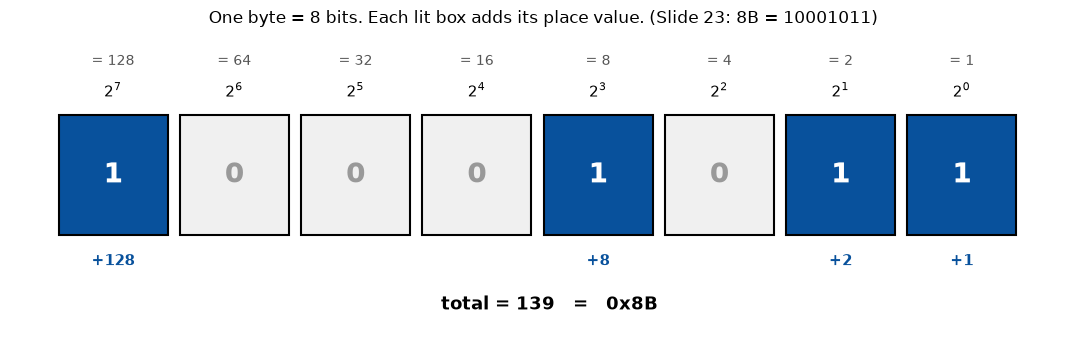

In [46]:
# Draw one byte as eight boxes with their place values. This makes binary click for most people.

value = 139
bits = [int(b) for b in f"{value:08b}"]
powers = [2 ** (7 - i) for i in range(8)]

fig, ax = plt.subplots(figsize=(11, 3.6))
for i, (bit, power) in enumerate(zip(bits, powers)):
    on = bit == 1
    ax.add_patch(plt.Rectangle((i, 0), 0.9, 1,
                               facecolor="#08519c" if on else "#f0f0f0",
                               edgecolor="black", linewidth=1.5))
    ax.text(i + 0.45, 0.5, str(bit), ha="center", va="center", fontsize=20,
            color="white" if on else "#999999", fontweight="bold")
    ax.text(i + 0.45, 1.15, f"$2^{{{7-i}}}$", ha="center", fontsize=11)
    ax.text(i + 0.45, 1.42, f"= {power}", ha="center", fontsize=10, color="#555")
    if on:
        ax.text(i + 0.45, -0.25, f"+{power}", ha="center", fontsize=11, color="#08519c",
                fontweight="bold")

ax.text(4.05, -0.62, f"total = {value}   =   0x{value:X}", ha="center", fontsize=13,
        fontweight="bold")
ax.set_xlim(-0.4, 8.4)
ax.set_ylim(-0.85, 1.7)
ax.axis("off")
ax.set_title("One byte = 8 bits. Each lit box adds its place value. (Slide 23: 8B = 10001011)",
             fontsize=12)
plt.tight_layout()
plt.show()


In [47]:
# The 0-15 reference table. Learn this and hex stops being mysterious:
# one hex digit == exactly four bits ("a nibble").

ref = pd.DataFrame({
    "decimal": range(16),
    "binary (4-bit)": [f"{i:04b}" for i in range(16)],
    "hex": [f"{i:X}" for i in range(16)],
})
print(ref.to_string(index=False))
print("\nThis is why programmers like hex: two hex digits = one byte, exactly. No arithmetic needed.")


 decimal binary (4-bit) hex
       0           0000   0
       1           0001   1
       2           0010   2
       3           0011   3
       4           0100   4
       5           0101   5
       6           0110   6
       7           0111   7
       8           1000   8
       9           1001   9
      10           1010   A
      11           1011   B
      12           1100   C
      13           1101   D
      14           1110   E
      15           1111   F

This is why programmers like hex: two hex digits = one byte, exactly. No arithmetic needed.


In [48]:
# Storing text in binary (slide 23's last suggestion).
# Every character has a number (its 'code point'); that number is stored as bits.

word = "Data"
print(f"The word: {word!r}\n")
for ch in word:
    print(f"   '{ch}'  ->  code point {ord(ch):>3}  ->  binary {ord(ch):08b}  ->  hex {ord(ch):02X}")

encoded = word.encode("utf-8")     # turn text into actual bytes
print(f"\nAs raw bytes  : {list(encoded)}")
print(f"As a bit string: {' '.join(f'{b:08b}' for b in encoded)}")
print(f"Storage cost   : {len(encoded)} bytes = {len(encoded)*8} bits")

# Non-English characters cost more bytes in UTF-8. This matters for text-heavy social science.
for sample in ["Data", "Datos", "données", "データ", "معلومات"]:
    b = sample.encode("utf-8")
    print(f"   {sample:>10}  {len(sample):>2} characters  ->  {len(b):>2} bytes in UTF-8")


The word: 'Data'

   'D'  ->  code point  68  ->  binary 01000100  ->  hex 44
   'a'  ->  code point  97  ->  binary 01100001  ->  hex 61
   't'  ->  code point 116  ->  binary 01110100  ->  hex 74
   'a'  ->  code point  97  ->  binary 01100001  ->  hex 61

As raw bytes  : [68, 97, 116, 97]
As a bit string: 01000100 01100001 01110100 01100001
Storage cost   : 4 bytes = 32 bits
         Data   4 characters  ->   4 bytes in UTF-8
        Datos   5 characters  ->   5 bytes in UTF-8
      données   7 characters  ->   8 bytes in UTF-8
          データ   3 characters  ->   9 bytes in UTF-8
      معلومات   7 characters  ->  14 bytes in UTF-8


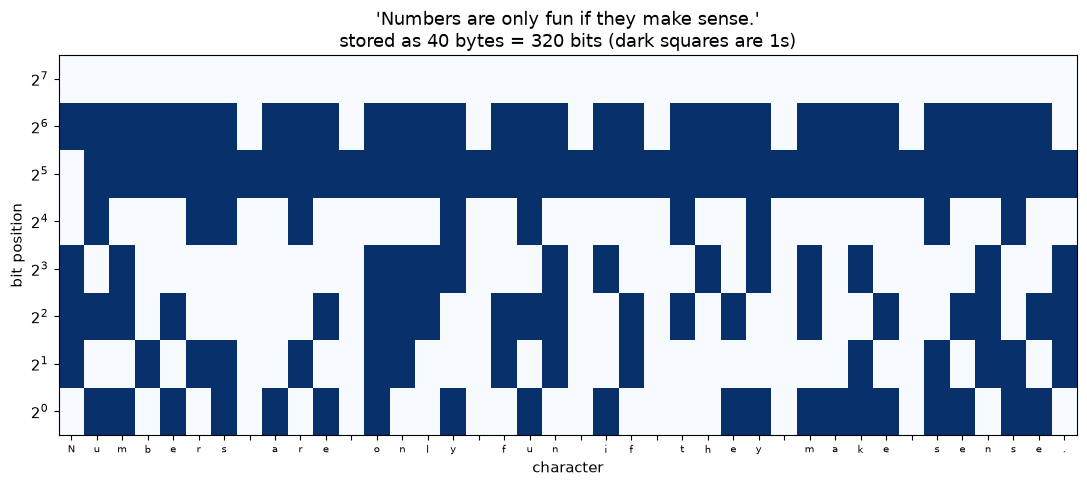

Notice the vertical stripes: the top rows are nearly constant, because all these
characters live in a narrow numeric range. Structure in data is visible even at the bit level.


In [49]:
# Visualise a sentence as a grid of bits. Dark = 1, light = 0.
# This is, quite literally, what a text file looks like to a machine.

sentence = "Numbers are only fun if they make sense."
byte_values = list(sentence.encode("utf-8"))
bit_matrix = np.array([[int(b) for b in f"{v:08b}"] for v in byte_values])

fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow(bit_matrix.T, cmap="Blues", aspect="auto", interpolation="nearest")
ax.set_yticks(range(8))
ax.set_yticklabels([f"$2^{{{7-i}}}$" for i in range(8)])
ax.set_xticks(range(len(sentence)))
ax.set_xticklabels(list(sentence), fontsize=7)
ax.set_xlabel("character")
ax.set_ylabel("bit position")
ax.grid(visible=False)
ax.set_title(f"'{sentence}'\nstored as {len(byte_values)} bytes = {len(byte_values)*8} bits "
             "(dark squares are 1s)")
plt.tight_layout()
plt.show()

print("Notice the vertical stripes: the top rows are nearly constant, because all these")
print("characters live in a narrow numeric range. Structure in data is visible even at the bit level.")


   yes / no                                     2 values  ->   1 bit(s)  (1 byte(s))
   days of the week                             7 values  ->   3 bit(s)  (1 byte(s))
   US states                                   50 values  ->   6 bit(s)  (1 byte(s))
   countries                                  195 values  ->   8 bit(s)  (1 byte(s))
   students at a large university          31,412 values  ->  15 bit(s)  (2 byte(s))
   people in the US                   330,000,000 values  ->  29 bit(s)  (4 byte(s))
   people on Earth                  8,100,000,000 values  ->  33 bit(s)  (5 byte(s))


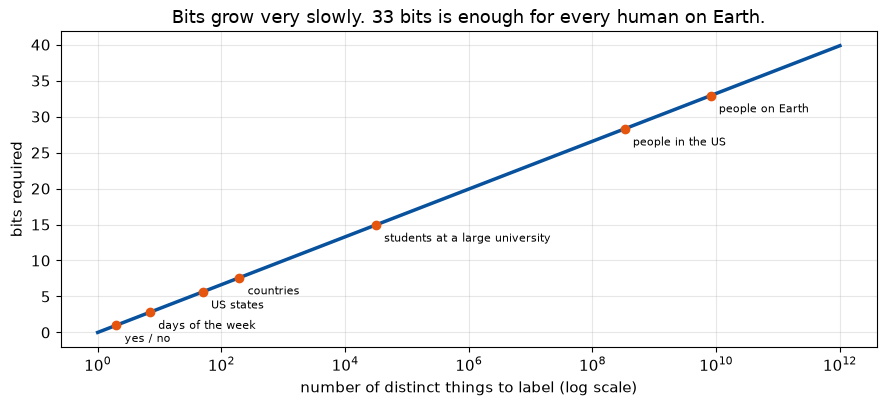

In [50]:
# How many bits do you need to label N different things?
# Answer: ceiling of log base 2 of N. This is the arithmetic behind ID fields, categories, and
# 'how many respondents can this code hold?'

import math

def bits_needed(n_values):
    return max(1, math.ceil(math.log2(n_values)))

cases = [
    (2, "yes / no"),
    (7, "days of the week"),
    (50, "US states"),
    (195, "countries"),
    (31_412, "students at a large university"),
    (330_000_000, "people in the US"),
    (8_100_000_000, "people on Earth"),
]
for n, label in cases:
    b = bits_needed(n)
    print(f"   {label:<32} {n:>13,} values  ->  {b:>2} bit(s)  ({math.ceil(b/8)} byte(s))")

ns = np.logspace(0, 12, 200)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(ns, np.log2(ns), color="#08519c", linewidth=2.5)
for n, label in cases:
    ax.plot([n], [np.log2(n)], "o", color="#e6550d")
    ax.annotate(label, (n, np.log2(n)), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("number of distinct things to label (log scale)")
ax.set_ylabel("bits required")
ax.set_title("Bits grow very slowly. 33 bits is enough for every human on Earth.")
plt.tight_layout()
plt.show()


In [51]:
# Data-size ladder, and the two competing definitions of 'kilobyte'.

print("Decimal (SI) vs binary (IEC) sizes -- this is why a '1 TB' drive shows as 931 GB:\n")
rows = []
for i, (name, sym) in enumerate([("kilo", "k"), ("mega", "M"), ("giga", "G"), ("tera", "T"),
                                 ("peta", "P"), ("exa", "E"), ("zetta", "Z")], start=1):
    decimal = 1000 ** i
    binary = 1024 ** i
    rows.append({
        f"unit": f"{name}byte ({sym}B)",
        "decimal (1000^n)": f"{decimal:.3e}",
        "binary (1024^n)": f"{binary:.3e}",
        "binary is bigger by": f"{(binary/decimal - 1)*100:.1f}%",
    })
print(pd.DataFrame(rows).to_string(index=False))

print("\nThe lecture's figures in context:")
print(f"   2.5 quintillion bytes/day  =  {2.5e18/1000**6:,.1f} exabytes/day  =  {2.5e18/1000**5:,.0f} petabytes/day")
print(f"   175 zettabytes             =  {175e21/1000**4:,.0f} terabytes  "
      f"(that is {175e21/1000**4/1e9:,.0f} billion 1-TB drives)")
print(f"   175 ZB / 8.1 billion people =  {175e21/8.1e9/1e12:,.1f} terabytes per person on Earth")


Decimal (SI) vs binary (IEC) sizes -- this is why a '1 TB' drive shows as 931 GB:

          unit decimal (1000^n) binary (1024^n) binary is bigger by
 kilobyte (kB)        1.000e+03       1.024e+03                2.4%
 megabyte (MB)        1.000e+06       1.049e+06                4.9%
 gigabyte (GB)        1.000e+09       1.074e+09                7.4%
 terabyte (TB)        1.000e+12       1.100e+12               10.0%
 petabyte (PB)        1.000e+15       1.126e+15               12.6%
  exabyte (EB)        1.000e+18       1.153e+18               15.3%
zettabyte (ZB)        1.000e+21       1.181e+21               18.1%

The lecture's figures in context:
   2.5 quintillion bytes/day  =  2.5 exabytes/day  =  2,500 petabytes/day
   175 zettabytes             =  175,000,000,000 terabytes  (that is 175 billion 1-TB drives)
   175 ZB / 8.1 billion people =  21.6 terabytes per person on Earth


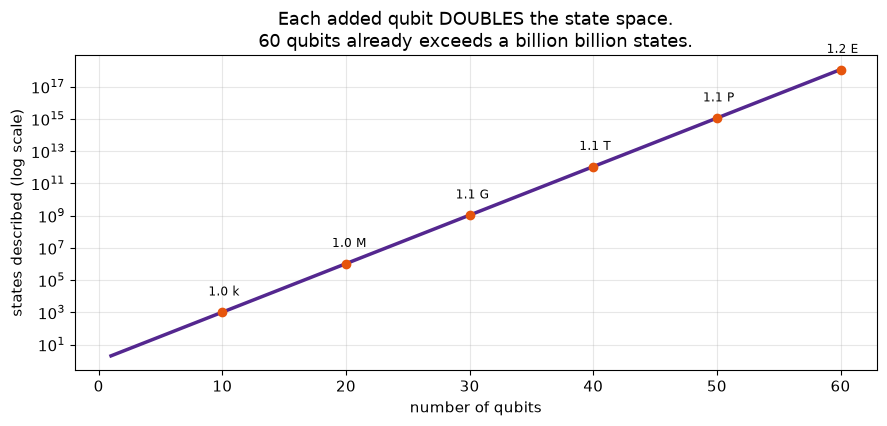

Sixty coin flips have 1,152,921,504,606,846,976 possible outcomes.
That is why exponential growth deserves the respect Section 3 gave it.


In [52]:
# Qubits, briefly (slide 23 mentions them alongside bits and bytes).
# A classical n-bit register holds ONE of 2^n states at a time.
# An n-qubit register holds a superposition described by 2^n numbers at once.
# The practical consequence: simulating quantum systems on classical hardware blows up exponentially.

qubits = np.arange(1, 61)
states = 2.0 ** qubits

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(qubits, states, color="#54278f", linewidth=2.5)
ax.set_yscale("log")
ax.set_xlabel("number of qubits")
ax.set_ylabel("states described (log scale)")
for q in [10, 20, 30, 40, 50, 60]:
    ax.plot([q], [2.0**q], "o", color="#e6550d")
    ax.annotate(humanise(2.0**q, decimals=1), (q, 2.0**q), textcoords="offset points",
                xytext=(-10, 12), fontsize=8.5)
ax.set_title("Each added qubit DOUBLES the state space.\n60 qubits already exceeds a billion billion states.")
plt.tight_layout()
plt.show()

print("Sixty coin flips have", f"{2**60:,}", "possible outcomes.")
print("That is why exponential growth deserves the respect Section 3 gave it.")


> ### Summary of Section 6
> - One hex digit = 4 bits; two hex digits = 1 byte. `0x8B = 10001011 = 139`.
> - Text is numbers is bits. Non-Latin scripts cost more bytes — a real issue in multilingual corpora.
> - `bits = ceil(log2(N))`. Categories, IDs, and codes are all sized by this formula.
> - "kilo" means 1,000 to a statistician and 1,024 to a disk formatter. Know which one you are reading.

---
---

# Section 7 — Structured data: rows are samples, columns are features

**Slides 26 and 27.** The lecture's taxonomy:

| Type | Definition (from the slides) | Examples |
|---|---|---|
| **Structured** | typically organised in tabular form; used in databases; often the *output* of processing semi- and unstructured data | matrices, transactions, tabulated survey results |
| **Semi-structured** | not tabular, but has some structure | HTML pages, citations |
| **Unstructured** | no imposed structure | video, audio, images, chat logs, slide decks, text documents |

Slide 27 then gives the vocabulary you will hear for the rest of your degree, and it matters that
these are all synonyms:

- A **column** = a *feature* = a *covariate* = an *attribute* = a *variable* = a *characteristic*.
- A **row** = a *sample* = a *case* = an *observation* = a *record* = (in surveys) a *respondent*.

The slide's sketch table has columns `ID, SP, Tech, Wifi?, BT?, UG?, Resp.` Let's build it for real.


In [53]:
# Build the survey table sketched on slide 27.
# Column meanings (we are inventing plausible ones -- see Section 14 on why writing this down matters):
#   ID    : respondent identifier
#   SP    : owns a smartphone? (yes/no)
#   Tech  : self-described technology comfort (low / medium / high)
#   Wifi? : uses campus Wi-Fi daily? (yes/no)
#   BT?   : uses Bluetooth devices? (yes/no)
#   UG?   : undergraduate? (yes = undergrad, no = graduate)
#   Resp. : response to the survey's main outcome question, scored 0-100

N_RESP = 60

survey = pd.DataFrame({
    "ID": [f"R{i:03d}" for i in range(1, N_RESP + 1)],
    "SP": rng.choice(["yes", "no"], N_RESP, p=[0.92, 0.08]),
    "Tech": rng.choice(["low", "medium", "high"], N_RESP, p=[0.25, 0.45, 0.30]),
    "Wifi?": rng.choice(["yes", "no"], N_RESP, p=[0.80, 0.20]),
    "BT?": rng.choice(["yes", "no"], N_RESP, p=[0.65, 0.35]),
    "UG?": rng.choice(["yes", "no"], N_RESP, p=[0.70, 0.30]),
})

# Make the outcome depend on the features, so there is something real to find later.
tech_boost = survey["Tech"].map({"low": -8, "medium": 0, "high": 9})
ug_boost   = survey["UG?"].map({"yes": -4, "no": 4})
bt_boost   = survey["BT?"].map({"yes": 3, "no": -3})
survey["Resp."] = np.clip(
    55 + tech_boost + ug_boost + bt_boost + rng.normal(0, 7, N_RESP), 0, 100
).round(1)

print("The structured table (first 10 of 60 rows):")
print(survey.head(10).to_string(index=False))


The structured table (first 10 of 60 rows):
  ID  SP   Tech Wifi? BT? UG?  Resp.
R001 yes    low   yes yes yes   53.4
R002  no    low   yes  no yes   36.3
R003  no medium    no yes yes   57.0
R004 yes    low   yes yes yes   53.0
R005 yes   high   yes yes yes   64.7
R006  no    low   yes yes yes   41.3
R007 yes medium   yes yes yes   56.1
R008 yes    low   yes yes  no   42.2
R009 yes medium   yes yes yes   36.9
R010 yes medium   yes yes yes   48.1


In [54]:
# The four questions to ask of ANY table you are handed. Memorise this cell.

print("1) HOW BIG IS IT?")
print(f"   {survey.shape[0]} rows (samples/cases)  x  {survey.shape[1]} columns (features)\n")

print("2) WHAT KIND OF THING IS IN EACH COLUMN?")
print(survey.dtypes.to_string())
print("   (text columns show as 'object' or 'str' depending on your pandas version;")
print("    'float64' and 'int64' are numbers)\n")

print("3) WHAT ARE THE NUMERIC COLUMNS LIKE?")
print(survey.describe().round(2).to_string())
print()

print("4) WHAT VALUES DO THE CATEGORICAL COLUMNS TAKE, AND HOW OFTEN?")
for col in ["SP", "Tech", "Wifi?", "BT?", "UG?"]:
    counts = survey[col].value_counts()
    print(f"   {col:<6} " + "  ".join(f"{k}={v}" for k, v in counts.items()))


1) HOW BIG IS IT?
   60 rows (samples/cases)  x  7 columns (features)

2) WHAT KIND OF THING IS IN EACH COLUMN?
ID           str
SP           str
Tech         str
Wifi?        str
BT?          str
UG?          str
Resp.    float64
   (text columns show as 'object' or 'str' depending on your pandas version;
    'float64' and 'int64' are numbers)

3) WHAT ARE THE NUMERIC COLUMNS LIKE?
       Resp.
count  60.00
mean   53.59
std    10.13
min    35.90
25%    46.48
50%    53.25
75%    59.72
max    74.70

4) WHAT VALUES DO THE CATEGORICAL COLUMNS TAKE, AND HOW OFTEN?
   SP     yes=52  no=8
   Tech   medium=23  low=19  high=18
   Wifi?  yes=49  no=11
   BT?    yes=37  no=23
   UG?    yes=46  no=14


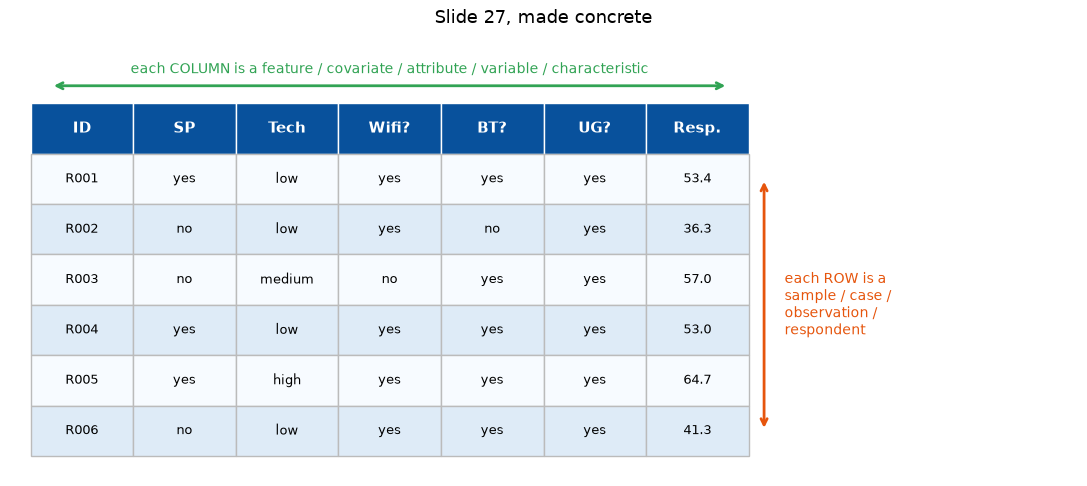

In [55]:
# Draw the slide-27 diagram for real: a table with 'rows = samples' and 'columns = features' marked.

fig, ax = plt.subplots(figsize=(11, 5))
show = survey.head(6)
n_rows, n_cols = show.shape

# Header row
for j, col in enumerate(show.columns):
    ax.add_patch(plt.Rectangle((j, n_rows), 1, 1, facecolor="#08519c", edgecolor="white"))
    ax.text(j + 0.5, n_rows + 0.5, col, ha="center", va="center", color="white",
            fontsize=11, fontweight="bold")

# Body cells
for i in range(n_rows):
    for j in range(n_cols):
        y = n_rows - 1 - i
        ax.add_patch(plt.Rectangle((j, y), 1, 1,
                                   facecolor="#f7fbff" if i % 2 == 0 else "#deebf7",
                                   edgecolor="#bbbbbb"))
        ax.text(j + 0.5, y + 0.5, str(show.iloc[i, j]), ha="center", va="center", fontsize=9.5)

# Annotations
ax.annotate("", xy=(n_cols + 0.15, n_rows - 0.5), xytext=(n_cols + 0.15, 0.5),
            arrowprops=dict(arrowstyle="<->", linewidth=2, color="#e6550d"))
ax.text(n_cols + 0.35, n_rows / 2, "each ROW is a\nsample / case /\nobservation /\nrespondent",
        va="center", fontsize=10, color="#e6550d")
ax.annotate("", xy=(0.2, n_rows + 1.35), xytext=(n_cols - 0.2, n_rows + 1.35),
            arrowprops=dict(arrowstyle="<->", linewidth=2, color="#31a354"))
ax.text(n_cols / 2, n_rows + 1.6,
        "each COLUMN is a feature / covariate / attribute / variable / characteristic",
        ha="center", fontsize=10, color="#31a354")

ax.set_xlim(-0.2, n_cols + 3.2)
ax.set_ylim(-0.4, n_rows + 2.1)
ax.axis("off")
ax.set_title("Slide 27, made concrete", fontsize=13, pad=18)
plt.tight_layout()
plt.show()


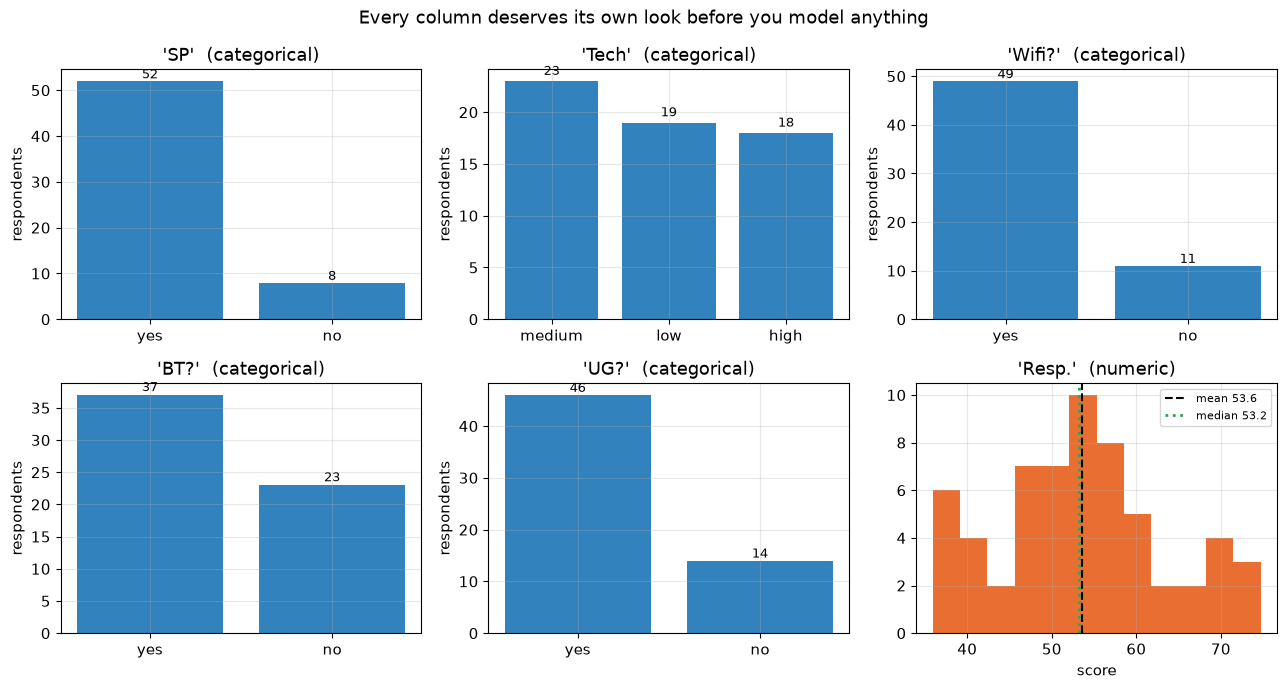

In [56]:
# Slide 7 asks: 'How are the values of an attribute distributed?' Here is the answer, per attribute.

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

cat_cols = ["SP", "Tech", "Wifi?", "BT?", "UG?"]
for ax, col in zip(axes.ravel(), cat_cols):
    counts = survey[col].value_counts()
    ax.bar(counts.index.astype(str), counts.values, color="#3182bd")
    for x, v in zip(counts.index.astype(str), counts.values):
        ax.text(x, v + 0.6, str(v), ha="center", fontsize=9)
    ax.set_title(f"'{col}'  (categorical)")
    ax.set_ylabel("respondents")

# The numeric column gets a histogram instead of a bar chart -- different KIND of variable,
# different KIND of picture. This distinction matters.
ax = axes.ravel()[5]
ax.hist(survey["Resp."], bins=12, color="#e6550d", alpha=0.85)
ax.axvline(survey["Resp."].mean(), color="black", linestyle="--", label=f"mean {survey['Resp.'].mean():.1f}")
ax.axvline(survey["Resp."].median(), color="#31a354", linestyle=":", linewidth=2,
           label=f"median {survey['Resp.'].median():.1f}")
ax.set_title("'Resp.'  (numeric)")
ax.set_xlabel("score")
ax.legend(fontsize=8)

fig.suptitle("Every column deserves its own look before you model anything", fontsize=13)
plt.tight_layout()
plt.show()


Counts of respondents by tech comfort and undergraduate status:
UG?     no  yes
Tech           
high     3   15
low      4   15
medium   7   16

The same table as row percentages:
UG?       no   yes
Tech              
high    16.7  83.3
low     21.1  78.9
medium  30.4  69.6


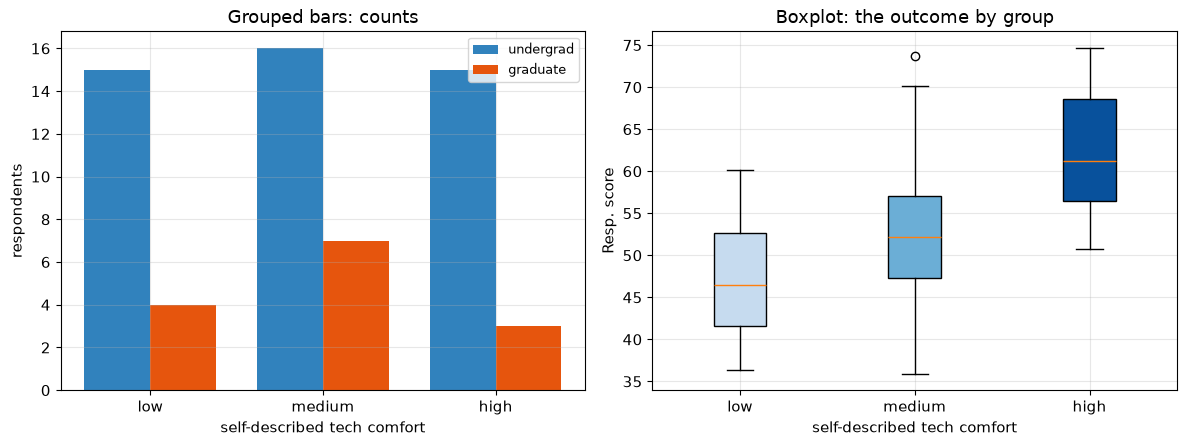


A boxplot shows five numbers at once: minimum, lower quartile, median,
upper quartile, maximum -- plus outliers as separate dots.


In [57]:
# Cross-tabulation: how do two features relate? This is the workhorse of survey analysis.

xtab = pd.crosstab(survey["Tech"], survey["UG?"])
print("Counts of respondents by tech comfort and undergraduate status:")
print(xtab.to_string())
print("\nThe same table as row percentages:")
print((xtab.div(xtab.sum(axis=1), axis=0) * 100).round(1).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

order = ["low", "medium", "high"]
xt = xtab.reindex(order)
width = 0.38
x = np.arange(len(order))
ax1.bar(x - width/2, xt["yes"], width, label="undergrad", color="#3182bd")
ax1.bar(x + width/2, xt["no"], width, label="graduate", color="#e6550d")
ax1.set_xticks(x); ax1.set_xticklabels(order)
ax1.set_xlabel("self-described tech comfort")
ax1.set_ylabel("respondents")
ax1.set_title("Grouped bars: counts")
ax1.legend(fontsize=9)

# Boxplot: how the numeric outcome differs across a categorical feature.
data_by_tech = [survey.loc[survey["Tech"] == t, "Resp."].values for t in order]
bp = ax2.boxplot(data_by_tech, patch_artist=True)
for patch, colour in zip(bp["boxes"], ["#c6dbef", "#6baed6", "#08519c"]):
    patch.set_facecolor(colour)
ax2.set_xticks([1, 2, 3])
ax2.set_xticklabels(order)
ax2.set_xlabel("self-described tech comfort")
ax2.set_ylabel("Resp. score")
ax2.set_title("Boxplot: the outcome by group")

plt.tight_layout()
plt.show()

print("\nA boxplot shows five numbers at once: minimum, lower quartile, median,")
print("upper quartile, maximum -- plus outliers as separate dots.")


> ### Summary of Section 7
> - Structured data = a table. Rows are cases; columns are features. Learn all the synonyms, because
>   different disciplines use different ones for the same thing.
> - Categorical and numeric columns get different summaries and different charts.
> - Look at every column *before* modelling. Slide 7's questions ("how do the data look?", "how are
>   the values distributed?", "does visualizing the data help?") are a checklist, not rhetoric.

---
---

# Section 8 — Explanation or prediction: ŷ = f(x₁, x₂, …, xₙ)

**Slide 28.** The whole of supervised machine learning, in one line:

$$\hat{y} = f(x_1, x_2, \ldots, x_n)$$

The slide's three points are worth memorising exactly:

1. We would like an **explanation** or **prediction** of a *response* `y`.
2. We can only ever get an **estimate**, written `ŷ` ("y-hat"). Never `y` itself.
3. Oversimplified: **the function `f( )` is the computation.**

The `x`s are the features from Section 7. `y` is the outcome column. `f` is whatever we fit.


In [58]:
# Turn the survey's text columns into numbers, because f() needs numbers.
# This is called 'encoding'. Every real analysis starts here.

model_data = pd.DataFrame({
    "tech_score":  survey["Tech"].map({"low": 0, "medium": 1, "high": 2}),
    "is_undergrad": (survey["UG?"] == "yes").astype(int),      # True/False -> 1/0
    "uses_bt":      (survey["BT?"] == "yes").astype(int),
    "uses_wifi":    (survey["Wifi?"] == "yes").astype(int),
})
y = survey["Resp."].values

print("The feature matrix X (first 8 rows) -- this is x1, x2, ..., xn from the slide:")
print(model_data.head(8).to_string(index=False))
print(f"\nThe response vector y (first 8): {y[:8]}")
print(f"\nX has shape {model_data.shape}: {model_data.shape[0]} samples, {model_data.shape[1]} features.")


The feature matrix X (first 8 rows) -- this is x1, x2, ..., xn from the slide:
 tech_score  is_undergrad  uses_bt  uses_wifi
          0             1        1          1
          0             1        0          1
          1             1        1          0
          0             1        1          1
          2             1        1          1
          0             1        1          1
          1             1        1          1
          0             0        1          1

The response vector y (first 8): [53.4 36.3 57.  53.  64.7 41.3 56.1 42.2]

X has shape (60, 4): 60 samples, 4 features.


In [59]:
# Fit f() as a linear function. We use numpy's least-squares solver directly so you can see
# that 'fitting a model' is just solving for a set of weights.

X = model_data.values.astype(float)
X_with_intercept = np.column_stack([np.ones(len(X)), X])     # a column of 1s gives us the intercept

# lstsq = 'least squares': find the weights that make the total squared error as small as possible.
weights, *_ = np.linalg.lstsq(X_with_intercept, y, rcond=None)

names = ["intercept"] + list(model_data.columns)
print("The fitted function f():\n")
print(f"   y-hat = {weights[0]:.2f}")
for name, w in zip(names[1:], weights[1:]):
    print(f"           {w:+.2f} * {name}")

print("\nHow to read these weights (this is the 'explanation' half of slide 28):")
print(f"   Moving one step up the tech-comfort scale is associated with {weights[1]:+.1f} points.")
print(f"   Being an undergraduate is associated with {weights[2]:+.1f} points.")
print("\nWARNING: 'associated with' is NOT 'causes'. Nothing in this arithmetic establishes a cause.")

# The 'prediction' half: run the function forward.
y_hat = X_with_intercept @ weights        # '@' means matrix multiplication
residuals = y - y_hat
print(f"\nTypical prediction error (root mean squared): {np.sqrt((residuals**2).mean()):.2f} points")


The fitted function f():

   y-hat = 47.74
           +7.34 * tech_score
           -7.03 * is_undergrad
           +6.53 * uses_bt
           -0.02 * uses_wifi

How to read these weights (this is the 'explanation' half of slide 28):
   Moving one step up the tech-comfort scale is associated with +7.3 points.
   Being an undergraduate is associated with -7.0 points.


Typical prediction error (root mean squared): 7.07 points


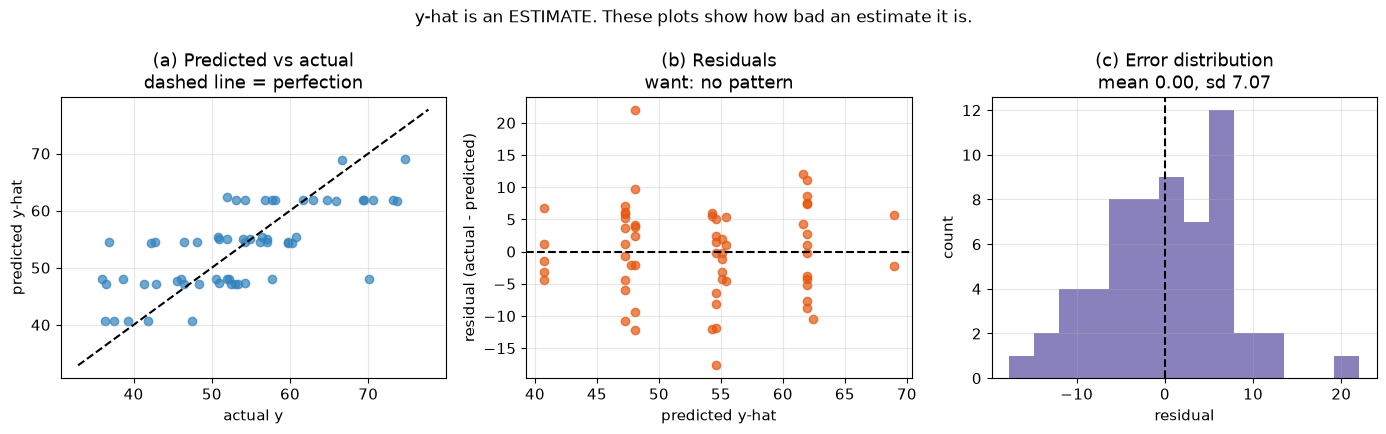

In [60]:
# Three diagnostic pictures that every fitted model should get. Learn to read all three.

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))

# (a) Predicted vs actual. Perfect prediction would put every point on the diagonal.
axes[0].scatter(y, y_hat, alpha=0.7, color="#3182bd")
lims = [min(y.min(), y_hat.min()) - 3, max(y.max(), y_hat.max()) + 3]
axes[0].plot(lims, lims, "k--", linewidth=1.5)
axes[0].set_xlabel("actual y")
axes[0].set_ylabel("predicted y-hat")
axes[0].set_title("(a) Predicted vs actual\ndashed line = perfection")

# (b) Residuals. We want a shapeless cloud centred on zero. Any PATTERN here means f() is wrong.
axes[1].scatter(y_hat, residuals, alpha=0.7, color="#e6550d")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("predicted y-hat")
axes[1].set_ylabel("residual (actual - predicted)")
axes[1].set_title("(b) Residuals\nwant: no pattern")

# (c) Distribution of the errors.
axes[2].hist(residuals, bins=14, color="#756bb1", alpha=0.85)
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set_xlabel("residual")
axes[2].set_ylabel("count")
axes[2].set_title(f"(c) Error distribution\nmean {residuals.mean():.2f}, sd {residuals.std():.2f}")

fig.suptitle("y-hat is an ESTIMATE. These plots show how bad an estimate it is.", fontsize=12)
plt.tight_layout()
plt.show()


### 8.1 `f( )` does not have to be a line

Slide 28 says "oversimplified: the function `f( )` is the computation". The oversimplification is
that `f` can be *anything* — a line, a curve, a decision tree, a neural network. More flexible `f`
means it fits your data better. It also means it fits your data's *noise* better, which is called
**overfitting** and is the central problem of the whole field.


/var/folders/6d/xqywj2xx2llc_k2t6nkshrgh0000gn/T/ipykernel_41444/3194398440.py:12: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(x_obs, y_obs, degree)


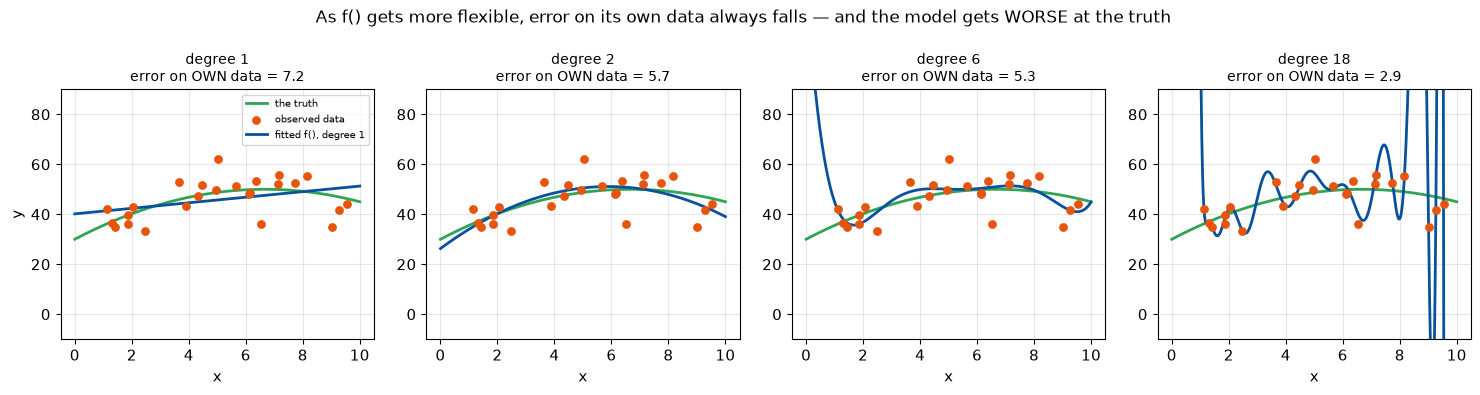

Degree 18 fits the 25 dots almost perfectly and is nonsense everywhere between them.
A model that cannot be wrong on your data cannot be trusted off it.

NOTE: you probably saw a pink 'RankWarning: Polyfit may be poorly conditioned' box above.
That is not a bug -- it is numpy telling you the degree-18 model has more flexibility than
the data can support. Warnings like this are worth reading rather than dismissing.


In [61]:
# One dataset, four different f() of increasing flexibility.
# The 'truth' is a gentle curve; we observe only 25 noisy points.

x_true = np.linspace(0, 10, 400)
f_true = 30 + 6 * x_true - 0.45 * x_true ** 2

x_obs = np.sort(rng.uniform(0.3, 9.7, 25))
y_obs = 30 + 6 * x_obs - 0.45 * x_obs ** 2 + rng.normal(0, 5, len(x_obs))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, degree in zip(axes, [1, 2, 6, 18]):
    coeffs = np.polyfit(x_obs, y_obs, degree)
    fitted = np.polyval(coeffs, x_true)
    in_sample_error = np.sqrt(np.mean((y_obs - np.polyval(coeffs, x_obs)) ** 2)) 
    ax.plot(x_true, f_true, color="#31a354", linewidth=2, label="the truth")
    ax.scatter(x_obs, y_obs, s=28, color="#e6550d", zorder=3, label="observed data")
    ax.plot(x_true, fitted, color="#08519c", linewidth=2, label=f"fitted f(), degree {degree}")
    ax.set_ylim(f_true.min() - 40, f_true.max() + 40)
    ax.set_title(f"degree {degree}\nerror on OWN data = {in_sample_error:.1f}", fontsize=10)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(fontsize=7.5)
fig.suptitle("As f() gets more flexible, error on its own data always falls — "
             "and the model gets WORSE at the truth", fontsize=12)
plt.tight_layout()
plt.show()

print("Degree 18 fits the 25 dots almost perfectly and is nonsense everywhere between them.")
print("A model that cannot be wrong on your data cannot be trusted off it.")
print()
print("NOTE: you probably saw a pink 'RankWarning: Polyfit may be poorly conditioned' box above.")
print("That is not a bug -- it is numpy telling you the degree-18 model has more flexibility than")
print("the data can support. Warnings like this are worth reading rather than dismissing.")


> ### Summary of Section 8
> - `ŷ = f(x₁ … xₙ)`. Features in, estimate out. The hat is a permanent reminder of humility.
> - "Explanation" reads the *weights*; "prediction" runs the *function*. They pull in opposite
>   directions: the most predictive `f` is often the least explainable.
> - Always plot residuals. A pattern in the residuals is `f` telling you it is the wrong shape.
> - Flexibility is not free. See the degree-18 panel and never forget it.

---
---

# Section 9 — Missing data, imputation, covariates, dimensionality

**Slide 29** quotes R. Michael Alvarez:

> Data used in many studies has particular problems that necessitate tools to render it tractable
> for analysis. Data sets may have a lot of **missing data**, requiring **multiple imputation** — or
> hundreds of columns of potential **covariates**, calling for techniques to **reduce the
> dimensionality** of the data set.

Three problems, named precisely. Let's create each one and treat it.


In [62]:
# Introduce realistic missingness into our survey. Real missingness is almost never random --
# that is exactly what makes it dangerous.

survey_missing = survey.copy()

# (a) MCAR -- Missing Completely At Random: a few Bluetooth answers lost to a form glitch.
mcar_idx = rng.choice(survey_missing.index, size=6, replace=False)
survey_missing.loc[mcar_idx, "BT?"] = np.nan

# (b) MAR -- Missing At Random (given other columns): low-tech-comfort respondents skipped
#     the Wi-Fi question more often.
for i in survey_missing.index:
    if survey_missing.loc[i, "Tech"] == "low" and rng.random() < 0.45:
        survey_missing.loc[i, "Wifi?"] = np.nan

# (c) MNAR -- Missing Not At Random: people with LOW scores declined to answer the main question.
#     This is the poisonous kind, because the missing values depend on the missing values.
for i in survey_missing.index:
    score = survey_missing.loc[i, "Resp."]
    if score < 48 and rng.random() < 0.55:
        survey_missing.loc[i, "Resp."] = np.nan

print("Missing values per column:")
print(survey_missing.isna().sum().to_string())
print(f"\nRows with at least one missing value: {survey_missing.isna().any(axis=1).sum()} of {len(survey_missing)}")
print(f"Rows that are completely clean       : {(~survey_missing.isna().any(axis=1)).sum()}")


Missing values per column:
ID        0
SP        0
Tech      0
Wifi?    11
BT?       6
UG?       0
Resp.    10

Rows with at least one missing value: 22 of 60
Rows that are completely clean       : 38


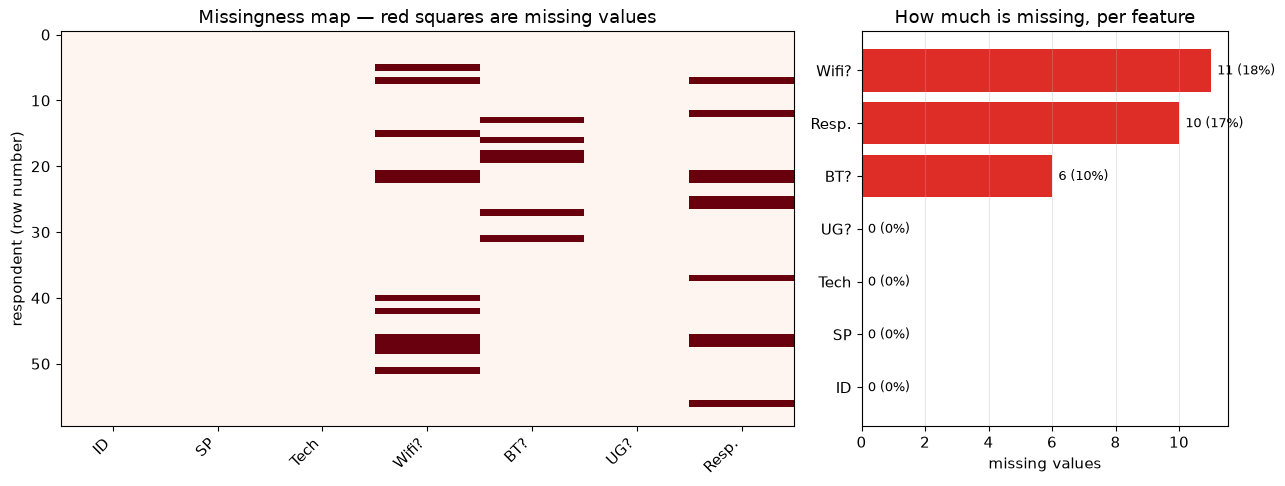

In [63]:
# ALWAYS look at missingness as a picture before you decide what to do about it.
# Patterns (stripes, blocks) reveal the mechanism; a random dusting looks different from a block.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})

missing_matrix = survey_missing.isna().astype(int).values
ax1.imshow(missing_matrix, aspect="auto", cmap="Reds", interpolation="nearest")
ax1.set_xticks(range(survey_missing.shape[1]))
ax1.set_xticklabels(survey_missing.columns, rotation=45, ha="right")
ax1.set_ylabel("respondent (row number)")
ax1.set_title("Missingness map — red squares are missing values")
ax1.grid(visible=False)

counts = survey_missing.isna().sum().sort_values()
ax2.barh(counts.index.astype(str), counts.values, color="#de2d26")
for i, v in enumerate(counts.values):
    ax2.text(v + 0.2, i, f"{v} ({v/len(survey_missing):.0%})", va="center", fontsize=9)
ax2.set_xlabel("missing values")
ax2.set_title("How much is missing, per feature")
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()


In [64]:
# Four strategies for the missing 'Resp.' scores, compared honestly against the truth.
# (We can compare against the truth ONLY because we hid the values ourselves. Never possible in real life.)

truth = survey["Resp."]                        # the complete original column
observed = survey_missing["Resp."]             # with holes

# Strategy 1: LISTWISE DELETION -- drop rows with any missing value ('complete case analysis').
strategy_drop = observed.dropna()

# Strategy 2: MEAN IMPUTATION -- fill every hole with the mean of what remains.
strategy_mean = observed.fillna(observed.mean())

# Strategy 3: GROUP-MEAN IMPUTATION -- fill using the mean within the respondent's Tech group.
strategy_group = observed.copy()
for tech_level, group in survey_missing.groupby("Tech", observed=True):
    fill_value = group["Resp."].mean()
    holes = group.index[group["Resp."].isna()]
    strategy_group.loc[holes] = fill_value

# Strategy 4: (SINGLE DRAW FROM) MULTIPLE IMPUTATION -- fill by drawing plausible values from the
# observed distribution, preserving spread. Real multiple imputation repeats this many times and
# combines the results, which is exactly what slide 29 is referring to.
strategy_mi = observed.copy()
holes = observed.index[observed.isna()]
strategy_mi.loc[holes] = rng.choice(observed.dropna().values, size=len(holes))

results = {
    "TRUTH (all 60)":              truth,
    "1. drop missing rows":        strategy_drop,
    "2. mean imputation":          strategy_mean,
    "3. group-mean imputation":    strategy_group,
    "4. one imputation draw":      strategy_mi,
}
print(f"{'strategy':<26}{'n':>5}{'mean':>9}{'std dev':>10}{'bias vs truth':>16}")
for label, s in results.items():
    bias = s.mean() - truth.mean()
    print(f"{label:<26}{len(s):>5}{s.mean():>9.2f}{s.std():>10.2f}{bias:>+16.2f}")


strategy                      n     mean   std dev   bias vs truth
TRUTH (all 60)               60    53.59     10.13           +0.00
1. drop missing rows         50    56.05      9.18           +2.46
2. mean imputation           60    56.05      8.37           +2.46
3. group-mean imputation     60    55.31      8.61           +1.73
4. one imputation draw       60    57.39      9.67           +3.80


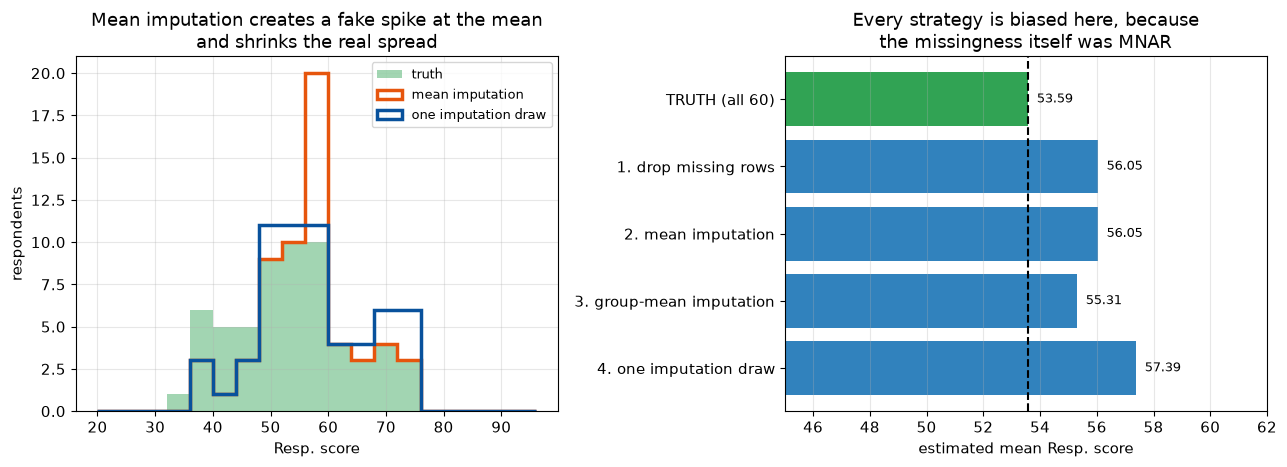

The honest conclusion: when data are missing BECAUSE of their own value (MNAR), no
statistical repair recovers the truth. The fix is a better instrument, not better code.
This is the same lesson as Section 2's biased sampling, wearing different clothes.


In [65]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

bins = np.arange(20, 100, 4)
ax1.hist(truth, bins=bins, color="#31a354", alpha=0.45, label="truth")
ax1.hist(strategy_mean, bins=bins, histtype="step", linewidth=2.5, color="#e6550d",
         label="mean imputation")
ax1.hist(strategy_mi, bins=bins, histtype="step", linewidth=2.5, color="#08519c",
         label="one imputation draw")
ax1.set_xlabel("Resp. score")
ax1.set_ylabel("respondents")
ax1.set_title("Mean imputation creates a fake spike at the mean\nand shrinks the real spread")
ax1.legend(fontsize=9)

labels = list(results.keys())
means = [results[k].mean() for k in labels]
bars = ax2.barh(labels, means, color=["#31a354"] + ["#3182bd"] * 4)
ax2.axvline(truth.mean(), color="black", linestyle="--")
for i, m in enumerate(means):
    ax2.text(m + 0.3, i, f"{m:.2f}", va="center", fontsize=9)
ax2.set_xlim(45, 62)
ax2.set_xlabel("estimated mean Resp. score")
ax2.set_title("Every strategy is biased here, because\nthe missingness itself was MNAR")
ax2.invert_yaxis()
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

print("The honest conclusion: when data are missing BECAUSE of their own value (MNAR), no")
print("statistical repair recovers the truth. The fix is a better instrument, not better code.")
print("This is the same lesson as Section 2's biased sampling, wearing different clothes.")


### 9.1 Hundreds of covariates: the dimensionality problem

The second half of the Alvarez quote: *hundreds of columns of potential covariates, calling for
techniques to reduce the dimensionality of the data set.*

Why is having lots of columns a *problem*? Two reasons, and both are visible in code:

1. **Redundancy.** Many columns measure the same underlying thing. Height in inches and height in
   centimetres are two columns and one fact.
2. **Spurious findings.** If you test enough columns against an outcome, some will look significant
   purely by chance. This is the "garden of forking paths".


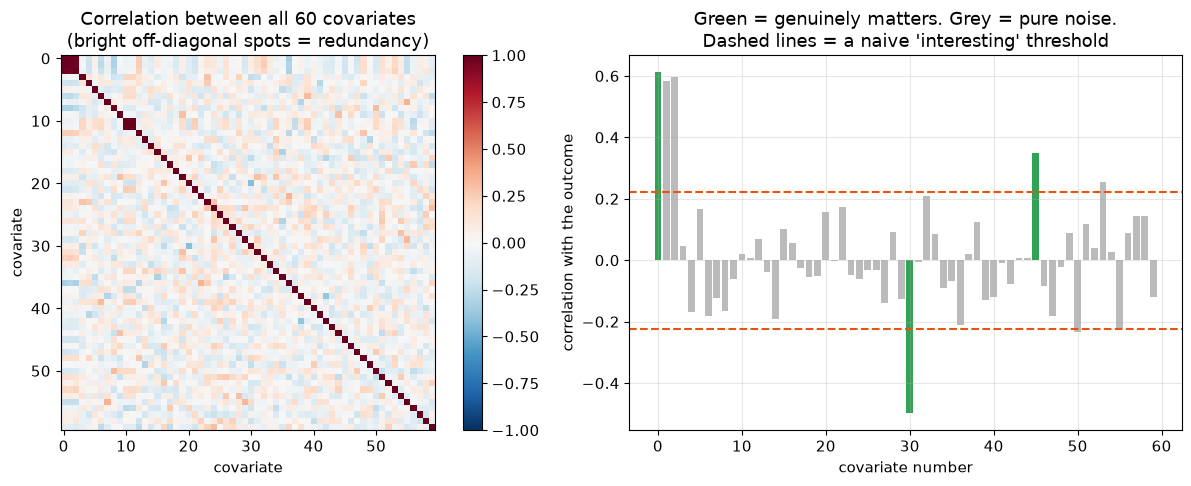

Covariates that cross the threshold but are pure noise: [1, 2, 50, 53]
That is 4 false leads from 57 noise columns.
Test enough things and something will always look significant. This is why
dimensionality reduction and pre-registration exist.


In [66]:
# Build a wide dataset: 80 respondents, 60 'potential covariates'.
# Only THREE of them actually influence the outcome. The other 57 are pure noise.

n, p = 80, 60
X_wide = rng.normal(0, 1, size=(n, p))

# Make some columns near-duplicates of each other (this is what real survey batteries look like).
X_wide[:, 1] = X_wide[:, 0] * 0.97 + rng.normal(0, 0.15, n)
X_wide[:, 2] = X_wide[:, 0] * 0.93 + rng.normal(0, 0.22, n)
X_wide[:, 11] = X_wide[:, 10] * 0.95 + rng.normal(0, 0.18, n)

y_wide = 3.0 * X_wide[:, 0] - 2.0 * X_wide[:, 30] + 1.5 * X_wide[:, 45] + rng.normal(0, 2.0, n)

# Correlate each covariate with the outcome one at a time -- the naive approach.
correlations = np.array([np.corrcoef(X_wide[:, j], y_wide)[0, 1] for j in range(p)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

corr_matrix = np.corrcoef(X_wide.T)
im = ax1.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set_title("Correlation between all 60 covariates\n(bright off-diagonal spots = redundancy)")
ax1.set_xlabel("covariate"); ax1.set_ylabel("covariate")
ax1.grid(visible=False)
plt.colorbar(im, ax=ax1, fraction=0.046)

real = [0, 30, 45]
bar_colours = ["#31a354" if j in real else "#bbbbbb" for j in range(p)]
ax2.bar(range(p), correlations, color=bar_colours)
threshold = 2 / np.sqrt(n)      # a rough "looks interesting" line
ax2.axhline(threshold, color="#e6550d", linestyle="--")
ax2.axhline(-threshold, color="#e6550d", linestyle="--")
ax2.set_xlabel("covariate number")
ax2.set_ylabel("correlation with the outcome")
ax2.set_title("Green = genuinely matters. Grey = pure noise.\nDashed lines = a naive 'interesting' threshold")
plt.tight_layout()
plt.show()

false_positives = [j for j in range(p) if abs(correlations[j]) > threshold and j not in real]
print(f"Covariates that cross the threshold but are pure noise: {false_positives}")
print(f"That is {len(false_positives)} false leads from 57 noise columns.")
print("Test enough things and something will always look significant. This is why")
print("dimensionality reduction and pre-registration exist.")


Variance explained by each principal component of the three redundant columns:
   component 1:  98.4%
   component 2:   1.3%
   component 3:   0.4%

One component captures 98% of everything in three columns.
So: 3 columns -> 1 column, with almost no loss. THAT is dimensionality reduction.


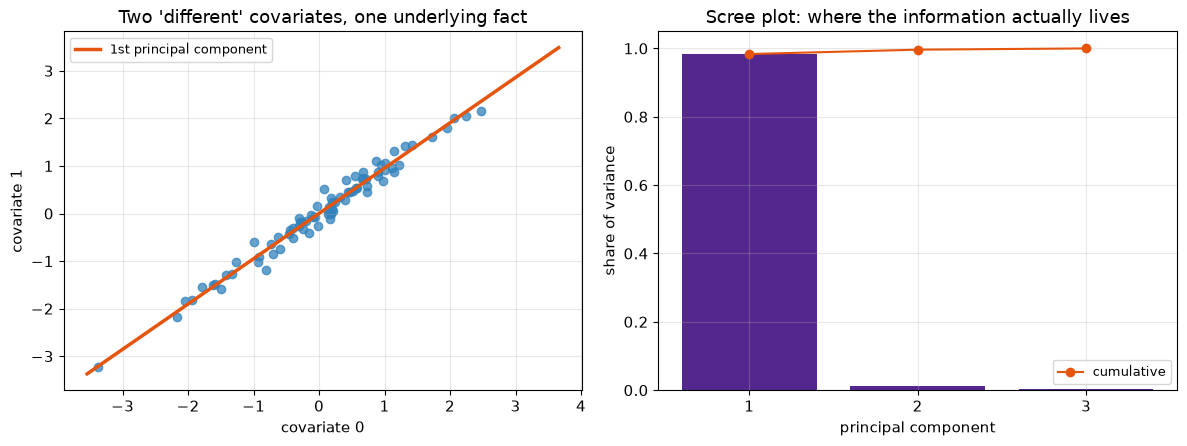

In [67]:
# Dimensionality REDUCTION, demonstrated with the simplest real technique:
# Principal Component Analysis (PCA). We do it with numpy's SVD so nothing is hidden.
# The idea: find the direction along which the data vary most, and describe points by that alone.

# Take the three redundant columns 0, 1, 2 -- three columns holding roughly ONE fact.
trio = X_wide[:, [0, 1, 2]]
trio_centred = trio - trio.mean(axis=0)

U, S, Vt = np.linalg.svd(trio_centred, full_matrices=False)
explained = S ** 2 / np.sum(S ** 2)     # share of total variance per component

print("Variance explained by each principal component of the three redundant columns:")
for k, share in enumerate(explained, start=1):
    print(f"   component {k}: {share:>6.1%}")
print(f"\nOne component captures {explained[0]:.0%} of everything in three columns.")
print("So: 3 columns -> 1 column, with almost no loss. THAT is dimensionality reduction.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

ax1.scatter(trio[:, 0], trio[:, 1], alpha=0.75, color="#3182bd")
# Draw the first principal direction through the cloud.
direction = Vt[0, :2]
centre = trio[:, :2].mean(axis=0)
t = np.linspace(-3, 3, 10)
ax1.plot(centre[0] + t * direction[0] * 2, centre[1] + t * direction[1] * 2,
         color="#e6550d", linewidth=2.5, label="1st principal component")
ax1.set_xlabel("covariate 0"); ax1.set_ylabel("covariate 1")
ax1.set_title("Two 'different' covariates, one underlying fact")
ax1.legend(fontsize=9)

ax2.bar(range(1, 4), explained, color="#54278f")
ax2.plot(range(1, 4), np.cumsum(explained), marker="o", color="#e6550d",
         label="cumulative")
ax2.set_xticks(range(1, 4))
ax2.set_xlabel("principal component")
ax2.set_ylabel("share of variance")
ax2.set_ylim(0, 1.05)
ax2.set_title("Scree plot: where the information actually lives")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()


> ### Summary of Section 9
> - Missingness has **mechanisms**: MCAR (harmless), MAR (fixable with the right model), MNAR
>   (not fixable by statistics). Diagnose before you impute.
> - Mean imputation is the most common choice and it always understates the spread. Multiple
>   imputation — repeat the filling many times and combine — is what slide 29 is pointing at.
> - Wide data invite false positives. Reduce dimensions, or pre-specify what you will test.


---
---

# Section 10 — Semi-structured data: two academic citations

**Slides 30 and 31.** The lecture uses two real citations to make the point that social-science data
often arrives *semi-structured*: there is structure, but it is irregular.

```
K. Pelechrinis, P. Krishnamurthy, and C. Gkantsidis, "Towards a Trustworthy PF Scheduler
for Cellular Data Networks," IEEE Globecom, 2012.

K. Kaemarungsi and P. Krishnamurthy, "Analysis of WLAN's Received Signal Strength Indication
for Indoor Location Fingerprinting," Elsevier Pervasive and Mobile Computing, Vol. 8,
Issue 2, April 2012.
```

Slide 31's comments, which are the actual lesson:

- Structure is **irregular** — not all citations follow the same format.
- Part or much of the data may **lack structure** entirely.
- Article titles are **plain text** — may need further processing to extract features.
- **Attributes vary**: not all citations have volume, issue, and DOI.
- **A priori vs. a posteriori**: citations *can* be processed into a database — but they were **not
  created with a database in mind**.

That last point is the deepest one in the lecture, and we will come back to it.


In [68]:
# The two citations, exactly as a computer would receive them: as strings.
citations = [
    'K. Pelechrinis, P. Krishnamurthy, and C. Gkantsidis, "Towards a Trustworthy PF Scheduler '
    'for Cellular Data Networks," IEEE Globecom, 2012.',

    'K. Kaemarungsi and P. Krishnamurthy, "Analysis of WLAN\'s Received Signal Strength '
    'Indication for Indoor Location Fingerprinting," Elsevier Pervasive and Mobile Computing, '
    'Vol. 8, Issue 2, April 2012.',
]

for i, c in enumerate(citations, start=1):
    print(f"[{i}] {c}\n")
    print(f"    length: {len(c)} characters. To a computer, right now, that is ALL it is.\n")


[1] K. Pelechrinis, P. Krishnamurthy, and C. Gkantsidis, "Towards a Trustworthy PF Scheduler for Cellular Data Networks," IEEE Globecom, 2012.

    length: 138 characters. To a computer, right now, that is ALL it is.

[2] K. Kaemarungsi and P. Krishnamurthy, "Analysis of WLAN's Received Signal Strength Indication for Indoor Location Fingerprinting," Elsevier Pervasive and Mobile Computing, Vol. 8, Issue 2, April 2012.

    length: 199 characters. To a computer, right now, that is ALL it is.



### 10.1 Extracting structure with patterns

To pull fields out of text we use **regular expressions** (`re` in Python) — a compact language for
describing text patterns. You do not need to master them; you need to know they exist and that they
are how semi-structured data gets converted into the tables of Section 7.

A short cheat sheet for the patterns used below:

| Pattern | Means |
|---|---|
| `"([^"]+)"` | a run of characters inside double quotes; the parentheses **capture** it |
| `\d{4}` | exactly four digits |
| `Vol\.\s*(\d+)` | the literal text `Vol.`, optional spaces, then digits (captured) |
| `re.search` | find the first match, or return `None` if there is none |


In [69]:
import re

def parse_citation(text):
    # Return a dictionary of whatever fields we can find. Missing fields become None.
    record = {}

    # 1. TITLE: the part inside the double quotes.
    title_match = re.search(r'"([^"]+),?"', text)
    record["title"] = title_match.group(1).rstrip(",") if title_match else None

    # 2. AUTHORS: everything before the opening quote, split on commas and the word 'and'.
    author_blob = text.split('"')[0]
    # Order matters in the alternation: match ", and " BEFORE plain ", ",
    # otherwise the word "and" is left stuck to the last author's name.
    parts = re.split(r",\s*and\s+|\s+and\s+|,\s*", author_blob)
    authors = [p.strip().rstrip(",") for p in parts if p.strip()]
    record["authors"] = authors
    record["n_authors"] = len(authors)

    # 3. YEAR: a four-digit number starting with 19 or 20.
    year_match = re.search(r"\b(19|20)\d{2}\b", text)
    record["year"] = int(year_match.group(0)) if year_match else None

    # 4. VENUE: the chunk after the closing quote, up to the first comma.
    after_title = text.split('"')[-1]
    venue_match = re.match(r"\s*,?\s*([^,]+)", after_title)
    record["venue"] = venue_match.group(1).strip() if venue_match else None

    # 5-7. OPTIONAL fields. These are the ones slide 31 says do not always exist.
    vol_match   = re.search(r"Vol\.\s*(\d+)", text)
    issue_match = re.search(r"Issue\s*(\d+)", text)
    month_match = re.search(r"\b(January|February|March|April|May|June|July|August|"
                            r"September|October|November|December)\b", text)
    doi_match   = re.search(r"10\.\d{4,9}/\S+", text)

    record["volume"] = int(vol_match.group(1)) if vol_match else None
    record["issue"]  = int(issue_match.group(1)) if issue_match else None
    record["month"]  = month_match.group(0) if month_match else None
    record["doi"]    = doi_match.group(0) if doi_match else None

    return record

parsed = [parse_citation(c) for c in citations]
for i, rec in enumerate(parsed, start=1):
    print(f"--- citation {i} ---")
    for key, value in rec.items():
        print(f"   {key:<10} : {value}")
    print()


--- citation 1 ---
   title      : Towards a Trustworthy PF Scheduler for Cellular Data Networks
   authors    : ['K. Pelechrinis', 'P. Krishnamurthy', 'C. Gkantsidis']
   n_authors  : 3
   year       : 2012
   venue      : IEEE Globecom
   volume     : None
   issue      : None
   month      : None
   doi        : None

--- citation 2 ---
   title      : Analysis of WLAN's Received Signal Strength Indication for Indoor Location Fingerprinting
   authors    : ['K. Kaemarungsi', 'P. Krishnamurthy']
   n_authors  : 2
   year       : 2012
   venue      : Elsevier Pervasive and Mobile Computing
   volume     : 8
   issue      : 2
   month      : April
   doi        : None



In [70]:
# Now the semi-structured data has become structured -- a table. Note the empty cells:
# this raggedness IS slide 31's point about varying attributes.

citation_table = pd.DataFrame(parsed)
citation_table["authors"] = citation_table["authors"].apply(lambda lst: "; ".join(lst))
print(citation_table.T.to_string())     # transposed (.T) so the long text fits on screen

print("\n\nWhich fields exist for which citation?")
present = citation_table.notna()
print(present.T.to_string())


                                                                       0                                                                                          1
title      Towards a Trustworthy PF Scheduler for Cellular Data Networks  Analysis of WLAN's Received Signal Strength Indication for Indoor Location Fingerprinting
authors                  K. Pelechrinis; P. Krishnamurthy; C. Gkantsidis                                                           K. Kaemarungsi; P. Krishnamurthy
n_authors                                                              3                                                                                          2
year                                                                2012                                                                                       2012
venue                                                      IEEE Globecom                                                    Elsevier Pervasive and Mobile Computing
volume          

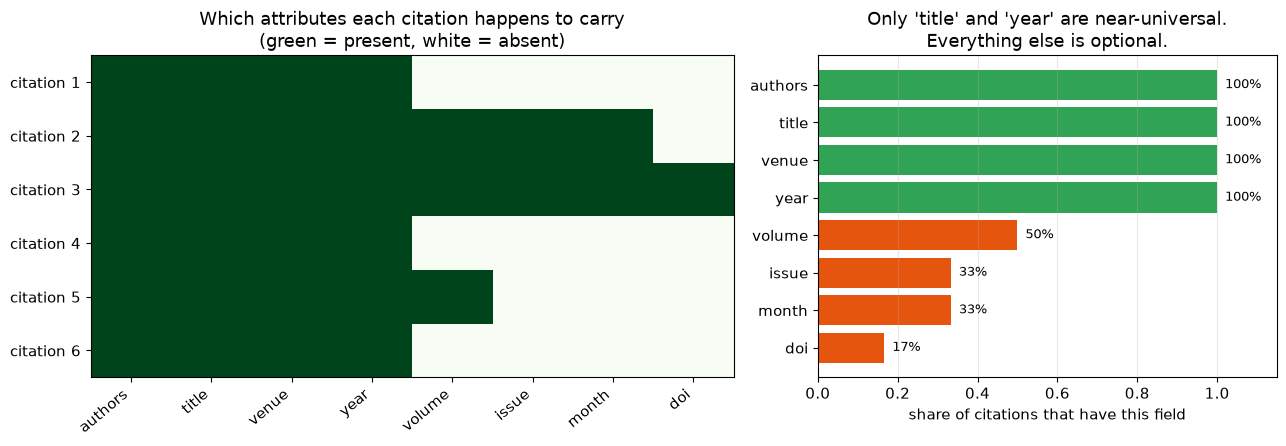

In [71]:
# Visualise the raggedness. Add a few more citations so the pattern is visible.

more_citations = [
    'A. Smith and B. Jones, "Networked Publics and Civic Talk," Journal of Communication, '
    'Vol. 71, Issue 3, June 2021, doi:10.1093/joc/abc123.',
    'C. Nakamura, "Field Notes on Algorithmic Management," Working Paper, 2023.',
    'D. Okafor, E. Rossi, F. Chen, and G. Patel, "Survey Nonresponse in Mobile Panels," '
    'Public Opinion Quarterly, Vol. 88, 2024.',
    'H. Weber, "Untitled Dataset Documentation," 2019.',
]
all_citations = citations + more_citations
all_parsed = pd.DataFrame([parse_citation(c) for c in all_citations])
all_parsed["authors"] = all_parsed["authors"].apply(lambda lst: "; ".join(lst))

fields = ["authors", "title", "venue", "year", "volume", "issue", "month", "doi"]
presence = all_parsed[fields].notna().astype(int).values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})

ax1.imshow(presence, cmap="Greens", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
ax1.set_xticks(range(len(fields)))
ax1.set_xticklabels(fields, rotation=40, ha="right")
ax1.set_yticks(range(len(all_citations)))
ax1.set_yticklabels([f"citation {i+1}" for i in range(len(all_citations))])
ax1.grid(visible=False)
ax1.set_title("Which attributes each citation happens to carry\n(green = present, white = absent)")

share = presence.mean(axis=0)
ax2.barh(fields, share, color=["#31a354" if s == 1 else "#e6550d" for s in share])
for i, s in enumerate(share):
    ax2.text(s + 0.02, i, f"{s:.0%}", va="center", fontsize=9)
ax2.set_xlim(0, 1.15)
ax2.set_xlabel("share of citations that have this field")
ax2.set_title("Only 'title' and 'year' are near-universal.\nEverything else is optional.")
ax2.invert_yaxis()
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()


In [72]:
# Semi-structured data is often SHIPPED as JSON rather than as a table, precisely because
# JSON tolerates missing and nested fields. Here is the same information as JSON.

import json

record = parse_citation(citations[1])
print(json.dumps(record, indent=2))

print("\nNotice: 'authors' is a LIST inside a record. A table cell cannot hold a list cleanly,")
print("which is exactly why we had to squash it into 'K. Kaemarungsi; P. Krishnamurthy' above.")
print("Every conversion from semi-structured to structured loses or distorts something.")


{
  "title": "Analysis of WLAN's Received Signal Strength Indication for Indoor Location Fingerprinting",
  "authors": [
    "K. Kaemarungsi",
    "P. Krishnamurthy"
  ],
  "n_authors": 2,
  "year": 2012,
  "venue": "Elsevier Pervasive and Mobile Computing",
  "volume": 8,
  "issue": 2,
  "month": "April",
  "doi": null
}

Notice: 'authors' is a LIST inside a record. A table cell cannot hold a list cleanly,
which is exactly why we had to squash it into 'K. Kaemarungsi; P. Krishnamurthy' above.
Every conversion from semi-structured to structured loses or distorts something.


### 10.2 A priori vs. a posteriori (slide 31)

This is the distinction to carry away:

- **A priori structure** — the data were *designed* to be data. A survey with fixed response
  options; a bank's transaction database. Fields exist because someone decided they would.
- **A posteriori structure** — the structure is *imposed afterwards* by an analyst on records that
  were created for a completely different purpose. Citations were written to credit colleagues, not
  to populate your database.

Almost all the exciting data in computational social science is a posteriori: tweets, court
opinions, obituaries, Kindle logs, transit card swipes. And a posteriori data carry a permanent
hazard: **the categories are yours, not the world's.** Our `parse_citation` function decided that
"venue" is a thing. The authors never agreed to that.

> This connects directly back to Section 2. The parser *is* a measuring instrument. It has
> resolution limits (it cannot see a subtitle), range limits (no DOI field in older citations), and
> noise (it will mangle an author named "Smith, Jr.").


In [73]:
# Proof that the parser is a fallible instrument. Feed it awkward but perfectly normal citations.

awkward = [
    'Smith, Jr., J. R., "A Study, With Commas, in the Title," Journal of Things, 2020.',
    'World Health Organization, "Global Report," Geneva, 2022.',
    'Anonymous, untitled manuscript, circa 1890.',
]
for c in awkward:
    r = parse_citation(c)
    print(f"INPUT : {c}")
    print(f"  title  -> {r['title']}")
    print(f"  authors-> {r['authors']}")
    print(f"  year   -> {r['year']}")
    print()

print("Failure modes visible above: a comma inside a title, an organisation treated as a person,")
print("and a date the pattern cannot read. In a corpus of 50,000 citations, these become")
print("thousands of quietly wrong rows -- which then look like clean structured data to whoever")
print("uses your table next.")


INPUT : Smith, Jr., J. R., "A Study, With Commas, in the Title," Journal of Things, 2020.
  title  -> A Study, With Commas, in the Title
  authors-> ['Smith', 'Jr.', 'J. R.']
  year   -> 2020

INPUT : World Health Organization, "Global Report," Geneva, 2022.
  title  -> Global Report
  authors-> ['World Health Organization']
  year   -> 2022

INPUT : Anonymous, untitled manuscript, circa 1890.
  title  -> None
  authors-> ['Anonymous', 'untitled manuscript', 'circa 1890.']
  year   -> None

Failure modes visible above: a comma inside a title, an organisation treated as a person,
and a date the pattern cannot read. In a corpus of 50,000 citations, these become
thousands of quietly wrong rows -- which then look like clean structured data to whoever
uses your table next.


---
---

# Section 11 — Unstructured text data

**Slide 25.** Letters, essays, speeches, books, surveys, and conversations have been used to
understand society for a very long time. The slide splits them in two:

| **Designed data** | **Found data** |
|---|---|
| Open-ended survey responses | Magazine / newspaper articles |
| Journal entries respondents are asked to write | Letters, personal ads |
| Transcripts of interviews | College application essays |
| | Autobiographies, speeches |

*Designed* data exist because a researcher asked for them. *Found* data existed anyway. (Same
a-priori/a-posteriori split as Section 10.)

Slide 21 also mentions **N-grams** and the Google N-Gram Viewer, and slide 36 uses the word
**tokenization**. Text analysis is where all three meet — so this section covers turning text into
numbers, and Section 15 covers the *other*, financial meaning of "tokenization".


In [74]:
# A tiny corpus. To keep everything original and copyright-clean, these are written for this
# notebook -- three imagined open-ended survey responses (DESIGNED data) and three imagined
# excerpts of civic writing (FOUND data).

designed_responses = [
    "The bus is usually on time but the app never shows the right arrival, so I leave early "
    "and wait in the cold. I would ride more if the app were honest.",
    "I gave up on the bus after the app told me it was two minutes away three times in a row. "
    "Now I drive, which I hate, and parking costs more than the fare ever did.",
    "Service is fine on weekdays. On Sunday the wait is so long that I just stay home, so I "
    "would say the schedule, not the buses, is the problem.",
]

found_texts = [
    "Council heard testimony on the transit levy for two hours. Riders described missed shifts, "
    "cold platforms, and an app that reports phantom buses. The board promised a review.",
    "Our neighborhood association writes to object to the proposed route change. The route as it "
    "stands carries workers to the hospital; the new route carries them past it.",
    "A letter to the editor: the buses are not the problem and never were. Fund the schedule, "
    "fix the app, and stop asking riders to be grateful for a service they pay for.",
]

corpus = designed_responses + found_texts
labels = ["designed"] * 3 + ["found"] * 3

for label, text in zip(labels, corpus):
    print(f"[{label:>8}] {len(text):>3} characters, {len(text.split()):>3} whitespace-separated words")
print(f"\nTotal corpus size: {sum(len(t) for t in corpus)} characters. This is UNSTRUCTURED data:")
print("no rows, no columns, no fields. Just characters.")


[designed] 150 characters,  32 whitespace-separated words
[designed] 162 characters,  36 whitespace-separated words
[designed] 141 characters,  29 whitespace-separated words
[   found] 174 characters,  28 whitespace-separated words
[   found] 167 characters,  28 whitespace-separated words
[   found] 167 characters,  33 whitespace-separated words

Total corpus size: 961 characters. This is UNSTRUCTURED data:
no rows, no columns, no fields. Just characters.


### 11.1 Tokenization (the text-analysis meaning)

**Tokenizing** text means chopping it into countable units — usually words. It sounds trivial and is
not: every decision you make here is a modelling decision that will show up in your results.

- Do you lowercase? (Then `Bus` and `bus` are the same — but so are `US` and `us`.)
- Do you strip punctuation? (Then `don't` becomes `dont`, or `don` and `t`.)
- Do you remove **stop words** (`the`, `and`, `of`)? (Usually yes for topic work, usually **no** for
  authorship or style work, where function words carry the signal.)


In [75]:
from collections import Counter

def tokenize(text, lowercase=True, strip_punctuation=True):
    # The simplest defensible tokenizer. Each option is a research decision, not a detail.
    if lowercase:
        text = text.lower()
    if strip_punctuation:
        # Keep letters, digits, and apostrophes inside words; turn everything else into a space.
        text = re.sub(r"[^a-z0-9']+" if lowercase else r"[^A-Za-z0-9']+", " ", text)
    return [t.strip("'") for t in text.split() if t.strip("'")]

sample = designed_responses[0]
print("ORIGINAL:")
print(f"   {sample}\n")
print("TOKENS (lowercased, punctuation stripped):")
print("  ", tokenize(sample), "\n")
print("TOKENS (case kept, punctuation kept):")
print("  ", tokenize(sample, lowercase=False, strip_punctuation=False))

a = tokenize(sample)
b = tokenize(sample, lowercase=False, strip_punctuation=False)
print(f"\nToken COUNTS: {len(a)} vs {len(b)} -- identical here.")
print(f"Distinct token counts: {len(set(a))} vs {len(set(b))} -- NOT identical.")
print("Tokens that differ between the two versions:")
print("  ", sorted(set(b) - set(a))[:8], "...")
print("So 'the' and 'The' are two words to the second tokenizer and one to the first, and")
print("'cold.' still carries its full stop. Small choices, different vocabularies, different results.")


ORIGINAL:
   The bus is usually on time but the app never shows the right arrival, so I leave early and wait in the cold. I would ride more if the app were honest.

TOKENS (lowercased, punctuation stripped):
   ['the', 'bus', 'is', 'usually', 'on', 'time', 'but', 'the', 'app', 'never', 'shows', 'the', 'right', 'arrival', 'so', 'i', 'leave', 'early', 'and', 'wait', 'in', 'the', 'cold', 'i', 'would', 'ride', 'more', 'if', 'the', 'app', 'were', 'honest'] 

TOKENS (case kept, punctuation kept):
   ['The', 'bus', 'is', 'usually', 'on', 'time', 'but', 'the', 'app', 'never', 'shows', 'the', 'right', 'arrival,', 'so', 'I', 'leave', 'early', 'and', 'wait', 'in', 'the', 'cold.', 'I', 'would', 'ride', 'more', 'if', 'the', 'app', 'were', 'honest.']

Token COUNTS: 32 vs 32 -- identical here.
Distinct token counts: 26 vs 27 -- NOT identical.
Tokens that differ between the two versions:
   ['I', 'The', 'arrival,', 'cold.', 'honest.'] ...
So 'the' and 'The' are two words to the second tokenizer and on

Total tokens in corpus       : 186
Distinct tokens (vocabulary) : 110
Type-token ratio             : 0.591   (higher = more varied vocabulary)



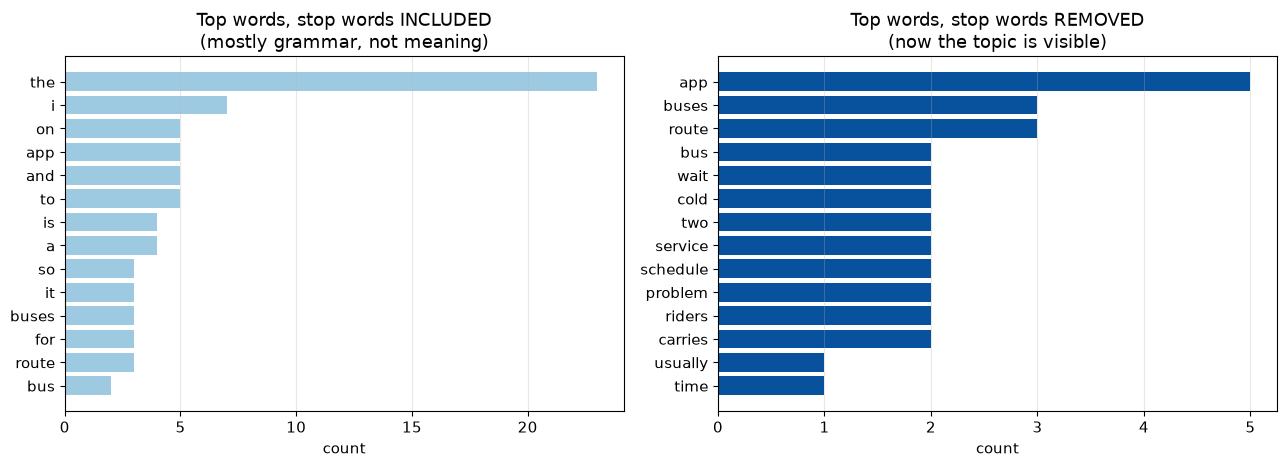

Removing stop words revealed the topic: app, bus, route, schedule, riders.
But it also DESTROYED the ability to study style, politeness, or hedging.
There is no neutral preprocessing. (Compare Section 14 on metadata being 'destructive'.)


In [76]:
# Count words across the whole corpus, with and without stop words.

STOP_WORDS = {
    "the", "a", "an", "and", "or", "but", "if", "so", "to", "of", "in", "on", "at", "for",
    "is", "are", "was", "were", "be", "been", "it", "its", "this", "that", "as", "by", "with",
    "i", "we", "they", "he", "she", "you", "me", "my", "our", "their", "would", "not", "no",
    "than", "then", "there", "which", "who", "what", "from", "more", "never", "just", "now",
}

all_tokens = [tok for text in corpus for tok in tokenize(text)]
counts_all = Counter(all_tokens)
counts_content = Counter(t for t in all_tokens if t not in STOP_WORDS)

print(f"Total tokens in corpus       : {len(all_tokens)}")
print(f"Distinct tokens (vocabulary) : {len(counts_all)}")
print(f"Type-token ratio             : {len(counts_all)/len(all_tokens):.3f}"
      "   (higher = more varied vocabulary)\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

top_all = counts_all.most_common(14)[::-1]
ax1.barh([w for w, _ in top_all], [c for _, c in top_all], color="#9ecae1")
ax1.set_xlabel("count")
ax1.set_title("Top words, stop words INCLUDED\n(mostly grammar, not meaning)")

top_content = counts_content.most_common(14)[::-1]
ax2.barh([w for w, _ in top_content], [c for _, c in top_content], color="#08519c")
ax2.set_xlabel("count")
ax2.set_title("Top words, stop words REMOVED\n(now the topic is visible)")

for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("Removing stop words revealed the topic: app, bus, route, schedule, riders.")
print("But it also DESTROYED the ability to study style, politeness, or hedging.")
print("There is no neutral preprocessing. (Compare Section 14 on metadata being 'destructive'.)")


tokens : ['the', 'app', 'never', 'shows', 'the', 'right', 'arrival', 'time']
bigrams: ['the app', 'app never', 'never shows', 'shows the', 'the right', 'right arrival', 'arrival time']
trigrams: ['the app never', 'app never shows', 'never shows the', 'shows the right', 'the right arrival', 'right arrival time']

  n   distinct n-grams OBSERVED    n-grams POSSIBLE (V^n)   % observed
  1                         110                       110    100.0000%
  2                         167                    12,100      1.3802%
  3                         174                 1,331,000      0.0131%

That last column is SPARSITY, and it is the whole problem. With a 110-word vocabulary
there are 12,100 possible word pairs and we observed 167 of them. Real corpora have
vocabularies in the hundreds of thousands, so the possible 3-grams outnumber the atoms
you could ever collect text about. This is why n-gram studies need enormous corpora --
hence Google's use of millions of books.


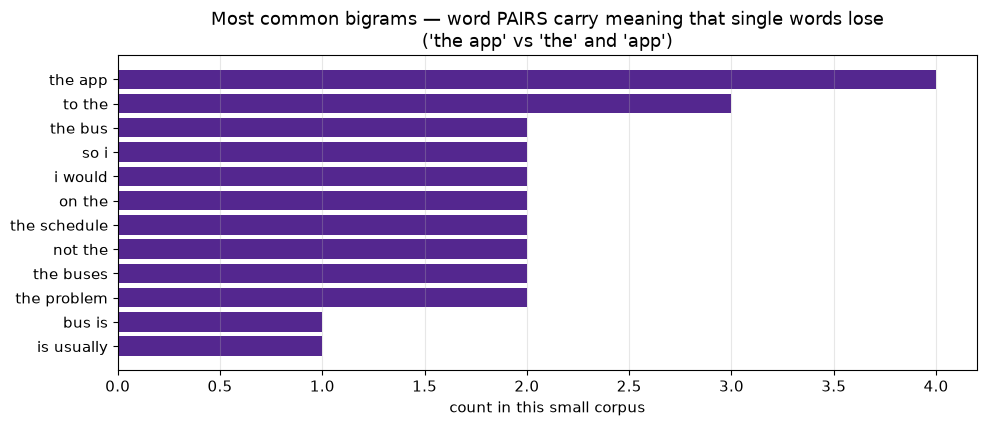

In [77]:
# N-GRAMS (slide 21). An n-gram is a run of n consecutive tokens.
# 1-gram = word. 2-gram (bigram) = word pair. This is what the Google N-Gram Viewer counts,
# across millions of books and across time.

def ngrams(tokens, n):
    # zip() lines up the token list with shifted copies of itself.
    return [" ".join(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

demo = tokenize("the app never shows the right arrival time")
print("tokens :", demo)
print("bigrams:", ngrams(demo, 2))
print("trigrams:", ngrams(demo, 3))
print()

bigram_counts = Counter(bg for text in corpus for bg in ngrams(tokenize(text), 2))
trigram_counts = Counter(tg for text in corpus for tg in ngrams(tokenize(text), 3))

V = len(counts_all)
print(f"{'n':>3}{'distinct n-grams OBSERVED':>28}{'n-grams POSSIBLE (V^n)':>26}{'% observed':>13}")
for n, observed in [(1, len(counts_all)), (2, len(bigram_counts)), (3, len(trigram_counts))]:
    possible = V ** n
    print(f"{n:>3}{observed:>28,}{possible:>26,}{100*observed/possible:>12.4f}%")

print("\nThat last column is SPARSITY, and it is the whole problem. With a 110-word vocabulary")
print("there are 12,100 possible word pairs and we observed 167 of them. Real corpora have")
print("vocabularies in the hundreds of thousands, so the possible 3-grams outnumber the atoms")
print("you could ever collect text about. This is why n-gram studies need enormous corpora --")
print("hence Google's use of millions of books.")

fig, ax = plt.subplots(figsize=(10, 4.4))
top_bg = bigram_counts.most_common(12)[::-1]
ax.barh([w for w, _ in top_bg], [c for _, c in top_bg], color="#54278f")
ax.set_xlabel("count in this small corpus")
ax.set_title("Most common bigrams — word PAIRS carry meaning that single words lose\n"
             "('the app' vs 'the' and 'app')")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()


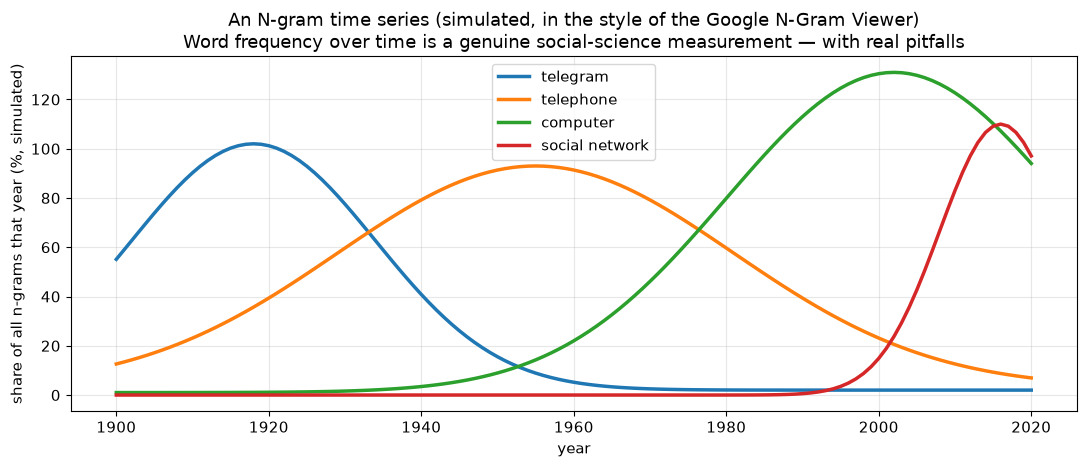

Pitfalls worth knowing before you cite an N-gram chart (all are Section 2 problems):
  * The corpus is books that were SCANNED, not books that were WRITTEN. Mis-sampling.
  * Library holdings change over time, so the denominator moves under you.
  * OCR errors on old print inflate some tokens and erase others. Instrument noise.
  * A word's frequency is not its meaning. 'Gay' in 1900 and 2000 are different words.


In [78]:
# A Google-N-Gram-style picture: how a phrase's usage changes over time.
# We SIMULATE the counts (we have no corpus of books here), but the shape of the analysis
# and the way you read the chart are exactly the real thing.

years = np.arange(1900, 2021)

def simulated_usage(peak_year, width, height, baseline=0.0):
    return baseline + height * np.exp(-0.5 * ((years - peak_year) / width) ** 2)

phrases = {
    "telegram":       simulated_usage(1918, 16, 1.0, 0.02),
    "telephone":      simulated_usage(1955, 26, 0.9, 0.03),
    "computer":       simulated_usage(2002, 22, 1.3, 0.01),
    "social network": simulated_usage(2016, 8, 1.1, 0.00),
}

fig, ax = plt.subplots(figsize=(11, 4.8))
for phrase, series in phrases.items():
    ax.plot(years, series * 100, linewidth=2.5, label=phrase)
ax.set_xlabel("year")
ax.set_ylabel("share of all n-grams that year (%, simulated)")
ax.set_title("An N-gram time series (simulated, in the style of the Google N-Gram Viewer)\n"
             "Word frequency over time is a genuine social-science measurement — with real pitfalls")
ax.legend()
plt.tight_layout()
plt.show()

print("Pitfalls worth knowing before you cite an N-gram chart (all are Section 2 problems):")
print("  * The corpus is books that were SCANNED, not books that were WRITTEN. Mis-sampling.")
print("  * Library holdings change over time, so the denominator moves under you.")
print("  * OCR errors on old print inflate some tokens and erase others. Instrument noise.")
print("  * A word's frequency is not its meaning. 'Gay' in 1900 and 2000 are different words.")


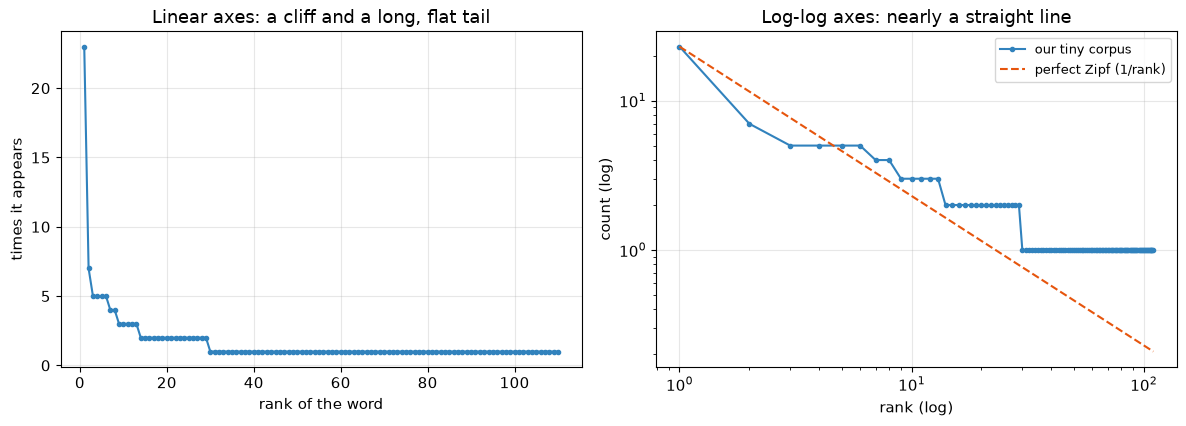

Practical consequence: a few words dominate, and MOST of the vocabulary appears once.
In this corpus, 81 of 110 distinct words appear exactly once.
Any text method must cope with a huge tail of rare words. That is a structural fact,
not a defect of our small sample.


In [79]:
# Zipf's law: in any natural-language corpus, the most common word is roughly twice as common as
# the second, three times the third, and so on. On log-log axes it is a straight line.
# This is one of the most robust empirical regularities in the social sciences.

ranked = np.array([c for _, c in counts_all.most_common()])
ranks = np.arange(1, len(ranked) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

ax1.plot(ranks, ranked, marker="o", markersize=3, color="#3182bd")
ax1.set_xlabel("rank of the word")
ax1.set_ylabel("times it appears")
ax1.set_title("Linear axes: a cliff and a long, flat tail")

ax2.loglog(ranks, ranked, marker="o", markersize=3, color="#3182bd", label="our tiny corpus")
ax2.loglog(ranks, ranked[0] / ranks, "--", color="#e6550d", label="perfect Zipf (1/rank)")
ax2.set_xlabel("rank (log)")
ax2.set_ylabel("count (log)")
ax2.set_title("Log-log axes: nearly a straight line")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Practical consequence: a few words dominate, and MOST of the vocabulary appears once.")
print(f"In this corpus, {sum(1 for c in ranked if c == 1)} of {len(ranked)} distinct words appear exactly once.")
print("Any text method must cope with a huge tail of rare words. That is a structural fact,")
print("not a defect of our small sample.")


### 11.2 Designed vs. found data, measured

Can we *see* the difference between the slide's two categories? Sometimes, yes: designed responses
tend to be more first-person and more concrete; found civic writing tends toward institutional
vocabulary. This is a real (if crude) form of computational text analysis.


source_type  n_words  n_distinct  type_token_ratio  first_person_rate  institutional_rate  mean_word_length
   designed       32          26             0.812              0.062               0.000             3.625
   designed       36          32             0.889              0.111               0.000             3.417
   designed       29          21             0.724              0.069               0.000             3.724
      found       28          27             0.964              0.000               0.179             5.071
      found       28          19             0.679              0.036               0.179             4.893
      found       33          25             0.758              0.000               0.061             3.939

Group averages:
             n_words  n_distinct  type_token_ratio  first_person_rate  institutional_rate  mean_word_length
source_type                                                                                                
designed   

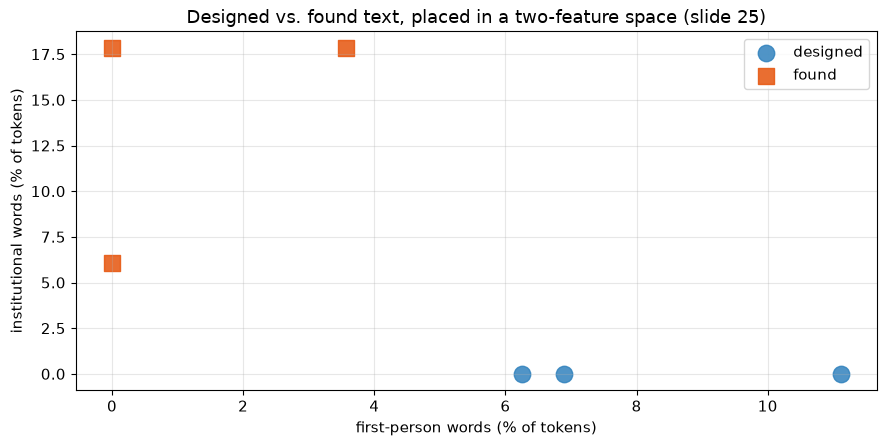

With six documents this is an illustration, not a finding. With 6,000 it would be a method.


In [80]:
# Build a small feature table FROM TEXT. Notice what just happened:
# unstructured data -> structured table. That is slide 26's remark that structured data is
# 'often the output of processing semi- and unstructured data'.

FIRST_PERSON = {"i", "me", "my", "we", "our", "us"}
INSTITUTIONAL = {"council", "board", "association", "levy", "testimony", "proposed",
                 "editor", "review", "fund", "route"}

rows = []
for label, text in zip(labels, corpus):
    toks = tokenize(text)
    rows.append({
        "source_type": label,
        "n_words": len(toks),
        "n_distinct": len(set(toks)),
        "type_token_ratio": len(set(toks)) / len(toks),
        "first_person_rate": sum(t in FIRST_PERSON for t in toks) / len(toks),
        "institutional_rate": sum(t in INSTITUTIONAL for t in toks) / len(toks),
        "mean_word_length": np.mean([len(t) for t in toks]),
    })
text_features = pd.DataFrame(rows)
print(text_features.round(3).to_string(index=False))

print("\nGroup averages:")
print(text_features.groupby("source_type").mean(numeric_only=True).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.6))
for source, colour, marker in [("designed", "#3182bd", "o"), ("found", "#e6550d", "s")]:
    sub = text_features[text_features["source_type"] == source]
    ax.scatter(sub["first_person_rate"] * 100, sub["institutional_rate"] * 100,
               s=140, color=colour, marker=marker, label=source, alpha=0.85)
ax.set_xlabel("first-person words (% of tokens)")
ax.set_ylabel("institutional words (% of tokens)")
ax.set_title("Designed vs. found text, placed in a two-feature space (slide 25)")
ax.legend()
plt.tight_layout()
plt.show()

print("With six documents this is an illustration, not a finding. With 6,000 it would be a method.")


> ### Summary of Section 11
> - Tokenization turns text into countable units, and every option (case, punctuation, stop words)
>   changes the results. Record your choices — they are part of your method.
> - N-grams are runs of n tokens. Bigger n means richer context and far sparser counts.
> - Zipf's law: a few words dominate; most words appear once. Plan for the tail.
> - Text features turn unstructured data into a structured table, which is where Sections 7–9 pick
>   back up.

---
---

# Section 12 — Network (graph) data

**Slide 32.** Networks are made of:

- **Nodes** (also called *vertices*) — the things.
- **Links** (also called *edges* or *ties*) — the connections between things.

The slide's own example is a co-authorship network drawn from the two citations in Section 10:
**Krishnamurthy, Pelechrinis, Kaemarungsi, Gkantsidis.** The slide notes other kinds too:
transportation networks, the Internet, the social graph, concept graphs.

Network data breaks the tidy table of Section 7. The unit of analysis is a *relationship*, and
relationships do not fit in one cell.


In [81]:
# The simplest way to store a network: an EDGE LIST. One row per relationship.
# Built from the two citations on slide 30, exactly as the slide-32 diagram shows.

edges = [
    ("Pelechrinis", "Krishnamurthy"),   # paper 1: all three authors are mutually connected
    ("Pelechrinis", "Gkantsidis"),
    ("Krishnamurthy", "Gkantsidis"),
    ("Kaemarungsi", "Krishnamurthy"),   # paper 2: two authors
]

edge_table = pd.DataFrame(edges, columns=["author_a", "author_b"])
print("The network as an edge list -- this IS the dataset:")
print(edge_table.to_string(index=False))

nodes = sorted({name for edge in edges for name in edge})
print(f"\nNodes (vertices): {nodes}")
print(f"Number of nodes: {len(nodes)}   Number of edges (ties): {len(edges)}")


The network as an edge list -- this IS the dataset:
     author_a      author_b
  Pelechrinis Krishnamurthy
  Pelechrinis    Gkantsidis
Krishnamurthy    Gkantsidis
  Kaemarungsi Krishnamurthy

Nodes (vertices): ['Gkantsidis', 'Kaemarungsi', 'Krishnamurthy', 'Pelechrinis']
Number of nodes: 4   Number of edges (ties): 4


In [82]:
# The other standard storage form: an ADJACENCY MATRIX. Rows and columns are both nodes;
# a 1 means 'connected'. Same information, completely different shape.

adjacency = pd.DataFrame(0, index=nodes, columns=nodes)
for a, b in edges:
    adjacency.loc[a, b] = 1
    adjacency.loc[b, a] = 1        # undirected: co-authorship goes both ways

print("Adjacency matrix:")
print(adjacency.to_string())

# DEGREE = how many ties a node has. The simplest and most useful network statistic.
degree = adjacency.sum(axis=1).sort_values(ascending=False)
print("\nDegree (number of co-authors):")
print(degree.to_string())
print(f"\nDensity = actual edges / possible edges = {len(edges)}/{len(nodes)*(len(nodes)-1)//2}"
      f" = {len(edges)/(len(nodes)*(len(nodes)-1)/2):.2f}")


Adjacency matrix:
               Gkantsidis  Kaemarungsi  Krishnamurthy  Pelechrinis
Gkantsidis              0            0              1            1
Kaemarungsi             0            0              1            0
Krishnamurthy           1            1              0            1
Pelechrinis             1            0              1            0

Degree (number of co-authors):
Krishnamurthy    3
Gkantsidis       2
Pelechrinis      2
Kaemarungsi      1

Density = actual edges / possible edges = 4/6 = 0.67


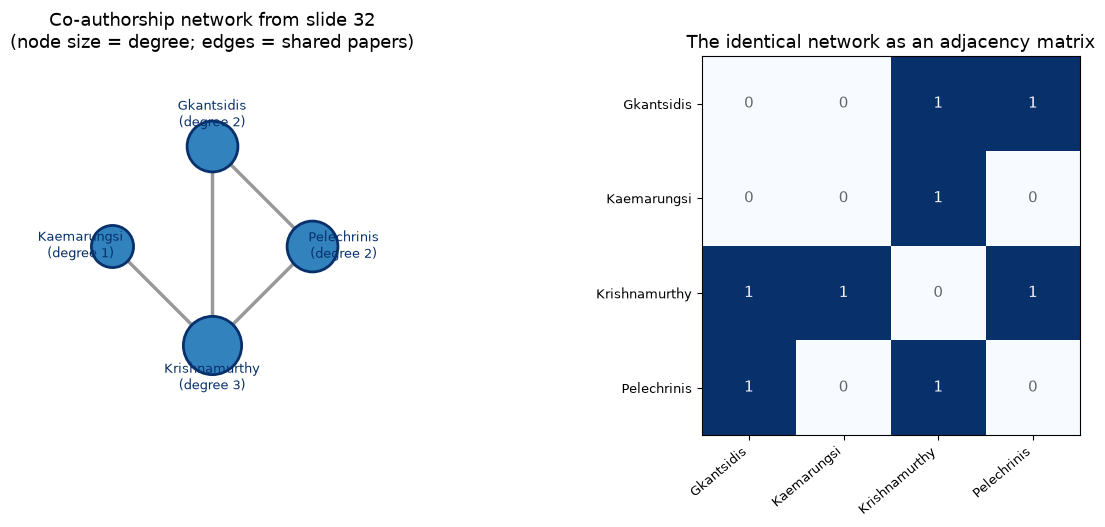

In [83]:
# Draw the network. We place the nodes by hand (a 'circular layout') so this cell needs no
# extra libraries. Real network drawing uses algorithms that push connected nodes together.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})

# --- Left panel: the graph drawing ---
angles = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi, len(nodes), endpoint=False)
positions = {name: (np.cos(a), np.sin(a)) for name, a in zip(nodes, angles)}

for a, b in edges:                              # draw edges FIRST so nodes sit on top
    x1, y1 = positions[a]
    x2, y2 = positions[b]
    ax1.plot([x1, x2], [y1, y2], color="#999999", linewidth=2.5, zorder=1)

for name, (x, y) in positions.items():
    size = 500 + 420 * degree[name]             # node size shows degree
    ax1.scatter([x], [y], s=size, color="#3182bd", edgecolor="#08306b", linewidth=2, zorder=2)
    # Labels go OUTSIDE the circles, pushed away from the centre, so nothing is clipped.
    ax1.text(x * 1.32, y * 1.32, f"{name}\n(degree {degree[name]})",
             ha="center", va="center", fontsize=9, color="#08306b", zorder=3)

ax1.set_xlim(-2.0, 2.0); ax1.set_ylim(-1.9, 1.9)
ax1.set_aspect("equal"); ax1.axis("off")
ax1.set_title("Co-authorship network from slide 32\n(node size = degree; edges = shared papers)")

# --- Right panel: the same data as a heatmap ---
im = ax2.imshow(adjacency.values, cmap="Blues", vmin=0, vmax=1)
ax2.set_xticks(range(len(nodes))); ax2.set_xticklabels(nodes, rotation=40, ha="right", fontsize=9)
ax2.set_yticks(range(len(nodes))); ax2.set_yticklabels(nodes, fontsize=9)
ax2.grid(visible=False)
for i in range(len(nodes)):
    for j in range(len(nodes)):
        ax2.text(j, i, adjacency.values[i, j], ha="center", va="center", fontsize=11,
                 color="white" if adjacency.values[i, j] else "#666666")
ax2.set_title("The identical network as an adjacency matrix")

plt.tight_layout()
plt.show()


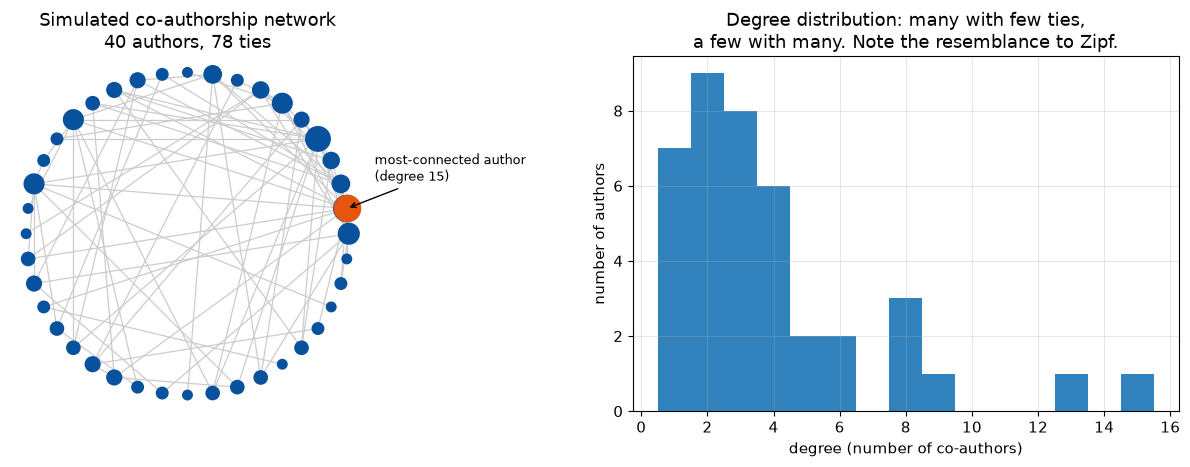

Mean degree   : 3.90
Median degree : 3
Max degree    : 15  (author #1)

Mean and median disagree badly. In skewed networks the AVERAGE describes almost nobody --
the same warning as Section 2's histograms, in a network setting.


In [84]:
# A larger, more interesting network so the statistics mean something.
# We simulate a co-authorship network of 40 researchers with a 'rich get richer' rule
# (preferential attachment): new authors are more likely to co-write with well-connected ones.
# This produces the lopsided degree distribution real collaboration networks actually have.

N_AUTHORS = 40
sim_edges = [(0, 1)]
degrees = {0: 1, 1: 1}

for new in range(2, N_AUTHORS):
    existing = list(degrees.keys())
    weights = np.array([degrees[a] for a in existing], dtype=float)
    weights /= weights.sum()
    n_links = min(rng.integers(1, 4), len(existing))
    partners = rng.choice(existing, size=n_links, replace=False, p=weights)
    for partner in partners:
        sim_edges.append((new, int(partner)))
        degrees[int(partner)] = degrees[int(partner)] + 1
    degrees[new] = n_links

sim_degree = pd.Series(degrees).sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Layout: a circle again, but now with 40 nodes.
ang = np.linspace(0, 2 * np.pi, N_AUTHORS, endpoint=False)
pos = {i: (np.cos(a), np.sin(a)) for i, a in enumerate(ang)}
for a, b in sim_edges:
    ax1.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]],
             color="#cccccc", linewidth=0.9, zorder=1)
ax1.scatter([pos[i][0] for i in range(N_AUTHORS)], [pos[i][1] for i in range(N_AUTHORS)],
            s=[25 + 22 * sim_degree[i] for i in range(N_AUTHORS)],
            color="#08519c", zorder=2)
hub = int(sim_degree.idxmax())
ax1.scatter([pos[hub][0]], [pos[hub][1]], s=25 + 22 * sim_degree[hub],
            color="#e6550d", zorder=3)
ax1.annotate(f"most-connected author\n(degree {sim_degree[hub]})",
             pos[hub], textcoords="offset points", xytext=(20, 20), fontsize=9,
             arrowprops=dict(arrowstyle="->"))
ax1.set_aspect("equal"); ax1.axis("off")
ax1.set_title(f"Simulated co-authorship network\n{N_AUTHORS} authors, {len(sim_edges)} ties")

ax2.hist(sim_degree.values, bins=range(1, sim_degree.max() + 2), color="#3182bd", align="left")
ax2.set_xlabel("degree (number of co-authors)")
ax2.set_ylabel("number of authors")
ax2.set_title("Degree distribution: many with few ties,\na few with many. Note the resemblance to Zipf.")
plt.tight_layout()
plt.show()

print(f"Mean degree   : {sim_degree.mean():.2f}")
print(f"Median degree : {sim_degree.median():.0f}")
print(f"Max degree    : {sim_degree.max()}  (author #{hub})")
print("\nMean and median disagree badly. In skewed networks the AVERAGE describes almost nobody --")
print("the same warning as Section 2's histograms, in a network setting.")


networkx summary of the slide-32 network:
   nodes: 4   edges: 4
   density: 0.667

   degree centrality (share of others each author is tied to):
      Krishnamurthy    1.000
      Pelechrinis      0.667
      Gkantsidis       0.667
      Kaemarungsi      0.333

   betweenness centrality (how often an author sits on the shortest path
   between two others -- a measure of brokerage):
      Krishnamurthy    0.667
      Pelechrinis      0.000
      Gkantsidis       0.000
      Kaemarungsi      0.000


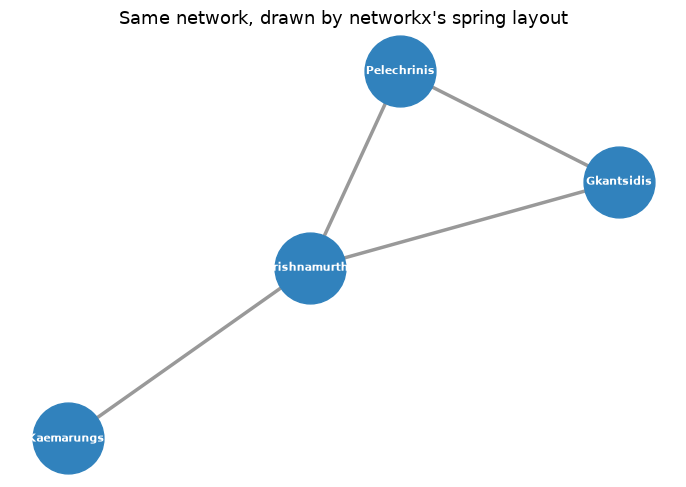

In [85]:
# OPTIONAL: the same analysis using networkx, the standard Python network library.
# If networkx is not installed this cell prints a note and moves on -- nothing breaks.

try:
    import networkx as nx

    G = nx.Graph()
    G.add_edges_from(edges)

    print("networkx summary of the slide-32 network:")
    print(f"   nodes: {G.number_of_nodes()}   edges: {G.number_of_edges()}")
    print(f"   density: {nx.density(G):.3f}")
    print("\n   degree centrality (share of others each author is tied to):")
    for name, value in sorted(nx.degree_centrality(G).items(), key=lambda kv: -kv[1]):
        print(f"      {name:<16} {value:.3f}")
    print("\n   betweenness centrality (how often an author sits on the shortest path")
    print("   between two others -- a measure of brokerage):")
    for name, value in sorted(nx.betweenness_centrality(G).items(), key=lambda kv: -kv[1]):
        print(f"      {name:<16} {value:.3f}")

    fig, ax = plt.subplots(figsize=(7, 5))
    layout = nx.spring_layout(G, seed=3)     # an algorithm, not hand-placed
    nx.draw_networkx_edges(G, layout, ax=ax, width=2.5, edge_color="#999999")
    nx.draw_networkx_nodes(G, layout, ax=ax, node_size=2600, node_color="#3182bd")
    nx.draw_networkx_labels(G, layout, ax=ax, font_size=8, font_color="white",
                            font_weight="bold")
    ax.set_title("Same network, drawn by networkx's spring layout")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

except ImportError:
    print("networkx is not installed -- skipping this optional cell.")
    print("To install it, run this in a new cell:   %pip install networkx")


> ### Summary of Section 12
> - Networks = nodes + edges. Store them as an **edge list** (compact) or an **adjacency matrix**
>   (convenient for maths). They hold the same information.
> - **Degree** is the first thing to compute; **degree distributions are usually skewed**, so the
>   mean is a poor summary.
> - Betweenness identifies brokers — people whose removal disconnects others. In our tiny network,
>   Krishnamurthy is the broker, because Kaemarungsi reaches everyone else only through him.

---
---

# Section 13 — Taxonomic data

**Slide 33.** The slide's example is the **radio spectrum**, organised as a tree:

| Band | Frequency range | Typical uses (from the slide) |
|---|---|---|
| VLF | 3–30 kHz | submarine communication, navigation |
| LF | 30–300 kHz | maritime navigation, AM radio |
| MF | 300 kHz – 3 MHz | AM radio, maritime communication |
| HF | 3–30 MHz | shortwave, aviation communication |
| VHF | 30–300 MHz | FM radio, TV, two-way radios |
| UHF | 300 MHz – 3 GHz | TV, mobile, GPS, Wi-Fi |
| SHF | 3–30 GHz | satellite, radar, microwave links |
| EHF | 30–300 GHz | advanced radar, experimental |
| THF | 300 GHz – 3 THz | experimental, spectroscopy |

**Taxonomic data are hierarchical**: every item has a parent, and categories nest. This is a third
shape, distinct from tables (Section 7) and networks (Section 12) — though a taxonomy is really a
network with a rule (each node has exactly one parent, no loops), which is called a **tree**.

You will meet taxonomies constantly: occupational classifications (SOC), disease codes (ICD),
product categories, census geographies (nation → state → county → tract → block).


In [86]:
# A taxonomy as nested dictionaries. Notice the SI prefixes from Section 3 doing real work here.

radio_spectrum = {
    "Radio Spectrum": {
        "Low frequencies": {
            "VLF (3-30 kHz)":       {"low_hz": 3e3,   "high_hz": 3e4,  "uses": "submarine comm., navigation"},
            "LF (30-300 kHz)":      {"low_hz": 3e4,   "high_hz": 3e5,  "uses": "maritime navigation, AM radio"},
            "MF (300 kHz-3 MHz)":   {"low_hz": 3e5,   "high_hz": 3e6,  "uses": "AM radio, maritime comm."},
        },
        "Medium frequencies": {
            "HF (3-30 MHz)":        {"low_hz": 3e6,   "high_hz": 3e7,  "uses": "shortwave, aviation comm."},
            "VHF (30-300 MHz)":     {"low_hz": 3e7,   "high_hz": 3e8,  "uses": "FM radio, TV, two-way radios"},
            "UHF (300 MHz-3 GHz)":  {"low_hz": 3e8,   "high_hz": 3e9,  "uses": "TV, mobile, GPS, Wi-Fi"},
        },
        "High frequencies": {
            "SHF (3-30 GHz)":       {"low_hz": 3e9,   "high_hz": 3e10, "uses": "satellite, radar, microwave links"},
            "EHF (30-300 GHz)":     {"low_hz": 3e10,  "high_hz": 3e11, "uses": "advanced radar, experimental"},
            "THF (300 GHz-3 THz)":  {"low_hz": 3e11,  "high_hz": 3e12, "uses": "experimental, spectroscopy"},
        },
    }
}

# Walk the tree and print it as an indented outline. A function that calls ITSELF is 'recursive' --
# the natural way to handle a structure that nests to an unknown depth.
def print_tree(node, depth=0):
    for key, value in node.items():
        if isinstance(value, dict) and "low_hz" not in value:
            print("   " * depth + f"- {key}")
            print_tree(value, depth + 1)
        else:
            print("   " * depth + f"- {key}  ->  {value['uses']}")

print_tree(radio_spectrum)


- Radio Spectrum
   - Low frequencies
      - VLF (3-30 kHz)  ->  submarine comm., navigation
      - LF (30-300 kHz)  ->  maritime navigation, AM radio
      - MF (300 kHz-3 MHz)  ->  AM radio, maritime comm.
   - Medium frequencies
      - HF (3-30 MHz)  ->  shortwave, aviation comm.
      - VHF (30-300 MHz)  ->  FM radio, TV, two-way radios
      - UHF (300 MHz-3 GHz)  ->  TV, mobile, GPS, Wi-Fi
   - High frequencies
      - SHF (3-30 GHz)  ->  satellite, radar, microwave links
      - EHF (30-300 GHz)  ->  advanced radar, experimental
      - THF (300 GHz-3 THz)  ->  experimental, spectroscopy


In [87]:
# Flatten the tree into a table -- because Sections 7-9 need tables.
# Every taxonomy you analyse gets flattened sooner or later; keep the path so you can nest it again.

def flatten_tree(node, path=()):
    rows = []
    for key, value in node.items():
        if isinstance(value, dict) and "low_hz" not in value:
            rows.extend(flatten_tree(value, path + (key,)))
        else:
            rows.append({
                "path": " > ".join(path + (key,)),
                "level_1": path[0] if len(path) > 0 else None,
                "level_2": path[1] if len(path) > 1 else None,
                "band": key,
                "low_hz": value["low_hz"],
                "high_hz": value["high_hz"],
                "uses": value["uses"],
            })
    return rows

spectrum = pd.DataFrame(flatten_tree(radio_spectrum))
spectrum["bandwidth_hz"] = spectrum["high_hz"] - spectrum["low_hz"]
spectrum["low_readable"] = spectrum["low_hz"].apply(lambda v: humanise(v, "Hz", decimals=0))
spectrum["high_readable"] = spectrum["high_hz"].apply(lambda v: humanise(v, "Hz", decimals=0))

print(spectrum[["level_2", "band", "low_readable", "high_readable", "uses"]].to_string(index=False))


           level_2                band low_readable high_readable                              uses
   Low frequencies      VLF (3-30 kHz)        3 kHz        30 kHz       submarine comm., navigation
   Low frequencies     LF (30-300 kHz)       30 kHz       300 kHz     maritime navigation, AM radio
   Low frequencies  MF (300 kHz-3 MHz)      300 kHz         3 MHz          AM radio, maritime comm.
Medium frequencies       HF (3-30 MHz)        3 MHz        30 MHz         shortwave, aviation comm.
Medium frequencies    VHF (30-300 MHz)       30 MHz       300 MHz      FM radio, TV, two-way radios
Medium frequencies UHF (300 MHz-3 GHz)      300 MHz         3 GHz            TV, mobile, GPS, Wi-Fi
  High frequencies      SHF (3-30 GHz)        3 GHz        30 GHz satellite, radar, microwave links
  High frequencies    EHF (30-300 GHz)       30 GHz       300 GHz      advanced radar, experimental
  High frequencies THF (300 GHz-3 THz)      300 GHz         3 THz        experimental, spectroscopy


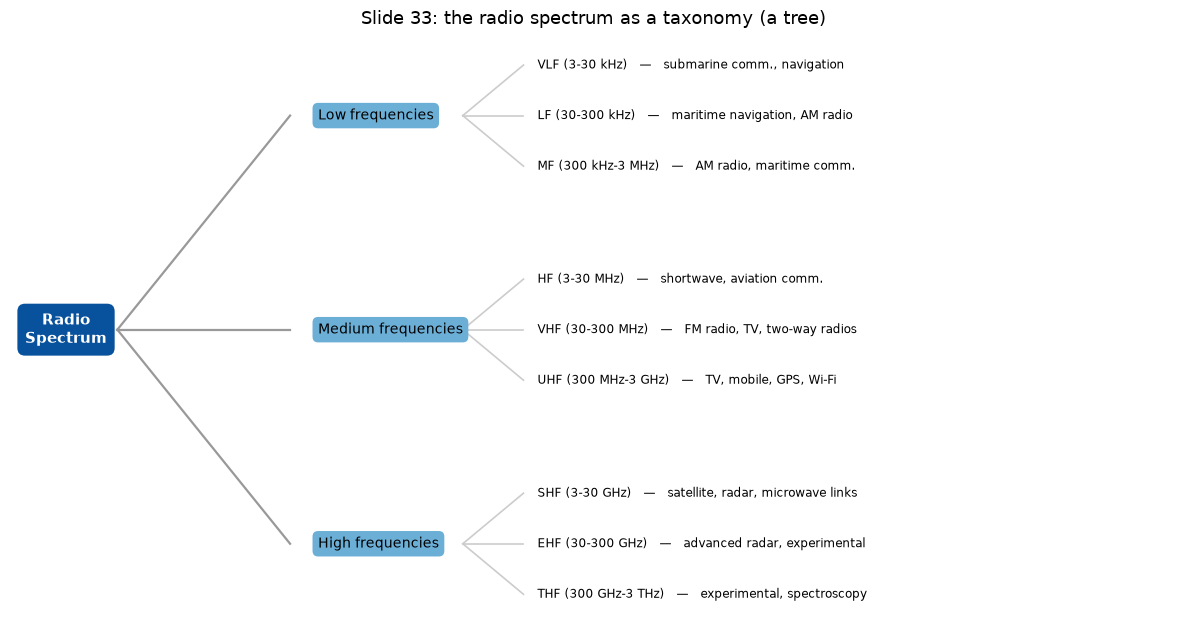

In [88]:
# Picture 1: the taxonomy as a tree diagram, drawn by hand from the flattened table.

fig, ax = plt.subplots(figsize=(12, 6.5))

groups = spectrum["level_2"].unique()
root_pos = (0.06, 0.5)
ax.text(*root_pos, "Radio\nSpectrum", ha="center", va="center", fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#08519c", edgecolor="none"), color="white")

group_y = np.linspace(0.86, 0.14, len(groups))
for gy, group in zip(group_y, groups):
    ax.plot([root_pos[0] + 0.055, 0.30], [root_pos[1], gy], color="#999999", linewidth=1.6)
    ax.text(0.33, gy, group, ha="left", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="#6baed6", edgecolor="none"))
    members = spectrum[spectrum["level_2"] == group]
    leaf_y = np.linspace(gy + 0.085, gy - 0.085, len(members))
    for ly, (_, row) in zip(leaf_y, members.iterrows()):
        ax.plot([0.485, 0.55], [gy, ly], color="#cccccc", linewidth=1.2)
        ax.text(0.565, ly, f"{row['band']}   —   {row['uses']}", ha="left", va="center", fontsize=8.5)

ax.set_xlim(0, 1.25); ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Slide 33: the radio spectrum as a taxonomy (a tree)", fontsize=13)
plt.tight_layout()
plt.show()


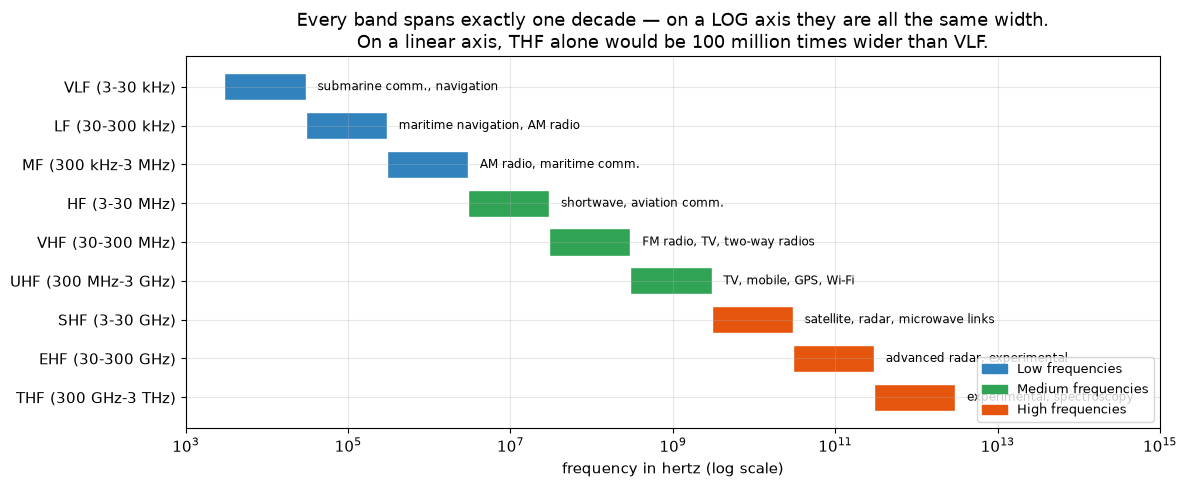

Bandwidth of each band, in plain numbers:
   VLF (3-30 kHz)             27 kHz
   LF (30-300 kHz)           270 kHz
   MF (300 kHz-3 MHz)          3 MHz
   HF (3-30 MHz)              27 MHz
   VHF (30-300 MHz)          270 MHz
   UHF (300 MHz-3 GHz)         3 GHz
   SHF (3-30 GHz)             27 GHz
   EHF (30-300 GHz)          270 GHz
   THF (300 GHz-3 THz)         3 THz

The categories look equal in the tree. They are wildly unequal in reality.
That is a general hazard of taxonomies: a tidy hierarchy implies a tidy world.


In [89]:
# Picture 2: the SAME taxonomy plotted on a logarithmic frequency axis.
# This is where taxonomies and Section 3's log scales meet -- and it reveals something the
# tree diagram completely hides.

fig, ax = plt.subplots(figsize=(12, 5))

colour_by_group = {"Low frequencies": "#3182bd", "Medium frequencies": "#31a354",
                   "High frequencies": "#e6550d"}

for i, (_, row) in enumerate(spectrum.iterrows()):
    ax.barh(i, width=row["high_hz"] - row["low_hz"], left=row["low_hz"],
            color=colour_by_group[row["level_2"]], edgecolor="white", height=0.7)
    ax.text(row["high_hz"] * 1.4, i, row["uses"], va="center", fontsize=8.5)

ax.set_yticks(range(len(spectrum)))
ax.set_yticklabels(spectrum["band"])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlim(1e3, 1e15)
ax.set_xlabel("frequency in hertz (log scale)")
ax.set_title("Every band spans exactly one decade — on a LOG axis they are all the same width.\n"
             "On a linear axis, THF alone would be 100 million times wider than VLF.")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colour_by_group.values()]
ax.legend(handles, colour_by_group.keys(), loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

print("Bandwidth of each band, in plain numbers:")
for _, row in spectrum.iterrows():
    print(f"   {row['band']:<22} {humanise(row['bandwidth_hz'], 'Hz', 0):>10}")
print("\nThe categories look equal in the tree. They are wildly unequal in reality.")
print("That is a general hazard of taxonomies: a tidy hierarchy implies a tidy world.")


> ### Summary of Section 13
> - Taxonomic data nest: each item has one parent. Stored as nested dictionaries, or as a table with
>   a `path` column, or as a parent-child edge list (a tree is a special network).
> - Flattening a tree into a table is routine and lossy — keep the path.
> - **A taxonomy's visual tidiness hides real inequality between its categories.** The nine radio
>   bands look like nine equal things in the tree, and span twelve orders of magnitude in reality.
>   The same is true of occupational and disease classifications you will meet in social data.


---
---

# Section 14 — Metadata: data about data

**Slides 34 and 35.** Slide 34 defines metadata as *data about data — ad infinitum?* and gives four
questions metadata answers:

1. Where did a piece of information come from?
2. Where in a classification does it belong?
3. What does the information contain?
4. How can one use this information?

Slide 35 then gives metadata three properties, and these three words are the most important thing in
this section:

- **Generative** — metadata generates more data.
- **Destructive** — it sidelines some perspectives and reinforces others.
- **Triangulated** — fused with other datasets, it can yield *"startling revelations."*

We will demonstrate all three, in that order.


### 14.1 The four questions: a data dictionary

The most concrete form of metadata is a **data dictionary** (also called a codebook): a table that
describes every column of another table. It answers all four of slide 34's questions.

Writing one is boring and it is the single highest-value thing you can do for a dataset. Without it,
`SP` and `BT?` from Section 7 are unreadable to anyone but their author — including you, in six
months.


In [90]:
# A data dictionary for the survey table from Section 7.
# Column meanings, units, provenance, and permitted uses -- slide 34's four questions.

data_dictionary = pd.DataFrame([
    {"column": "ID",    "type": "identifier", "values": "R001-R060",
     "meaning": "anonymous respondent code", "source": "assigned at data entry",
     "classification": "administrative", "permitted use": "linking within this study only"},
    {"column": "SP",    "type": "binary", "values": "yes / no",
     "meaning": "respondent owns a smartphone", "source": "Q4 of the intake survey",
     "classification": "technology access", "permitted use": "aggregate reporting"},
    {"column": "Tech",  "type": "ordinal", "values": "low / medium / high",
     "meaning": "self-described comfort with technology", "source": "Q7, 3-point scale",
     "classification": "attitude", "permitted use": "aggregate reporting"},
    {"column": "Wifi?", "type": "binary", "values": "yes / no",
     "meaning": "uses campus Wi-Fi daily", "source": "Q9",
     "classification": "technology access", "permitted use": "aggregate reporting"},
    {"column": "BT?",   "type": "binary", "values": "yes / no",
     "meaning": "uses Bluetooth peripherals", "source": "Q10",
     "classification": "technology access", "permitted use": "aggregate reporting"},
    {"column": "UG?",   "type": "binary", "values": "yes / no",
     "meaning": "undergraduate (yes) or graduate (no)", "source": "registrar file, linked",
     "classification": "demographic", "permitted use": "aggregate reporting; NOT for advising"},
    {"column": "Resp.", "type": "numeric", "values": "0-100",
     "meaning": "score on the study's main outcome question", "source": "Q1, slider",
     "classification": "outcome", "permitted use": "analysis"},
])

print("METADATA: a data dictionary for the 'survey' table")
print(data_dictionary.to_string(index=False))

print(f"\n\nNote the ratio: the DATA is {survey.shape[0]} rows x {survey.shape[1]} columns.")
print(f"The METADATA is {data_dictionary.shape[0]} rows x {data_dictionary.shape[1]} columns.")
print("Metadata is often comparable in size to the data itself. Slide 34's 'ad infinitum?' is fair:")
print("we could now write metadata about this data dictionary (who wrote it, when, under what policy).")


METADATA: a data dictionary for the 'survey' table
column       type              values                                    meaning                  source    classification                         permitted use
    ID identifier           R001-R060                  anonymous respondent code  assigned at data entry    administrative        linking within this study only
    SP     binary            yes / no               respondent owns a smartphone Q4 of the intake survey technology access                   aggregate reporting
  Tech    ordinal low / medium / high     self-described comfort with technology       Q7, 3-point scale          attitude                   aggregate reporting
 Wifi?     binary            yes / no                    uses campus Wi-Fi daily                      Q9 technology access                   aggregate reporting
   BT?     binary            yes / no                 uses Bluetooth peripherals                     Q10 technology access                   agg

In [91]:
# Metadata is GENERATIVE (slide 35): describing data creates new data, which can itself be analysed.
# Here we generate a metadata layer automatically -- 'profiling' a dataset.

def profile(df):
    # Build a new table whose ROWS are the columns of the input. Metadata as data.
    rows = []
    for col in df.columns:
        series = df[col]
        rows.append({
            "column": col,
            "dtype": str(series.dtype),
            "n_missing": int(series.isna().sum()),
            "pct_missing": round(100 * series.isna().mean(), 1),
            "n_unique": int(series.nunique()),
            "most_common": str(series.mode().iloc[0]) if len(series.mode()) else None,
            "is_numeric": pd.api.types.is_numeric_dtype(series),
            "mean": round(float(series.mean()), 2) if pd.api.types.is_numeric_dtype(series) else None,
        })
    return pd.DataFrame(rows)

profile_table = profile(survey_missing)
print("AUTOMATICALLY GENERATED METADATA (a 'profile') for the survey-with-holes table:")
print(profile_table.to_string(index=False))

# And now: metadata ABOUT the metadata. Slide 34's 'ad infinitum?' demonstrated in two lines.
meta_meta = profile(profile_table)
print("\n\nMETADATA ABOUT THE METADATA (this is where slide 34's question mark lives):")
print(meta_meta[["column", "dtype", "n_unique", "n_missing"]].to_string(index=False))


AUTOMATICALLY GENERATED METADATA (a 'profile') for the survey-with-holes table:
column   dtype  n_missing  pct_missing  n_unique most_common  is_numeric  mean
    ID     str          0          0.0        60        R001       False   NaN
    SP     str          0          0.0         2         yes       False   NaN
  Tech     str          0          0.0         3      medium       False   NaN
 Wifi?     str         11         18.3         2         yes       False   NaN
   BT?     str          6         10.0         2         yes       False   NaN
   UG?     str          0          0.0         2         yes       False   NaN
 Resp. float64         10         16.7        43        51.9        True 56.05


METADATA ABOUT THE METADATA (this is where slide 34's question mark lives):
     column   dtype  n_unique  n_missing
     column     str         7          0
      dtype     str         2          0
  n_missing   int64         4          0
pct_missing float64         4          0
   n_

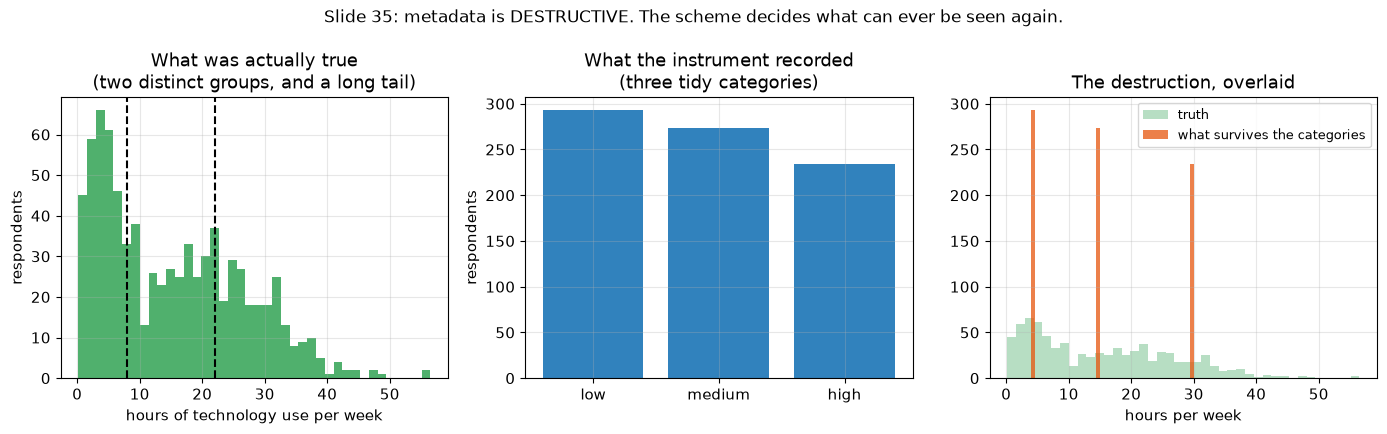

True mean hours     : 15.25
Reconstructed mean  : 15.36

But the real loss is not the mean -- it is that the TWO-GROUP structure is gone.
No amount of clever analysis recovers it. The category boundaries at 8 and 22 hours were
someone's judgement call, made once, and now permanent.


In [92]:
# Metadata is DESTRUCTIVE (slide 35): 'it sidelines some perspectives and reinforces others.'
# A classification scheme decides which distinctions are visible. Whatever it does not encode
# becomes invisible to every downstream analysis -- forever.

# Suppose the true underlying variable is a continuous 'hours of technology use per week'.
true_hours = np.concatenate([
    rng.gamma(2.0, 3.0, 400),          # light users
    rng.gamma(9.0, 2.6, 400),          # heavy users
])

# The survey instrument records only a 3-category variable ('low'/'medium'/'high').
def to_category(h):
    if h < 8:
        return "low"
    elif h < 22:
        return "medium"
    return "high"

recorded = pd.Series([to_category(h) for h in true_hours])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.4))

ax1.hist(true_hours, bins=40, color="#31a354", alpha=0.85)
for cut in (8, 22):
    ax1.axvline(cut, color="black", linestyle="--")
ax1.set_xlabel("hours of technology use per week")
ax1.set_ylabel("respondents")
ax1.set_title("What was actually true\n(two distinct groups, and a long tail)")

counts = recorded.value_counts().reindex(["low", "medium", "high"])
ax2.bar(counts.index, counts.values, color="#3182bd")
ax2.set_ylabel("respondents")
ax2.set_title("What the instrument recorded\n(three tidy categories)")

# What a downstream analyst can still see: only the bars. Reconstruct their best guess.
midpoints = {"low": 4, "medium": 15, "high": 30}
reconstructed = np.repeat([midpoints[c] for c in counts.index], counts.values)
ax3.hist(true_hours, bins=40, color="#31a354", alpha=0.35, label="truth")
ax3.hist(reconstructed, bins=40, color="#e6550d", alpha=0.75, label="what survives the categories")
ax3.set_xlabel("hours per week")
ax3.set_title("The destruction, overlaid")
ax3.legend(fontsize=9)

fig.suptitle("Slide 35: metadata is DESTRUCTIVE. The scheme decides what can ever be seen again.",
             fontsize=12)
plt.tight_layout()
plt.show()

print(f"True mean hours     : {true_hours.mean():.2f}")
print(f"Reconstructed mean  : {reconstructed.mean():.2f}")
print("\nBut the real loss is not the mean -- it is that the TWO-GROUP structure is gone.")
print("No amount of clever analysis recovers it. The category boundaries at 8 and 22 hours were")
print("someone's judgement call, made once, and now permanent.")


### 14.2 Metadata is triangulated — "startling revelations"

Slide 35's third word. Individually harmless datasets can identify people when **joined**. The
technical name for the columns that make this possible is **quasi-identifiers**: not names, not IDs,
just ordinary attributes — birth year, ZIP code, gender, job title — that in combination are nearly
unique.

The demonstration below is the classic one in the privacy literature, and it is worth running
slowly. Nothing here is a hack. It is two joins and a `groupby`.


In [93]:
# Two 'anonymised' datasets about the same 2,000 people.
# NEITHER contains a name. Both were released in good faith.

N_PEOPLE = 2000
zips = rng.choice([15213, 15217, 15232, 15206, 15201, 15222], N_PEOPLE,
                  p=[0.28, 0.22, 0.18, 0.14, 0.10, 0.08])
birth_years = rng.integers(1945, 2006, N_PEOPLE)
genders = rng.choice(["F", "M", "X"], N_PEOPLE, p=[0.49, 0.49, 0.02])

# Dataset A: a hospital's de-identified discharge file. No names. Has a diagnosis.
hospital = pd.DataFrame({
    "zip": zips,
    "birth_year": birth_years,
    "gender": genders,
    "diagnosis": rng.choice(["asthma", "fracture", "diabetes", "depression", "influenza"],
                            N_PEOPLE, p=[0.20, 0.22, 0.18, 0.15, 0.25]),
})

# Dataset B: a public voter roll. Has NAMES, and the same three ordinary attributes.
first = ["Alex", "Bina", "Chen", "Dara", "Ekow", "Fiona", "Gita", "Hugo", "Iris", "Jamal"]
last  = ["Alvarez", "Baptiste", "Cho", "Duarte", "Egan", "Farouk", "Gupta", "Haas", "Ibarra", "Jung"]
voters = pd.DataFrame({
    "name": [f"{rng.choice(first)} {rng.choice(last)}" for _ in range(N_PEOPLE)],
    "zip": zips,
    "birth_year": birth_years,
    "gender": genders,
})

print("Dataset A (hospital, de-identified) -- first 5 rows:")
print(hospital.head().to_string(index=False))
print("\nDataset B (public voter roll) -- first 5 rows:")
print(voters.head().to_string(index=False))
print("\nNeither file is obviously sensitive on its own. Now watch.")


Dataset A (hospital, de-identified) -- first 5 rows:
  zip  birth_year gender diagnosis
15213        1998      F  fracture
15213        1964      F  diabetes
15213        1978      F  fracture
15222        1946      F influenza
15222        1973      F influenza

Dataset B (public voter roll) -- first 5 rows:
        name   zip  birth_year gender
   Alex Jung 15213        1998      F
    Alex Cho 15213        1964      F
  Chen Gupta 15213        1978      F
Iris Alvarez 15222        1946      F
Alex Alvarez 15222        1973      F

Neither file is obviously sensitive on its own. Now watch.


Distinct combinations of (zip, birth year, gender): 685
Combinations shared by exactly ONE person          : 169
People who are therefore uniquely identifiable     : 169 (8.5% of the file)


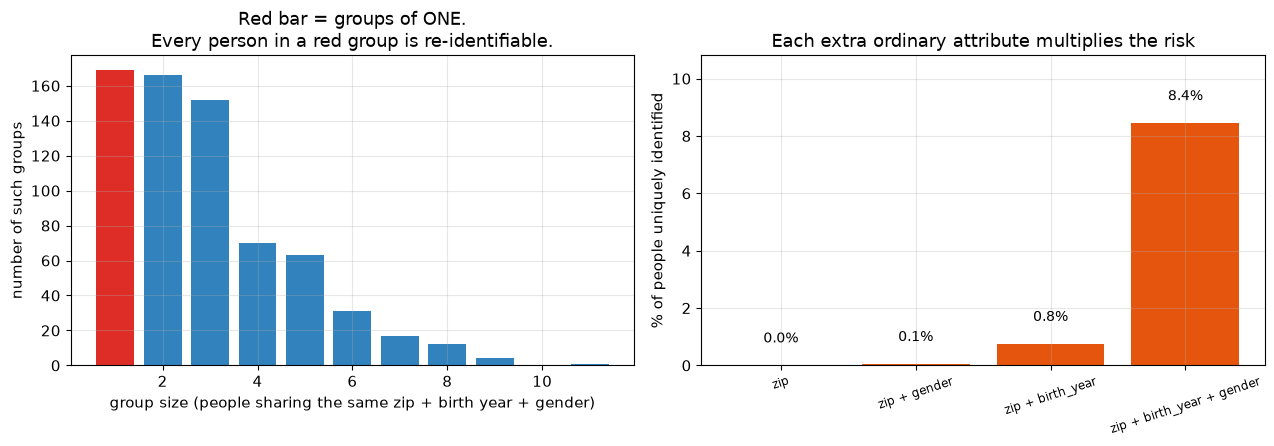

In [94]:
# How many people share each combination of the three quasi-identifiers?
# A group of size 1 means that combination identifies exactly ONE person.

QUASI = ["zip", "birth_year", "gender"]
group_sizes = hospital.groupby(QUASI).size()

unique_groups = (group_sizes == 1).sum()
people_alone = group_sizes[group_sizes == 1].sum()

print(f"Distinct combinations of (zip, birth year, gender): {len(group_sizes):,}")
print(f"Combinations shared by exactly ONE person          : {unique_groups:,}")
print(f"People who are therefore uniquely identifiable     : {people_alone:,} "
      f"({people_alone/len(hospital):.1%} of the file)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

size_counts = group_sizes.value_counts().sort_index()
bar_colours = ["#de2d26" if s == 1 else "#3182bd" for s in size_counts.index]
ax1.bar(size_counts.index, size_counts.values, color=bar_colours)
ax1.set_xlabel("group size (people sharing the same zip + birth year + gender)")
ax1.set_ylabel("number of such groups")
ax1.set_title("Red bar = groups of ONE.\nEvery person in a red group is re-identifiable.")

# How does re-identifiability change as we add quasi-identifiers one at a time?
combos = [["zip"], ["zip", "gender"], ["zip", "birth_year"], ["zip", "birth_year", "gender"]]
shares = []
for combo in combos:
    sizes = hospital.groupby(combo).size()
    unique_people = sizes[sizes == 1].sum()
    shares.append(100 * unique_people / len(hospital))

ax2.bar([" + ".join(c) for c in combos], shares, color="#e6550d")
for i, s in enumerate(shares):
    ax2.text(i, s + 0.8, f"{s:.1f}%", ha="center", fontsize=10)
ax2.set_ylabel("% of people uniquely identified")
ax2.set_ylim(0, max(shares) * 1.28)          # headroom so the labels clear the title
ax2.set_title("Each extra ordinary attribute multiplies the risk")
ax2.tick_params(axis="x", rotation=18, labelsize=8.5)

plt.tight_layout()
plt.show()


In [95]:
# The join itself. This is the whole 'attack': one line of pandas.

linked = hospital.merge(voters, on=QUASI, how="inner")

# Keep only the rows where the combination was unique in BOTH files -- a confident match.
combo_counts_h = hospital.groupby(QUASI).size().rename("n_hospital")
combo_counts_v = voters.groupby(QUASI).size().rename("n_voters")
linked = linked.merge(combo_counts_h, on=QUASI).merge(combo_counts_v, on=QUASI)
confident = linked[(linked["n_hospital"] == 1) & (linked["n_voters"] == 1)]

print(f"Rows produced by the join           : {len(linked):,}")
print(f"Confident one-to-one identifications: {len(confident):,}")
print("\nA sample of what the join now reveals -- names attached to diagnoses:")
print(confident[["name", "zip", "birth_year", "gender", "diagnosis"]].head(8).to_string(index=False))

print("\n" + "=" * 78)
print("Slide 35's phrase was 'startling revelations'. This is what it looks like in code.")
print("Neither dataset contained a name and a diagnosis together. The JOIN created that fact.")
print("This is why 'we removed the names' is not a privacy guarantee, and why the metadata")
print("describing a release matters as much as the release.")
print("=" * 78)


Rows produced by the join           : 8,058
Confident one-to-one identifications: 169

A sample of what the join now reveals -- names attached to diagnoses:
         name   zip  birth_year gender  diagnosis
 Alex Alvarez 15222        1973      F  influenza
    Alex Jung 15201        1983      F   fracture
 Fiona Farouk 15232        1945      X depression
  Chen Ibarra 15206        1950      F     asthma
  Chen Duarte 15201        2001      M  influenza
Ekow Baptiste 15213        1991      X  influenza
   Jamal Egan 15232        1968      M     asthma
   Jamal Egan 15222        1963      M  influenza

Slide 35's phrase was 'startling revelations'. This is what it looks like in code.
Neither dataset contained a name and a diagnosis together. The JOIN created that fact.
This is why 'we removed the names' is not a privacy guarantee, and why the metadata
describing a release matters as much as the release.


release version                    k   % uniquely identifiable
original (zip, year, gender)       1                      8.4%
generalised to decade              1                      0.9%
gender suppressed                  1                      0.8%
decade + gender suppressed        11                      0.0%


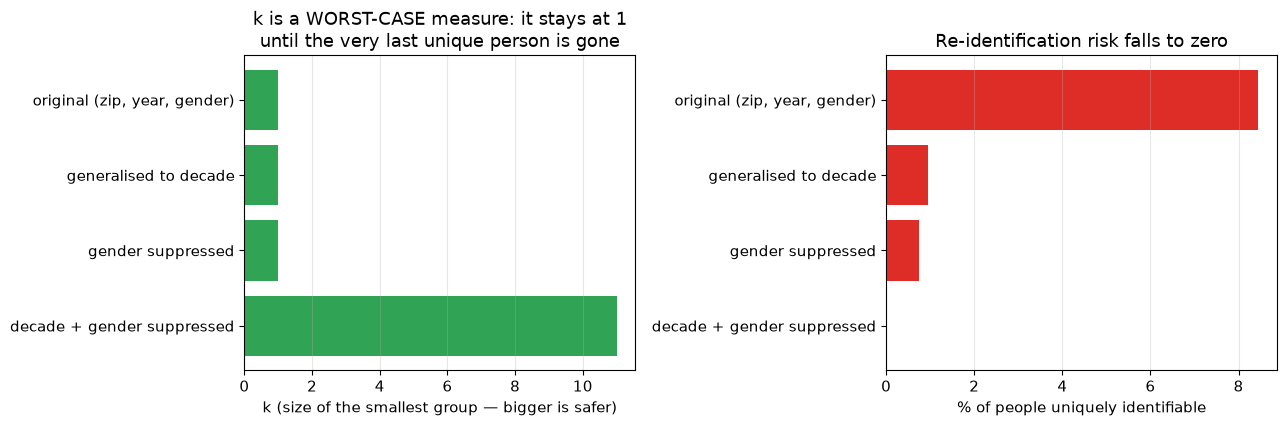


Read the two columns together -- they measure different things:
  * the PERCENTAGE is an average: it falls quickly, and looks like good progress.
  * k is a worst case: it stays stuck at 1 while even ONE person remains unique.
  Regulators and review boards generally care about k. Dashboards usually show the
  percentage. That gap is worth remembering.

The cost, which is never free: the last version cannot answer any question about gender,
and can no longer study single birth cohorts. Privacy and analytic value trade off directly.
Recall slide 6: 'Release data even if it's imperfect.' This is where that gets complicated.


In [96]:
# The standard defences, and their cost. This is the real trade-off in data publishing.

def k_anonymity(df, quasi):
    # k = the size of the SMALLEST group. k=1 means someone is unique. Higher k = safer.
    return int(df.groupby(quasi).size().min())

# Defence 1: generalise. Report a birth DECADE instead of a birth year.
generalised = hospital.copy()
generalised["birth_decade"] = (generalised["birth_year"] // 10) * 10

# Defence 2: suppress. Drop the gender column entirely.
suppressed = hospital.drop(columns=["gender"])

variants = {
    "original (zip, year, gender)": (hospital, QUASI),
    "generalised to decade":        (generalised, ["zip", "birth_decade", "gender"]),
    "gender suppressed":            (suppressed, ["zip", "birth_year"]),
    "decade + gender suppressed":   (generalised, ["zip", "birth_decade"]),
}

print(f"{'release version':<32}{'k':>4}{'% uniquely identifiable':>26}")
ks, pcts, names = [], [], []
for label, (df, quasi) in variants.items():
    sizes = df.groupby(quasi).size()
    k = int(sizes.min())
    pct = 100 * sizes[sizes == 1].sum() / len(df)
    print(f"{label:<32}{k:>4}{pct:>25.1f}%")
    names.append(label); ks.append(k); pcts.append(pct)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
ax1.barh(names, ks, color="#31a354")
ax1.set_xlabel("k (size of the smallest group — bigger is safer)")
ax1.set_title("k is a WORST-CASE measure: it stays at 1\nuntil the very last unique person is gone")
ax1.invert_yaxis(); ax1.grid(axis="y", visible=False)
ax2.barh(names, pcts, color="#de2d26")
ax2.set_xlabel("% of people uniquely identifiable")
ax2.set_title("Re-identification risk falls to zero")
ax2.invert_yaxis(); ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("\nRead the two columns together -- they measure different things:")
print("  * the PERCENTAGE is an average: it falls quickly, and looks like good progress.")
print("  * k is a worst case: it stays stuck at 1 while even ONE person remains unique.")
print("  Regulators and review boards generally care about k. Dashboards usually show the")
print("  percentage. That gap is worth remembering.")
print("\nThe cost, which is never free: the last version cannot answer any question about gender,")
print("and can no longer study single birth cohorts. Privacy and analytic value trade off directly.")
print("Recall slide 6: 'Release data even if it's imperfect.' This is where that gets complicated.")


> ### Summary of Section 14
> - Metadata answers slide 34's four questions: provenance, classification, contents, permitted use.
>   The practical form is a **data dictionary**, and writing one is the highest-value hour you will
>   spend on any dataset.
> - **Generative**: profiling data creates new data, which can be profiled in turn. Ad infinitum.
> - **Destructive**: the classification scheme decides what is knowable forever. Coarse categories
>   erase real structure permanently.
> - **Triangulated**: harmless datasets become identifying when joined on quasi-identifiers. "We
>   removed the names" is not anonymisation.


---
---

# Section 15 — Tokenization (the other meaning)

**Slides 36 and 37.** Careful: this is a *different* sense of the word from Section 11. In text
analysis, tokenization means chopping a sentence into words. Here, following McKinsey's 2024
explainer as the slide cites it, tokenization means:

> A digital — often unique — representation of a real, physical object.

Slide 36 adds that it is common to **Generative AI, Web 3, and Fintech**, that it *allows
transactions and creates new kinds of "data,"* and gives the example of *"records on jet fuel."*

Slide 37's balance sheet:

| The Good | The Bad |
|---|---|
| In Fintech — for cybersecurity | In *The Secret Life of Data*, we don't know |

And the key sentence: *anything can be represented digitally — and uniquely (think of an
**Advertising ID**).* That parenthesis is the whole problem, and we can demonstrate it precisely.


In [97]:
# THE GOOD: tokenizing a payment card. The merchant never stores the real number.
# We use a cryptographic hash function -- a one-way scrambler. Same input, same output, always;
# but you cannot run it backwards.

import hashlib

def make_token(secret_value, salt="pitt-infsci-0702-demo-salt"):
    # The 'salt' is a secret string mixed in. Without it, the hash is guessable (shown below).
    material = (salt + str(secret_value)).encode("utf-8")
    return hashlib.sha256(material).hexdigest()[:16]     # first 16 hex characters is plenty here

card_numbers = ["4111111111111111", "5500005555555559", "340000000000009"]

print(f"{'real value (never stored)':<26}{'token (safe to store)':<20}")
for card in card_numbers:
    print(f"{card:<26}{make_token(card):<20}")

print("\nTwo properties that make this useful:")
print("   1. DETERMINISTIC: the same card always gives the same token.")
print(f"      make_token('4111111111111111') twice -> {make_token(card_numbers[0])} "
      f"and {make_token(card_numbers[0])}")
print("   2. IRREVERSIBLE: a thief who steals the token table gets nothing spendable.")
print("\nThis is the 'Good' column of slide 37: a breach of the token store is not a breach of the cards.")


real value (never stored) token (safe to store)
4111111111111111          e27889fd1e80500c    
5500005555555559          7c2a80ea61407fb6    
340000000000009           5efe51c3f392f297    

Two properties that make this useful:
   1. DETERMINISTIC: the same card always gives the same token.
      make_token('4111111111111111') twice -> e27889fd1e80500c and e27889fd1e80500c
   2. IRREVERSIBLE: a thief who steals the token table gets nothing spendable.

This is the 'Good' column of slide 37: a breach of the token store is not a breach of the cards.


In [98]:
# ... but property 1 is ALSO the danger, and that is slide 37's 'Bad' column.
# A token that is stable across contexts is a perfect key for joining datasets --
# which is exactly the triangulation problem from Section 14, now industrialised.

AD_ID = "8f3c-77ba-41de-9902"                 # one device's advertising identifier
device_token = make_token(AD_ID)

# Three separate companies, three separate datasets, no names anywhere.
weather_app = pd.DataFrame({
    "token": [device_token] * 3,
    "timestamp": ["2026-03-02 07:14", "2026-03-02 12:40", "2026-03-02 19:02"],
    "coarse_location": ["15213", "15232", "15213"],
})
fitness_app = pd.DataFrame({
    "token": [device_token] * 2,
    "timestamp": ["2026-03-02 06:40", "2026-03-02 21:15"],
    "metric": ["sleep 5h20m", "steps 11,204"],
})
news_app = pd.DataFrame({
    "token": [device_token] * 3,
    "timestamp": ["2026-03-02 07:20", "2026-03-02 13:05", "2026-03-02 22:40"],
    "article_topic": ["local budget", "bankruptcy advice", "clinical trials"],
})

print("Three datasets, three companies, no name in any of them.")
print("Each one, on its own, is unremarkable. Now join them on the token:\n")

combined = pd.concat([
    weather_app.assign(source="weather app", detail=weather_app["coarse_location"])[["token", "timestamp", "source", "detail"]],
    fitness_app.assign(source="fitness app", detail=fitness_app["metric"])[["token", "timestamp", "source", "detail"]],
    news_app.assign(source="news app", detail=news_app["article_topic"])[["token", "timestamp", "source", "detail"]],
]).sort_values("timestamp")

print(combined.to_string(index=False))
print("\nThe join produced a narrative that no single company held: where this person slept, how")
print("badly, what they read about money and health, and where they went in between.")
print("The token was never a name. It did not need to be.")


Three datasets, three companies, no name in any of them.
Each one, on its own, is unremarkable. Now join them on the token:

           token        timestamp      source            detail
15bd4882be858476 2026-03-02 06:40 fitness app       sleep 5h20m
15bd4882be858476 2026-03-02 07:14 weather app             15213
15bd4882be858476 2026-03-02 07:20    news app      local budget
15bd4882be858476 2026-03-02 12:40 weather app             15232
15bd4882be858476 2026-03-02 13:05    news app bankruptcy advice
15bd4882be858476 2026-03-02 19:02 weather app             15213
15bd4882be858476 2026-03-02 21:15 fitness app      steps 11,204
15bd4882be858476 2026-03-02 22:40    news app   clinical trials

The join produced a narrative that no single company held: where this person slept, how
badly, what they read about money and health, and where they went in between.
The token was never a name. It did not need to be.


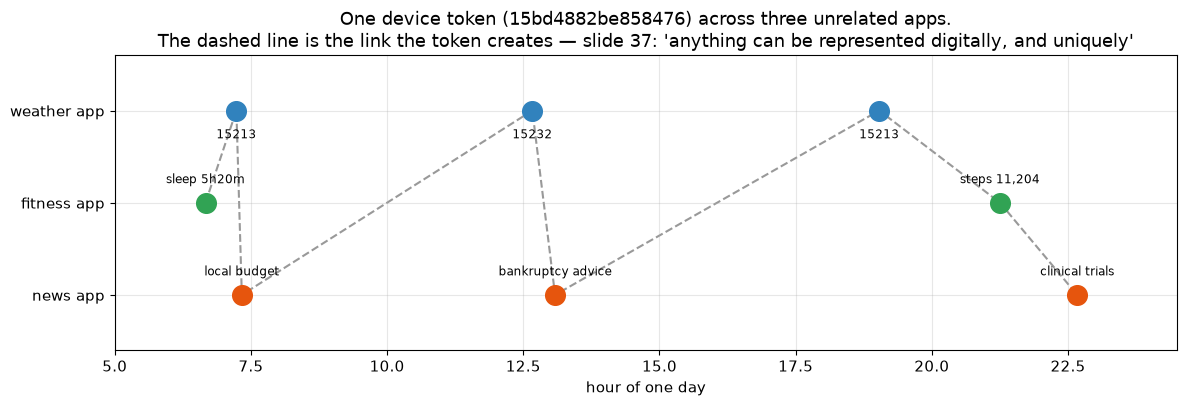

In [99]:
# Visualise why a stable token is so powerful: it stitches fragments into a timeline.

fig, ax = plt.subplots(figsize=(12, 4.2))

source_rows = {"weather app": 2, "fitness app": 1, "news app": 0}
source_colours = {"weather app": "#3182bd", "fitness app": "#31a354", "news app": "#e6550d"}

for _, row in combined.iterrows():
    hour = int(row["timestamp"][11:13]) + int(row["timestamp"][14:16]) / 60
    y = source_rows[row["source"]]
    ax.scatter([hour], [y], s=200, color=source_colours[row["source"]], zorder=3)
    # Labels on the top row go BELOW their dot, so they cannot collide with the title.
    offset = (0, -20) if y == max(source_rows.values()) else (0, 14)
    ax.annotate(row["detail"], (hour, y), textcoords="offset points", xytext=offset,
                ha="center", fontsize=8.5)

# The joining line: what the token makes possible.
hours = [int(t[11:13]) + int(t[14:16]) / 60 for t in combined["timestamp"]]
ys = [source_rows[s] for s in combined["source"]]
ax.plot(hours, ys, color="#999999", linestyle="--", linewidth=1.5, zorder=1)

ax.set_yticks(list(source_rows.values()))
ax.set_yticklabels(list(source_rows.keys()))
ax.set_xlim(5, 24.5)
ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("hour of one day")
ax.set_title(f"One device token ({device_token}) across three unrelated apps.\n"
             "The dashed line is the link the token creates — slide 37: "
             "'anything can be represented digitally, and uniquely'")
plt.tight_layout()
plt.show()


In [100]:
# A crucial caveat about hashing that trips up real organisations:
# hashing a value from a SMALL, PREDICTABLE set is not protection at all.
# Anyone can hash every possible value and build a lookup table. This is a 'dictionary attack'.

# Suppose someone 'protects' ZIP codes by hashing them without a salt.
def naive_hash(value):
    return hashlib.sha256(str(value).encode("utf-8")).hexdigest()[:16]

protected = pd.DataFrame({"hashed_zip": [naive_hash(z) for z in [15213, 15232, 15206]]})
print("A released file with 'protected' ZIP codes:")
print(protected.to_string(index=False))

# The attack: there are only about 41,000 US ZIP codes. Hash them all.
print("\nBuilding a lookup table over all 5-digit codes 15000-15999 (1,000 guesses)...")
rainbow = {naive_hash(z): z for z in range(15000, 16000)}
recovered = [rainbow.get(h, "not found") for h in protected["hashed_zip"]]
print("Recovered values:", recovered)
print("\nTime taken: milliseconds. The 'protection' was decorative.")
print("\nThe defences: a secret SALT (as in make_token above), or a keyed hash (HMAC), or simply")
print("not releasing the field. Hashing is not encryption and it is not anonymisation.")


A released file with 'protected' ZIP codes:
      hashed_zip
b23f6438ca7d54a4
60eeb12bcfcc234c
a428b5346f1d4261

Building a lookup table over all 5-digit codes 15000-15999 (1,000 guesses)...
Recovered values: [15213, 15232, 15206]

Time taken: milliseconds. The 'protection' was decorative.

The defences: a secret SALT (as in make_token above), or a keyed hash (HMAC), or simply
not releasing the field. Hashing is not encryption and it is not anonymisation.


Two lessons from Section 15 that generalise well beyond fintech:

1. **A token's usefulness and its danger are the same property.** Stability across contexts is what
   makes it work as a payment surrogate, and what makes it work as a surveillance key.
2. **Tokenization creates new data** (slide 36's phrase). Before tokenization, "this device read an
   article about bankruptcy advice" was not a record anywhere. The token brought it into existence —
   and the record outlives the transaction it was created for.

The slide's *"records on jet fuel"* example is the benign version: a token representing a physical
batch of fuel lets it be traded, tracked, and audited without moving the barrel. Same mechanism,
different stakes.

---
---

# Section 16 — Beyond tokenization: sensing human activity at fine scales

**Slides 38 and 39.** The lecture's last substantive move: once anything can be represented
digitally, human activity gets *sensed* — IoT, biometrics, sleep rhythms, calorific intake, steps
walked, clicking habits, driving behaviour.

Two examples from the slides, both from the *Wall Street Journal*:

- **Slide 38:** an ethnographer swept the rooms of a household ("Family 11") every 10 minutes and
  found **68% of time spent in the kitchen** (WSJ, July 6, 2012).
- **Slide 39:** Kindle reading data for *The Hunger Games* (WSJ, June 29, 2012): about **57 pages per
  hour** read on average; **0 seconds** of delay before the next book in the series was downloaded;
  and **18,000 readers highlighted a single sentence**.

Let's reconstruct the *shape* of both datasets, so you can see what fine-grained sensing produces.


In [101]:
# SLIDE 38: reconstruct an ethnographic sweep. One observation every 10 minutes for 16 waking hours.

SWEEP_MINUTES = 10
start_hour, end_hour = 7, 23
n_sweeps = (end_hour - start_hour) * 60 // SWEEP_MINUTES

rooms = ["kitchen", "living room", "bedroom", "porch", "elsewhere"]
room_probability = [0.68, 0.16, 0.09, 0.04, 0.03]     # matched to the slide's 68% headline

# Its own seeded generator, so this section's numbers do not shift when you edit cells above.
sensor_rng = np.random.default_rng(18)

observations = pd.DataFrame({
    "sweep": range(n_sweeps),
    "minutes_from_start": [i * SWEEP_MINUTES for i in range(n_sweeps)],
    "room": sensor_rng.choice(rooms, n_sweeps, p=room_probability),
})
observations["clock"] = observations["minutes_from_start"].apply(
    lambda m: f"{start_hour + m // 60:02d}:{m % 60:02d}")

print(f"{n_sweeps} sweeps, one every {SWEEP_MINUTES} minutes, from "
      f"{start_hour}:00 to {end_hour}:00.")
print("\nFirst 10 observations -- this is what 'fine-grained sensing' actually looks like as data:")
print(observations.head(10)[["sweep", "clock", "room"]].to_string(index=False))

share = observations["room"].value_counts(normalize=True)
print("\nShare of observed time by room:")
for room, s in share.items():
    print(f"   {room:<14} {s:>6.1%}   ({int(s*n_sweeps)} sweeps = about "
          f"{s*n_sweeps*SWEEP_MINUTES/60:.1f} hours)")

print(f"\nWe BUILT this household to be in the kitchen 68.0% of the time, and the sweeps")
print(f"recorded {share['kitchen']:.1%}. Even when the instrument is unbiased, {n_sweeps}")
print("observations only pin a percentage down to within a few points. Change the seed in")
print("np.random.default_rng(18) above and re-run: the 'finding' moves by several percentage")
print("points every time. Section 2's lesson, arriving uninvited.")


96 sweeps, one every 10 minutes, from 7:00 to 23:00.

First 10 observations -- this is what 'fine-grained sensing' actually looks like as data:
 sweep clock        room
     0 07:00     kitchen
     1 07:10 living room
     2 07:20     kitchen
     3 07:30     kitchen
     4 07:40       porch
     5 07:50     kitchen
     6 08:00     kitchen
     7 08:10     kitchen
     8 08:20     kitchen
     9 08:30     kitchen

Share of observed time by room:
   kitchen         67.7%   (65 sweeps = about 10.8 hours)
   living room     17.7%   (17 sweeps = about 2.8 hours)
   bedroom          8.3%   (8 sweeps = about 1.3 hours)
   porch            5.2%   (5 sweeps = about 0.8 hours)
   elsewhere        1.0%   (1 sweeps = about 0.2 hours)

We BUILT this household to be in the kitchen 68.0% of the time, and the sweeps
recorded 67.7%. Even when the instrument is unbiased, 96
observations only pin a percentage down to within a few points. Change the seed in
np.random.default_rng(18) above and re-run: t

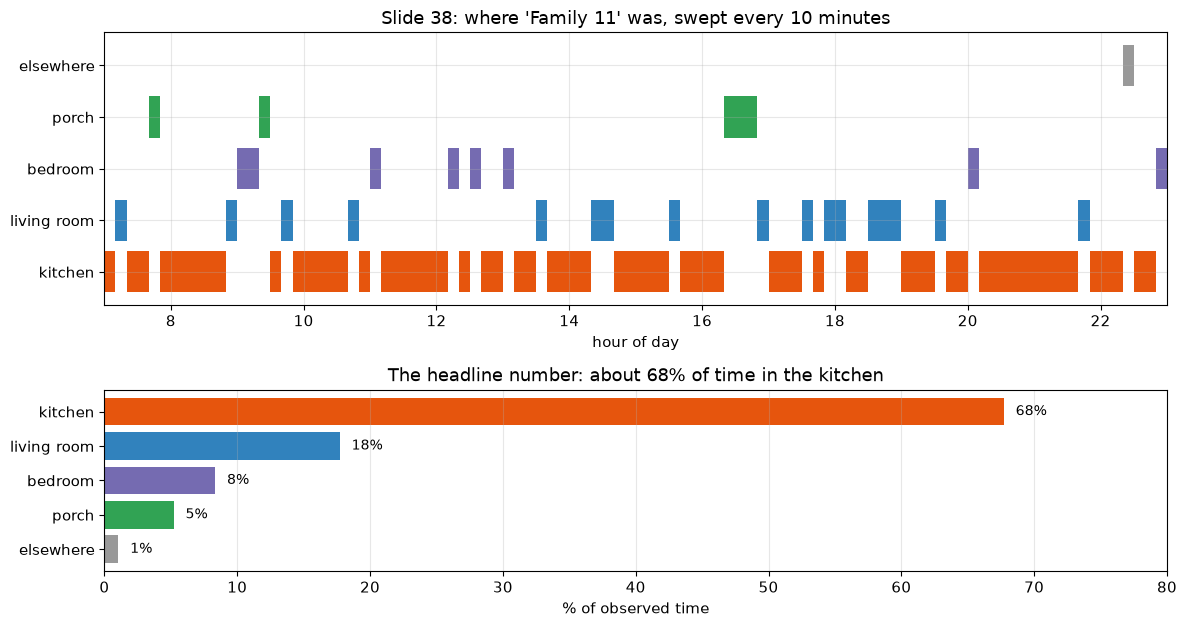

In [102]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.4),
                               gridspec_kw={"height_ratios": [1.5, 1]})

# Panel 1: the day as a timeline. broken_barh draws one horizontal bar per interval.
room_y = {r: i for i, r in enumerate(rooms)}
room_colour = dict(zip(rooms, ["#e6550d", "#3182bd", "#756bb1", "#31a354", "#999999"]))
for _, row in observations.iterrows():
    hour = start_hour + row["minutes_from_start"] / 60
    ax1.broken_barh([(hour, SWEEP_MINUTES / 60)], (room_y[row["room"]] - 0.4, 0.8),
                    facecolors=room_colour[row["room"]])
ax1.set_yticks(list(room_y.values()))
ax1.set_yticklabels(list(room_y.keys()))
ax1.set_xlim(start_hour, end_hour)
ax1.set_xlabel("hour of day")
ax1.set_title("Slide 38: where 'Family 11' was, swept every 10 minutes")

# Panel 2: the aggregate.
ordered = share.reindex(rooms)
ax2.barh(ordered.index, ordered.values * 100, color=[room_colour[r] for r in ordered.index])
for i, v in enumerate(ordered.values * 100):
    ax2.text(v + 0.9, i, f"{v:.0f}%", va="center", fontsize=10)
ax2.set_xlim(0, 80)                           # room for the value labels
ax2.set_xlabel("% of observed time")
ax2.set_title("The headline number: about 68% of time in the kitchen")
ax2.invert_yaxis()
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()


Minute-by-minute truth over 7 days: kitchen 67.6% of the time.

sweep every  1 min -> 6720 observations, kitchen 67.6%, room changes detected: 211
sweep every  5 min -> 1344 observations, kitchen 67.9%, room changes detected: 182
sweep every 10 min -> 672 observations, kitchen 68.5%, room changes detected: 149
sweep every 30 min -> 224 observations, kitchen 67.9%, room changes detected:  94
sweep every 60 min -> 112 observations, kitchen 70.5%, room changes detected:  54

TRUE number of room changes over the 7 days: 211


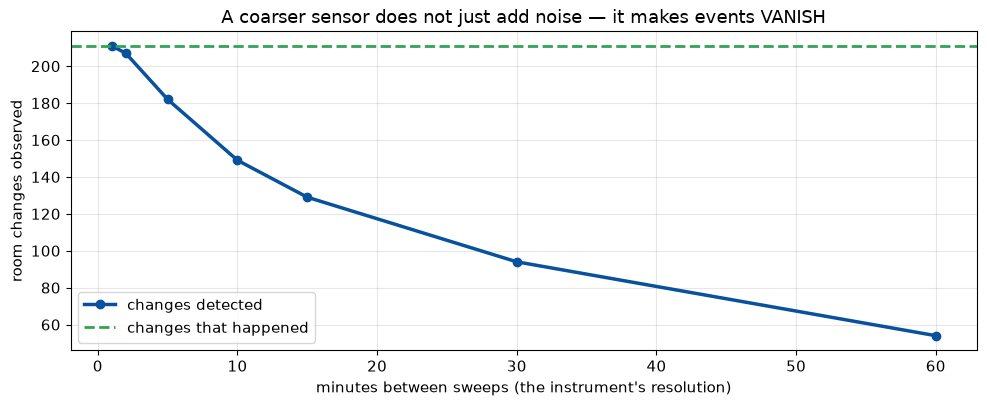


The kitchen SHARE survives coarse sampling reasonably well -- it is an average, and
averages are forgiving.
The BEHAVIOUR -- how restless the household is -- does not survive at all.
Averages are robust; dynamics are fragile. Choose your instrument for the question you have.


In [103]:
# The instrument question again (Section 2): what does a 10-minute sweep MISS?
# Simulate 'true' continuous presence, then sample it every 10 minutes and compare.

# We simulate SEVEN days rather than one, so the shares settle down and we are measuring the
# instrument rather than the luck of a single day.
DAYS = 7
MINUTES = (end_hour - start_hour) * 60 * DAYS
true_presence = []
current = "kitchen"
for minute in range(MINUTES):
    if sensor_rng.random() < 0.06:                   # on average a move every ~17 minutes
        current = sensor_rng.choice(rooms, p=room_probability)
    true_presence.append(current)
true_presence = pd.Series(true_presence)

print(f"Minute-by-minute truth over {DAYS} days: kitchen "
      f"{(true_presence == 'kitchen').mean():.1%} of the time.\n")

for interval in [1, 5, 10, 30, 60]:
    sampled = true_presence[::interval]
    kitchen_share = (sampled == "kitchen").mean()
    n_transitions = (sampled != sampled.shift()).sum() - 1
    print(f"sweep every {interval:>2} min -> {len(sampled):>3} observations, "
          f"kitchen {kitchen_share:>5.1%}, room changes detected: {n_transitions:>3}")

true_transitions = (true_presence != true_presence.shift()).sum() - 1
print(f"\nTRUE number of room changes over the {DAYS} days: {true_transitions}")

fig, ax = plt.subplots(figsize=(10, 4.2))
intervals = [1, 2, 5, 10, 15, 30, 60]
detected = [(true_presence[::i] != true_presence[::i].shift()).sum() - 1 for i in intervals]
ax.plot(intervals, detected, marker="o", color="#08519c", linewidth=2.5, label="changes detected")
ax.axhline(true_transitions, color="#31a354", linestyle="--", linewidth=2, label="changes that happened")
ax.set_xlabel("minutes between sweeps (the instrument's resolution)")
ax.set_ylabel("room changes observed")
ax.set_title("A coarser sensor does not just add noise — it makes events VANISH")
ax.legend()
plt.tight_layout()
plt.show()

print("\nThe kitchen SHARE survives coarse sampling reasonably well -- it is an average, and")
print("averages are forgiving.")
print("The BEHAVIOUR -- how restless the household is -- does not survive at all.")
print("Averages are robust; dynamics are fragile. Choose your instrument for the question you have.")


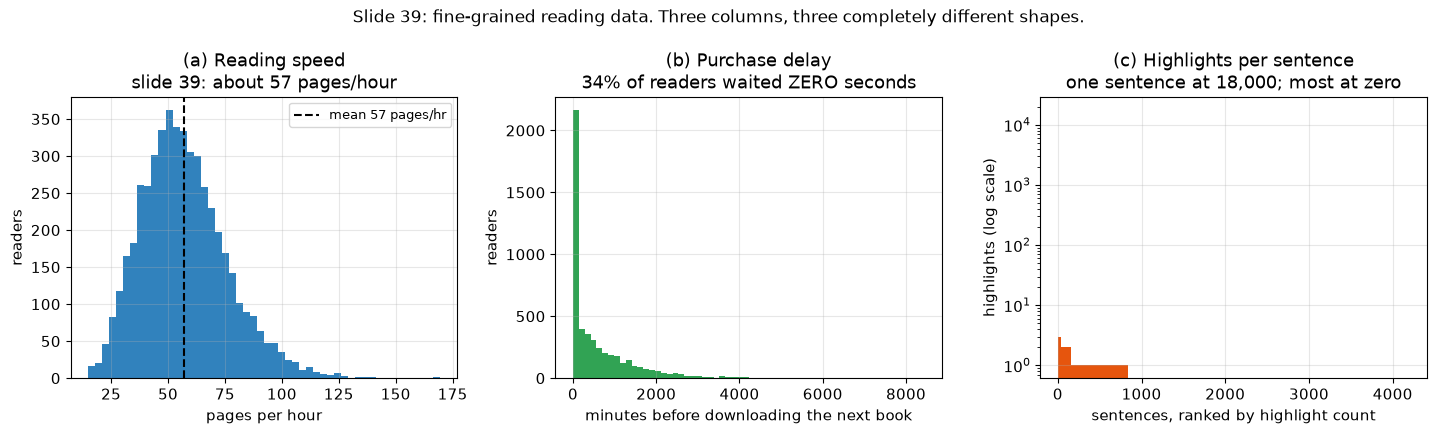

Highlights: 80.0% of sentences were never highlighted by anyone.
            the maximum was 18,000.
            mean 4.53, median 0.

A mean of a few and a maximum of 18,000 in the same column. If you report only the mean,
you have reported the least interesting fact in the dataset.


In [104]:
# SLIDE 39: the shape of Kindle reading data. Three very different distributions in one dataset.

N_READERS = 5000
kindle_rng = np.random.default_rng(42)

# (a) Reading speed: centred near the slide's 57 pages/hour, right-skewed.
pages_per_hour = kindle_rng.gamma(shape=9.0, scale=57/9.0, size=N_READERS)

# (b) Delay before downloading the next book in the series. The slide's striking figure is ZERO
#     seconds -- a large spike of readers who bought instantly, plus a long tail of everyone else.
instant = kindle_rng.random(N_READERS) < 0.34
delay_minutes = np.where(instant, 0.0, kindle_rng.exponential(scale=900, size=N_READERS))

# (c) Highlights per sentence across the book: almost all sentences get none, one gets 18,000.
n_sentences = 4200
highlights = kindle_rng.negative_binomial(1, 0.80, n_sentences).astype(float)
highlights[kindle_rng.integers(0, n_sentences)] = 18_000   # the famous single sentence

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

axes[0].hist(pages_per_hour, bins=50, color="#3182bd")
axes[0].axvline(pages_per_hour.mean(), color="black", linestyle="--",
                label=f"mean {pages_per_hour.mean():.0f} pages/hr")
axes[0].set_xlabel("pages per hour")
axes[0].set_ylabel("readers")
axes[0].set_title("(a) Reading speed\nslide 39: about 57 pages/hour")
axes[0].legend(fontsize=9)

axes[1].hist(delay_minutes, bins=60, color="#31a354")
axes[1].set_xlabel("minutes before downloading the next book")
axes[1].set_ylabel("readers")
axes[1].set_title(f"(b) Purchase delay\n{instant.mean():.0%} of readers waited ZERO seconds")

axes[2].bar(range(n_sentences), np.sort(highlights)[::-1], color="#e6550d", width=1.0)
axes[2].set_yscale("log")
axes[2].set_xlabel("sentences, ranked by highlight count")
axes[2].set_ylabel("highlights (log scale)")
axes[2].set_title("(c) Highlights per sentence\none sentence at 18,000; most at zero")

fig.suptitle("Slide 39: fine-grained reading data. Three columns, three completely different shapes.",
             fontsize=12)
plt.tight_layout()
plt.show()

print(f"Highlights: {(highlights == 0).mean():.1%} of sentences were never highlighted by anyone.")
print(f"            the maximum was {highlights.max():,.0f}.")
print(f"            mean {highlights.mean():.2f}, median {np.median(highlights):.0f}.")
print("\nA mean of a few and a maximum of 18,000 in the same column. If you report only the mean,")
print("you have reported the least interesting fact in the dataset.")


Notice what slide 39's three numbers are, as *types* of number in the sense of Section 4:

- **57 pages per hour** — a **rate** (the word "per" gives it away).
- **0 seconds** — a **duration**, and specifically a *point mass*: a huge pile of readers at exactly
  the same value. Averages handle point masses badly; the mean delay in panel (b) describes nobody.
- **18,000 readers** — a **count**, and an extreme **outlier**.

Three numbers, three types, three different appropriate summaries. That is the whole of Sections 3
and 4 applied to one WSJ story.

> ### Summary of Section 16
> - Fine-grained sensing produces long, timestamped, repetitive records — the raw "data" layer of
>   Section 1, at industrial scale.
> - Instrument resolution determines which *events* exist. Averages survive coarse sampling;
>   dynamics do not.
> - Sensed data are usually skewed, spiky, and outlier-driven. Look at the distribution before
>   reporting a mean.

---
---

# Section 17 — Recap: one pipeline, end to end

Everything in this notebook is one loop, and it is worth seeing in a single figure. We will take the
farmers-market data from Section 1 and walk it up the hierarchy one last time — but now naming the
hazard introduced at each step.


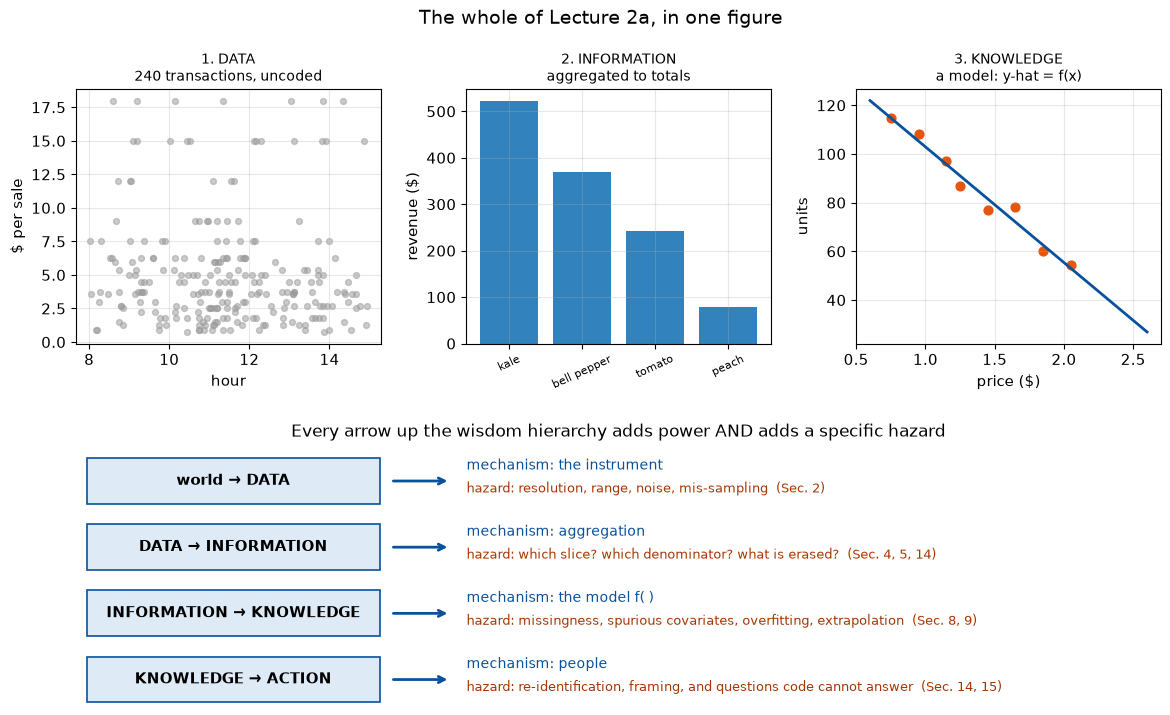

In [105]:
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.28)

# 1. RAW DATA
ax = fig.add_subplot(gs[0, 0])
ax.scatter(raw_log["hour"] + raw_log["minute"] / 60, raw_log["amount"],
           alpha=0.5, s=18, color="#999999")
ax.set_title("1. DATA\n240 transactions, uncoded", fontsize=10)
ax.set_xlabel("hour"); ax.set_ylabel("$ per sale")

# 2. INFORMATION
ax = fig.add_subplot(gs[0, 1])
ax.bar(by_item.index, by_item["revenue"], color="#3182bd")
ax.tick_params(axis="x", rotation=25, labelsize=8)
ax.set_title("2. INFORMATION\naggregated to totals", fontsize=10)
ax.set_ylabel("revenue ($)")

# 3. KNOWLEDGE
ax = fig.add_subplot(gs[0, 2])
ax.scatter(prices, units, s=40, color="#e6550d")
ax.plot(line_x, intercept + slope * line_x, color="#08519c", linewidth=2)
ax.set_title("3. KNOWLEDGE\na model: y-hat = f(x)", fontsize=10)
ax.set_xlabel("price ($)"); ax.set_ylabel("units")

# 4. The hazards at each step
ax = fig.add_subplot(gs[1, :])
ax.axis("off")
steps = [
    ("world → DATA", "the instrument", "resolution, range, noise, mis-sampling  (Sec. 2)"),
    ("DATA → INFORMATION", "aggregation", "which slice? which denominator? what is erased?  (Sec. 4, 5, 14)"),
    ("INFORMATION → KNOWLEDGE", "the model f( )", "missingness, spurious covariates, overfitting, extrapolation  (Sec. 8, 9)"),
    ("KNOWLEDGE → ACTION", "people", "re-identification, framing, and questions code cannot answer  (Sec. 14, 15)"),
]
for i, (transition, mechanism, hazard) in enumerate(steps):
    y = 0.88 - i * 0.26
    ax.add_patch(plt.Rectangle((0.01, y - 0.09), 0.27, 0.18, facecolor="#deebf7",
                               edgecolor="#08519c", linewidth=1.2))
    ax.text(0.145, y, transition, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.annotate("", xy=(0.345, y), xytext=(0.29, y),
                arrowprops=dict(arrowstyle="->", linewidth=2, color="#08519c"))
    ax.text(0.36, y + 0.045, f"mechanism: {mechanism}", fontsize=10, color="#08519c")
    ax.text(0.36, y - 0.045, f"hazard: {hazard}", fontsize=9.5, color="#a63603")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Every arrow up the wisdom hierarchy adds power AND adds a specific hazard",
             fontsize=12, pad=10)

fig.suptitle("The whole of Lecture 2a, in one figure", fontsize=14)
plt.show()


Slide 40 announces what comes next: **Data Problems & Precautions**, drawn from *The Secret Life of
Data*. You have now met, in code, most of the problems that lecture will name:

- imperfect instruments (Section 2)
- biased samples that more data cannot fix (Section 2)
- missing data with a mechanism (Section 9)
- too many covariates and the false findings they generate (Section 9)
- structure imposed a posteriori on records never meant to be data (Section 10)
- preprocessing choices that are silently theoretical (Section 11)
- classification schemes that destroy what they do not encode (Section 14)
- joins that reveal what neither dataset held (Sections 14, 15)

And slide 13's line is a fair summary of the antidote: *"Numbers are only fun if they make sense to
everyone."* Making them make sense — choosing the denominator, the scale, the slice, and the
translation — is not decoration on top of the analysis. It *is* the analysis.


---
---

# Section 18 — Glossary

Two glossaries follow. The first is a reference table, split into **concepts from the lecture** and
**Python/programming terms**. The second is the *same* content as a searchable Python dictionary, so
you can look terms up from a code cell.

## 18.1 Concepts from the lecture

| Term | Definition |
|---|---|
| **Adjacency matrix** | A square table of nodes × nodes; a 1 (or a weight) marks a tie. Same information as an edge list. |
| **Aggregation** | Combining many rows into summary values (sums, means, counts). The step from data to information. |
| **A posteriori structure** | Structure imposed on records *after* the fact, by an analyst. The records were created for another purpose (citations, tweets, receipts). |
| **A priori structure** | Structure decided *before* collection. A survey form, a database schema. |
| **Attribute** | A column of a table. Synonyms: feature, covariate, variable, characteristic. |
| **Binary (number base)** | Base 2. Digits are 0 and 1. Place values are powers of two. |
| **Bit** | One binary digit: 0 or 1. The smallest unit of information. |
| **Byte** | Eight bits. Can represent 2⁸ = 256 distinct values. |
| **Case** | A row of a table. Synonyms: sample, observation, record, respondent. |
| **Censoring / clipping** | An instrument's inability to record beyond a limit ("60+ minutes"), which flattens everything past that limit into one value. |
| **Computational social science (CSS)** | Studying social phenomena with large data and computational methods. Per slide 6: relies on data (information) *and* computation (knowledge?). |
| **Covariate** | A predictor variable; a column used as an input to a model. Slide 29's word for "potential explanatory column". |
| **Data** | The raw, uncoded record of the world. Discrete quantitative values extracted from a larger, more complex phenomenon. |
| **Data dictionary / codebook** | Metadata table describing each column of a dataset: meaning, units, source, permitted use. |
| **Degree** | The number of ties a node has in a network. |
| **Density (network)** | Actual edges divided by possible edges. |
| **Destructive (metadata)** | Slide 35: a classification scheme sidelines some perspectives and reinforces others; what it does not encode becomes permanently invisible. |
| **DIKW / wisdom hierarchy** | Data → Information → Knowledge → Wisdom. Each layer builds on the one below and loses detail. |
| **Dimensionality reduction** | Replacing many correlated columns with a few summary columns (e.g. PCA). Slide 29's remedy for "hundreds of covariates". |
| **Edge / link / tie** | A connection between two nodes in a network. |
| **Estimate (ŷ)** | The value a model produces. Never the true `y`. Read the hat as "this is a guess". |
| **Estimation (mental)** | Deliberately approximating with round numbers to sense-check a result. Slide 19. |
| **Explanation vs. prediction** | Explanation reads a model's weights ("what is associated with what"); prediction runs the model forward. The best predictor is often the worst explainer. |
| **Exponential growth** | Growth by a constant *factor* per period. A straight line on a log axis. |
| **Feature** | A column used as a model input. Same as attribute/covariate/variable. |
| **Found data** | Text or records that existed anyway, repurposed for research: newspaper articles, letters, personal ads, autobiographies, speeches. Slide 25. |
| **Designed data** | Text or records created *for* research: open-ended survey answers, requested journals, interview transcripts. Slide 25. |
| **Generative (metadata)** | Slide 35: describing data creates more data, which can itself be described. Ad infinitum. |
| **Hexadecimal** | Base 16. Digits 0–9 then A–F. One hex digit = exactly 4 bits; two = one byte. |
| **Imputation** | Filling in missing values with estimates. **Multiple imputation** repeats the filling many times and combines results, propagating the uncertainty. |
| **Information** | Data placed in context and thereby given meaning. Slide 3's example: total sales. |
| **Instrument (measuring)** | Whatever produced the data: a survey question, a sensor, a scraper, a parser. Every instrument has limited resolution, limited range, and noise. |
| **Knowledge** | Actionable inferences drawn from information by interested parties — governments, marketers, researchers. In practice: models. |
| **k-anonymity** | A release has k-anonymity if every combination of quasi-identifiers is shared by at least k people. k = 1 means someone is uniquely identifiable. |
| **Log scale** | An axis where equal distances mean equal *ratios* (×10 per step). The only way to show kilo and zetta on one chart. |
| **MCAR / MAR / MNAR** | Missing Completely At Random (harmless); Missing At Random given observed columns (modellable); Missing Not At Random — missingness depends on the missing value itself (not fixable by statistics). |
| **Metadata** | Data about data. Answers: where did it come from, where does it belong in a classification, what does it contain, how may it be used. Slide 34. |
| **Mis-sampling** | Drawing a sample that does not represent the universe you wish to study. Not cured by more data. Slide 5. |
| **N-gram** | A run of *n* consecutive tokens. 1-gram = word, 2-gram = word pair. The unit behind the Google N-Gram Viewer. |
| **Node / vertex** | A thing in a network. |
| **Odds** | Favourable ÷ unfavourable. "2 to 1" = probability 2/3 ≈ 67%. Range 0 to ∞. |
| **Outlier** | A value far from the rest. May be an error or the most important observation in the dataset (see the 18,000-highlight sentence). |
| **Overfitting** | A model flexible enough to fit the noise in its training data, and therefore worse on new data. |
| **PCA (principal component analysis)** | Finds the directions of greatest variation and re-describes the data along them. A standard dimensionality-reduction tool. |
| **Percentage point vs. percent** | 4% → 5% is +1 percentage point *and* +25 percent. Different units; never mix them. |
| **Place value** | The value a digit carries because of its position: … 1/100, 1/10, 1, 10, 100 … |
| **Probability** | Favourable ÷ **all** outcomes. Range 0 to 1. Not the same as odds. |
| **Quasi-identifier** | An ordinary attribute (ZIP, birth year, gender, job title) that, combined with others, identifies individuals. |
| **Rate** | A quantity *per* another quantity: miles per hour, 10% per annum. The word "per" is the tell. |
| **Ratio** | An implicit comparison, meaningless without its whole: "2/3 of the park was consumed by flames". |
| **Regular expression (regex)** | A compact pattern language for finding and extracting structure in text. |
| **Residual** | Actual minus predicted. A *pattern* in the residuals means the model's shape is wrong. |
| **Resolution** | The finest distinction an instrument can record. A 15-minute survey bucket cannot see a 22-minute commute. |
| **Sample** | (1) A row of a table. (2) A subset drawn from a population. Context tells you which. |
| **Scientific notation** | Writing numbers as a coefficient times a power of ten: 2.5 × 10¹⁸, typed `2.5e18`. |
| **Semi-structured data** | Not tabular but partly structured: HTML pages, citations, JSON. Attributes vary from record to record. |
| **SI prefixes** | Standard multipliers in steps of 1,000: kilo (10³), mega (10⁶), giga (10⁹), tera (10¹²), peta, exa, zetta; and down: milli (10⁻³), micro (10⁻⁶), nano (10⁻⁹), pico, femto, atto, zepto. |
| **Sparsity** | Most possible values are absent. Characteristic of n-grams and of text data generally. |
| **Stop words** | Very common function words (`the`, `and`, `of`) often removed before topic analysis — and essential to *keep* for style or authorship analysis. |
| **Structured data** | Tabular data: rows are cases, columns are features. Often the *output* of processing semi- or unstructured data. |
| **Taxonomic data** | Hierarchical data where each item has one parent. A tree. The radio spectrum, occupational codes, census geography. |
| **Tokenization (text)** | Splitting text into countable units, usually words. |
| **Tokenization (fintech / Web3 / GenAI)** | A digital, often unique, representation of a real object — enabling transactions and creating new data. Slide 36. |
| **Triangulated (metadata)** | Slide 35: fused with other datasets, metadata yields startling revelations. The mechanism is a join on quasi-identifiers. |
| **Type–token ratio** | Distinct words ÷ total words. A crude measure of vocabulary variety. |
| **Unstructured data** | Video, audio, images, chat logs, slide decks, free text. No imposed structure. |
| **Wisdom** | The layer the lecture marks with a question mark. Judgement about whether and how knowledge should be used. Not computable. |
| **Zipf's law** | In natural language, word frequency is roughly inversely proportional to rank — a straight line on log-log axes. |

## 18.2 Python and programming terms used in this notebook

| Term | Meaning |
|---|---|
| **Argument** | A value you pass into a function: in `round(3.7)`, `3.7` is the argument. |
| **Array** (`np.array`) | A numpy list of numbers, fast to compute on element-by-element. |
| **Boolean** | `True` or `False`. |
| **Cell** | One block of a notebook: markdown (text) or code. |
| **Comment** | Text after `#`, ignored by Python. Notes for humans. |
| **DataFrame** (`pd.DataFrame`) | A pandas table: rows and columns with labels. |
| **Dictionary** (`dict`) | A `{key: value}` lookup, written with curly braces. |
| **Encoding (of a variable)** | Turning categories into numbers so a model can use them (`"high"` → `2`). |
| **f-string** | A string prefixed with `f` where `{variable}` is replaced by its value. |
| **Function** (`def`) | A named, reusable recipe that takes arguments and `return`s a result. |
| **Hash function** | A one-way scrambler: same input → same output, and practically impossible to reverse. `hashlib.sha256`. |
| **Import** | Loading a library: `import pandas as pd`. |
| **Index** | (1) A position in a list, starting at **0**. (2) The row labels of a DataFrame. |
| **Kernel** | The Python process running behind the notebook. Restarting it clears all variables. |
| **List** | An ordered sequence in square brackets: `[1, 2, 3]`. |
| **Loop** (`for`) | Repeating a block once per item in a collection. |
| **Mask** | A column of `True`/`False` used to select rows: `df[df["age"] > 30]`. |
| **NaN** | "Not a Number" — pandas' marker for a missing value. |
| **Recursion** | A function that calls itself; the natural way to walk a tree of unknown depth. |
| **Salt** | A secret string mixed into a hash so the output cannot be reversed by guessing inputs. |
| **Seed** | A number that makes "random" results reproducible: `np.random.default_rng(7)`. |
| **Series** (`pd.Series`) | A single labelled column. |
| **String** | Text, in quotes. |
| **Variable** | A name bound to a value with `=`. |


In [106]:
# The same glossary as a searchable dictionary. Run this cell, then use define("...") below.

GLOSSARY = {
    "adjacency matrix": "A square nodes-by-nodes table where a 1 marks a tie. Same information as an edge list.",
    "aggregation": "Combining many rows into summary values (sums, means, counts). The step from data to information.",
    "a posteriori structure": "Structure imposed on records after the fact by an analyst; the records existed for another purpose.",
    "a priori structure": "Structure decided before collection: a survey form, a database schema.",
    "attribute": "A column of a table. Synonyms: feature, covariate, variable, characteristic.",
    "binary": "Base 2. Digits 0 and 1; place values are powers of two.",
    "bit": "One binary digit, 0 or 1. The smallest unit of information.",
    "byte": "Eight bits; represents 2**8 = 256 distinct values.",
    "case": "A row of a table. Synonyms: sample, observation, record, respondent.",
    "censoring": "An instrument's inability to record beyond a limit, flattening everything past it into one value.",
    "computational social science": "Studying social phenomena with large data and computation. Slide 6: data (information) AND computation (knowledge?).",
    "covariate": "A predictor column used as a model input. Slide 29's term for a potential explanatory variable.",
    "data": "The raw, uncoded record of the world; discrete quantitative values extracted from a complex phenomenon.",
    "data dictionary": "Metadata describing each column: meaning, units, source, permitted use. Also called a codebook.",
    "degree": "The number of ties a node has in a network.",
    "designed data": "Text created for research: open-ended survey answers, requested journals, interview transcripts.",
    "destructive metadata": "Slide 35: a classification scheme sidelines some perspectives; what it omits becomes permanently invisible.",
    "dikw": "The wisdom hierarchy: Data, Information, Knowledge, Wisdom. Each layer builds on the one below and loses detail.",
    "dimensionality reduction": "Replacing many correlated columns with a few summary columns, e.g. PCA.",
    "edge": "A connection between two nodes in a network. Also called a link or a tie.",
    "estimate": "The value a model produces, written y-hat. Never the true y.",
    "estimation": "Approximating deliberately with round numbers to sense-check a result. Slide 19.",
    "explanation vs prediction": "Explanation reads a model's weights; prediction runs it forward. The best predictor is often the worst explainer.",
    "exponential growth": "Growth by a constant factor per period. A straight line on a log axis.",
    "feature": "A column used as a model input; same as attribute, covariate, variable.",
    "found data": "Records that existed anyway, repurposed for research: newspapers, letters, personal ads, speeches.",
    "generative metadata": "Slide 35: describing data creates more data, which can itself be described. Ad infinitum.",
    "hexadecimal": "Base 16 (0-9, A-F). One hex digit is exactly 4 bits; two digits are one byte.",
    "imputation": "Filling in missing values with estimates. Multiple imputation repeats the filling and combines results.",
    "information": "Data placed in context and given meaning. Slide 3's example: total sales.",
    "instrument": "Whatever produced the data. Every instrument has limited resolution, limited range, and noise.",
    "k-anonymity": "Every combination of quasi-identifiers is shared by at least k people. k=1 means someone is uniquely identifiable.",
    "knowledge": "Actionable inferences drawn from information by interested parties. In practice: models.",
    "log scale": "An axis where equal distances mean equal ratios. The only way to show kilo and zetta on one chart.",
    "mcar": "Missing Completely At Random: missingness unrelated to anything. The harmless case.",
    "mar": "Missing At Random: missingness depends on OBSERVED columns. Modellable.",
    "mnar": "Missing Not At Random: missingness depends on the missing value itself. Not fixable by statistics.",
    "metadata": "Data about data: provenance, classification, contents, permitted use. Slide 34.",
    "mis-sampling": "Drawing a sample that does not represent the universe you wish to study. Not cured by more data.",
    "n-gram": "A run of n consecutive tokens. 1-gram = word, 2-gram = word pair.",
    "node": "A thing in a network. Also called a vertex.",
    "odds": "Favourable divided by unfavourable. '2 to 1' means probability 2/3, about 67%. Range 0 to infinity.",
    "outlier": "A value far from the rest. Sometimes an error, sometimes the most important observation.",
    "overfitting": "A model flexible enough to fit noise, and therefore worse on new data.",
    "pca": "Principal component analysis: finds directions of greatest variation and re-describes data along them.",
    "percentage point": "The arithmetic difference between two percentages. 4% to 5% is +1 point and +25 percent.",
    "place value": "The value a digit carries because of its position: ...1/100, 1/10, 1, 10, 100...",
    "probability": "Favourable divided by ALL outcomes. Range 0 to 1. Not the same as odds.",
    "quasi-identifier": "An ordinary attribute (zip, birth year, gender) that combined with others identifies individuals.",
    "rate": "A quantity per another quantity. The word 'per' is the tell.",
    "ratio": "An implicit comparison, meaningless without stating its whole.",
    "regular expression": "A compact pattern language for finding and extracting structure in text.",
    "residual": "Actual minus predicted. A pattern in residuals means the model's shape is wrong.",
    "resolution": "The finest distinction an instrument can record.",
    "sample": "Either a row of a table, or a subset drawn from a population. Context decides.",
    "scientific notation": "Writing a number as a coefficient times a power of ten: 2.5e18 means 2.5 x 10**18.",
    "semi-structured data": "Not tabular but partly structured: HTML, citations, JSON. Attributes vary between records.",
    "si prefixes": "Multipliers in steps of 1000: kilo 10**3, mega 10**6, giga 10**9, tera 10**12, peta, exa, zetta; milli, micro, nano, pico, femto, atto, zepto going down.",
    "sparsity": "Most possible values are absent. Characteristic of n-grams and text data.",
    "stop words": "Very common function words, often removed for topic analysis and essential to keep for style analysis.",
    "structured data": "Tabular data: rows are cases, columns are features. Often the output of processing unstructured data.",
    "taxonomic data": "Hierarchical data where each item has one parent. A tree.",
    "tokenization (text)": "Splitting text into countable units, usually words.",
    "tokenization (fintech)": "A digital, often unique, representation of a real object, enabling transactions and creating new data. Slide 36.",
    "triangulated metadata": "Slide 35: fused with other datasets, metadata yields startling revelations. The mechanism is a join on quasi-identifiers.",
    "type-token ratio": "Distinct words divided by total words. A crude measure of vocabulary variety.",
    "unstructured data": "Video, audio, images, chat logs, slide decks, free text. No imposed structure.",
    "wisdom": "Judgement about whether and how knowledge should be used. The layer the lecture marks with a question mark.",
    "zipf's law": "Word frequency is roughly inversely proportional to rank; a straight line on log-log axes.",
    # Python terms
    "dataframe": "PYTHON: a pandas table with labelled rows and columns.",
    "dictionary": "PYTHON: a {key: value} lookup, written with curly braces.",
    "f-string": "PYTHON: a string prefixed with f, where {variable} is replaced by its value.",
    "hash function": "PYTHON: a one-way scrambler. Same input gives the same output; reversing it is impractical.",
    "index": "PYTHON: a position in a list (starting at 0), or the row labels of a DataFrame.",
    "kernel": "PYTHON: the process running the notebook. Restarting it clears every variable.",
    "mask": "PYTHON: a column of True/False used to select rows.",
    "nan": "PYTHON: 'Not a Number' - pandas' marker for a missing value.",
    "recursion": "PYTHON: a function that calls itself; the natural way to walk a tree.",
    "salt": "PYTHON: a secret string mixed into a hash so outputs cannot be reversed by guessing inputs.",
    "seed": "PYTHON: a number that makes random results reproducible.",
    "series": "PYTHON: a single labelled pandas column.",
}

print(f"Glossary loaded: {len(GLOSSARY)} terms.")


Glossary loaded: 81 terms.


In [107]:
# A lookup function with fuzzy matching, so near-misses and typos still work.

import difflib

def define(term):
    key = term.strip().lower()
    if key in GLOSSARY:
        print(f"{key.upper()}\n   {GLOSSARY[key]}")
        return
    # Substring search next.
    partial = [k for k in GLOSSARY if key in k]
    if partial:
        for k in partial:
            print(f"{k.upper()}\n   {GLOSSARY[k]}\n")
        return
    # Then fuzzy matching.
    close = difflib.get_close_matches(key, GLOSSARY.keys(), n=3, cutoff=0.55)
    if close:
        print(f"No exact entry for '{term}'. Did you mean:")
        for k in close:
            print(f"   - {k}")
    else:
        print(f"'{term}' is not in the glossary. Try define('') to list every term.")

def list_terms():
    for i, k in enumerate(sorted(GLOSSARY), start=1):
        print(f"{i:>3}. {k}")

# Examples -- edit these and re-run.
define("odds")
print()
define("mnar")
print()
define("tokenization")
print()
define("zipfs law")        # deliberate typo: fuzzy matching handles it


ODDS
   Favourable divided by unfavourable. '2 to 1' means probability 2/3, about 67%. Range 0 to infinity.

MNAR
   Missing Not At Random: missingness depends on the missing value itself. Not fixable by statistics.

TOKENIZATION (TEXT)
   Splitting text into countable units, usually words.

TOKENIZATION (FINTECH)
   A digital, often unique, representation of a real object, enabling transactions and creating new data. Slide 36.


No exact entry for 'zipfs law'. Did you mean:
   - zipf's law


In [108]:
# Uncomment the next line to print every term in the glossary.
# list_terms()

# Or look up anything you like:
define("quasi-identifier")


QUASI-IDENTIFIER
   An ordinary attribute (zip, birth year, gender) that combined with others identifies individuals.


---
---

# Section 19 — Exercises

Work through these in order; each one builds on a section above. Write your answer in the code cell
under each question. **Answers follow at the very end** — try before you peek.

If you get stuck, the pattern you need is almost always in the section the exercise names.

---

**Exercise 1 (Section 1).** Using `raw_log`, compute the total revenue *per hour of the day*, and
then the *average sale amount* per hour. Which hour had the highest average sale, and is that the
same as the busiest hour? *(Hint: `raw_log.groupby("hour")["amount"].sum()` and `.mean()`.)*

**Exercise 2 (Section 2).** Build a "phone survey" sample that over-represents people with commutes
*close to 30 minutes* and under-represents everyone else. Report its mean and compare with the truth.
*(Hint: build weights with `1 / (1 + abs(true_commute - 30))`, normalise them, and pass them as `p=`
to `rng.choice`.)*

**Exercise 3 (Section 3).** Write a function `time_to_spend(amount, per_day)` that returns a
readable string like `"27.4 years"` or `"10 days"`. Test it on \$1 million, \$1 billion, and \$1
trillion at \$100,000 per day, and check you reproduce slide 18.

**Exercise 4 (Section 3).** The lecture says 175 zettabytes were expected by 2025. Express that as
(a) bytes per person on Earth, (b) hours of HD video at 3 GB per hour, and (c) how many 1-terabyte
hard drives it would take. Use `humanise()` to print the results readably.

**Exercise 5 (Section 4).** A candidate is quoted at "odds of 7 to 2". Convert that to a
probability. Then plot probability against odds for odds from 0.1 to 20, and mark this candidate.

**Exercise 6 (Section 6).** Convert your birth year to binary and to hex. Then work out how many
bits you need to store *any* year from 0 to 2100, and check your answer with `bits_needed()`.

**Exercise 7 (Section 7).** Add a new feature to `survey` called `heavy_user`, defined as `"yes"`
when the respondent uses both Wi-Fi and Bluetooth, else `"no"`. Then compare the mean `Resp.` score
between heavy and non-heavy users, and draw a boxplot.

**Exercise 8 (Section 8).** Fit the model from Section 8 again, but *leave out* the `tech_score`
feature. Does the typical prediction error get better or worse? By how much? What does that tell you
about that feature?

**Exercise 9 (Section 9).** Take `survey_missing` and impute the missing `Resp.` values using the
group mean *by `UG?`* instead of by `Tech`. Is the resulting overall mean closer to the truth?

**Exercise 10 (Section 10).** Extend `parse_citation` to also extract a page range like
`"pp. 121-134"`. Test it on a citation you make up, and on one of the awkward examples.

**Exercise 11 (Section 11).** Compute the top ten *trigrams* in the corpus, and plot them. Then
remove stop words *before* building the trigrams and plot again. Which version is more informative,
and why?

**Exercise 12 (Section 12).** Add a fifth author, `"Pitt"`, connected to both `"Gkantsidis"` and
`"Kaemarungsi"`. Recompute the degrees and the density, and redraw the network.

**Exercise 13 (Section 13).** Add a `wavelength_m` column to `spectrum` using the physics formula
*wavelength = speed of light / frequency*, with the speed of light as `3e8` metres per second. Then
plot band against wavelength on a log axis. Which end of the taxonomy has the longest waves?

**Exercise 14 (Section 14).** Add `diagnosis` to the list of quasi-identifiers in the hospital file
and recompute the share of uniquely identifiable people. Explain in one sentence why adding a
*sensitive* column to the quasi-identifier set is a different kind of problem from adding an
ordinary one.

**Exercise 15 (Sections 14–16).** *No code required.* Slide 6 quotes Vivek Kundra: *"Release data
even if it's imperfect."* Write a paragraph arguing for that position, then a paragraph arguing
against it, using at least three specific findings from this notebook as evidence on each side.


In [109]:
# YOUR WORKSPACE. Add cells as you like (menu: Insert -> Insert Cell Below, or the + button).

# Exercise 1:


# Exercise 2:


# Exercise 3:


---

## Answers

Read these *after* attempting the exercises. Several have more than one right answer; if your code
gives the same numbers by a different route, you are fine.


In [110]:
# ANSWER 1
revenue_per_hour = raw_log.groupby("hour")["amount"].sum()
average_sale_per_hour = raw_log.groupby("hour")["amount"].mean()
count_per_hour = raw_log.groupby("hour")["amount"].count()

answer1 = pd.DataFrame({"revenue": revenue_per_hour.round(2),
                        "mean_sale": average_sale_per_hour.round(2),
                        "n_sales": count_per_hour})
print(answer1.to_string())
print(f"\nBusiest hour by number of sales : {count_per_hour.idxmax()}")
print(f"Highest revenue hour            : {revenue_per_hour.idxmax()}")
print(f"Highest AVERAGE sale hour       : {average_sale_per_hour.idxmax()}")
print("\nThe busiest hour and the biggest-basket hour need not agree -- a lot of small sales")
print("can out-earn a few large ones. This is the Section 5 lesson: which slice are you reporting?")


      revenue  mean_sale  n_sales
hour                             
8      113.05       5.14       22
9      192.15       5.82       33
10     204.95       5.00       41
11     280.55       4.76       59
12     142.45       4.75       30
13     193.40       5.23       37
14      84.30       4.68       18

Busiest hour by number of sales : 11
Highest revenue hour            : 11
Highest AVERAGE sale hour       : 9

The busiest hour and the biggest-basket hour need not agree -- a lot of small sales
can out-earn a few large ones. This is the Section 5 lesson: which slice are you reporting?


truth mean         : 30.39 minutes
phone-sample mean  : 28.08 minutes
bias               : -2.31 minutes
truth std dev      : 18.45
phone-sample sd    : 11.78   <- the SPREAD is badly understated too


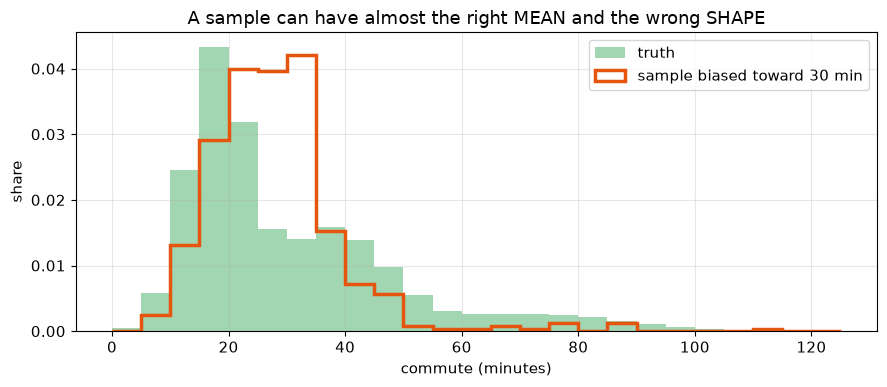

In [111]:
# ANSWER 2
w = 1 / (1 + np.abs(true_commute - 30))
w = w / w.sum()
phone_sample = true_commute[rng.choice(len(true_commute), size=500, p=w, replace=False)]

print(f"truth mean         : {true_commute.mean():.2f} minutes")
print(f"phone-sample mean  : {phone_sample.mean():.2f} minutes")
print(f"bias               : {phone_sample.mean() - true_commute.mean():+.2f} minutes")
print(f"truth std dev      : {true_commute.std():.2f}")
print(f"phone-sample sd    : {phone_sample.std():.2f}   <- the SPREAD is badly understated too")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(true_commute, bins=np.arange(0, 130, 5), density=True, color="#31a354", alpha=0.45,
        label="truth")
ax.hist(phone_sample, bins=np.arange(0, 130, 5), density=True, histtype="step", linewidth=2.5,
        color="#e6550d", label="sample biased toward 30 min")
ax.set_xlabel("commute (minutes)"); ax.set_ylabel("share")
ax.set_title("A sample can have almost the right MEAN and the wrong SHAPE")
ax.legend()
plt.tight_layout(); plt.show()


In [112]:
# ANSWER 3
def time_to_spend(amount, per_day=100_000):
    days = amount / per_day
    if days < 60:
        return f"{days:,.0f} days"
    if days < 730:
        return f"{days/30.44:,.1f} months"
    return f"{days/365.25:,.1f} years"

for label, amount in [("$1 million", 1e6), ("$1 billion", 1e9), ("$1 trillion", 1e12)]:
    print(f"{label:>12} at $100,000/day -> {time_to_spend(amount)}")
print("\nSlide 18 says 10 days and 27 years. Reproduced.")


  $1 million at $100,000/day -> 10 days
  $1 billion at $100,000/day -> 27.4 years
 $1 trillion at $100,000/day -> 27,378.5 years

Slide 18 says 10 days and 27 years. Reproduced.


In [113]:
# ANSWER 4
ZB_175 = 175e21
print(f"(a) per person on Earth : {humanise(ZB_175 / 8.1e9, 'B')}")
print(f"(b) hours of HD video   : {ZB_175 / 3e9:,.0f} hours = {ZB_175 / 3e9 / 8766:,.0f} years of continuous video")
print(f"(c) 1 TB hard drives    : {ZB_175 / 1e12:,.0f} drives")
print(f"    stacked at 2 cm each: {ZB_175 / 1e12 * 0.02 / 1000:,.0f} km tall")


(a) per person on Earth : 21.60 TB
(b) hours of HD video   : 58,333,333,333,333 hours = 6,654,498,441 years of continuous video
(c) 1 TB hard drives    : 175,000,000,000 drives
    stacked at 2 cm each: 3,500,000 km tall


Odds of 7 to 2 -> odds value 3.5  ->  probability 77.8%


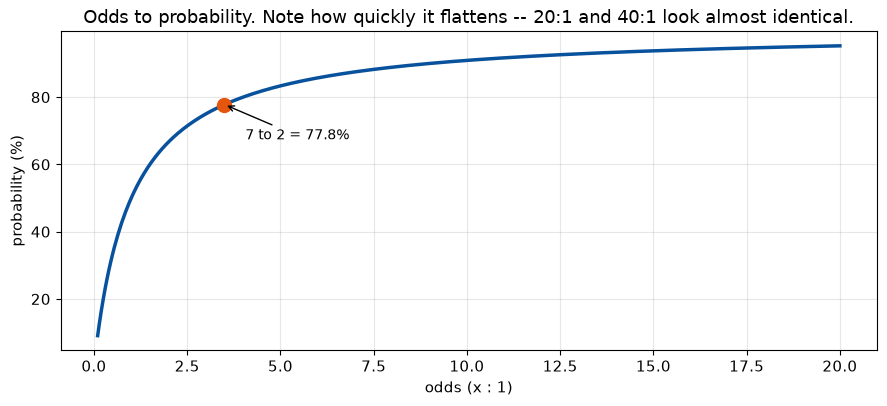

In [114]:
# ANSWER 5
odds_72 = 7 / 2
p_72 = odds_to_prob(odds_72)
print(f"Odds of 7 to 2 -> odds value {odds_72}  ->  probability {p_72:.1%}")

odds_grid = np.linspace(0.1, 20, 400)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(odds_grid, odds_to_prob(odds_grid) * 100, color="#08519c", linewidth=2.5)
ax.plot([odds_72], [p_72 * 100], "o", markersize=10, color="#e6550d")
ax.annotate(f"7 to 2 = {p_72:.1%}", (odds_72, p_72 * 100), textcoords="offset points",
            xytext=(15, -25), fontsize=10, arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("odds (x : 1)"); ax.set_ylabel("probability (%)")
ax.set_title("Odds to probability. Note how quickly it flattens -- 20:1 and 40:1 look almost identical.")
plt.tight_layout(); plt.show()


In [115]:
# ANSWER 6
year = 2005                     # change this to your own
print(f"{year} in binary : {year:b}  ({year.bit_length()} bits)")
print(f"{year} in hex    : {year:X}")
print(f"\nYears 0-2100 is 2101 distinct values -> {bits_needed(2101)} bits needed.")
print(f"Check: 2**{bits_needed(2101)} = {2**bits_needed(2101):,}, which is >= 2101. "
      f"And 2**{bits_needed(2101)-1} = {2**(bits_needed(2101)-1):,}, which is not.")


2005 in binary : 11111010101  (11 bits)
2005 in hex    : 7D5

Years 0-2100 is 2101 distinct values -> 12 bits needed.
Check: 2**12 = 4,096, which is >= 2101. And 2**11 = 2,048, which is not.


            count   mean    std
heavy_user                     
no             31  51.75   8.98
yes            29  55.56  11.04

Difference in means: +3.81 points


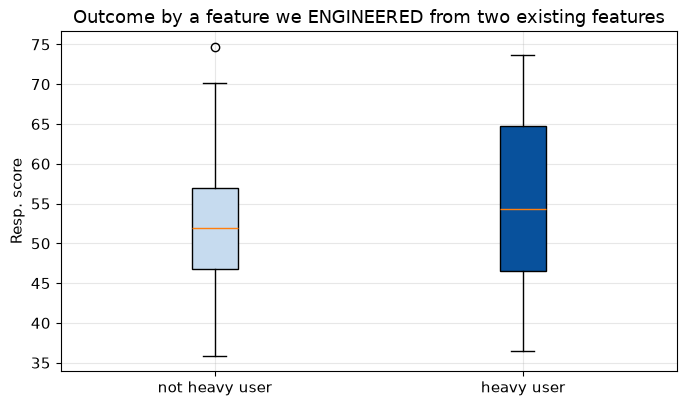


Note: 'heavy_user' did not exist in the data. We created it. That is called feature
engineering, and it is a modelling decision -- the threshold was our choice.


In [116]:
# ANSWER 7
survey["heavy_user"] = np.where((survey["Wifi?"] == "yes") & (survey["BT?"] == "yes"), "yes", "no")

print(survey.groupby("heavy_user")["Resp."].agg(["count", "mean", "std"]).round(2).to_string())
diff = (survey.loc[survey["heavy_user"] == "yes", "Resp."].mean()
        - survey.loc[survey["heavy_user"] == "no", "Resp."].mean())
print(f"\nDifference in means: {diff:+.2f} points")

fig, ax = plt.subplots(figsize=(7, 4.2))
groups = [survey.loc[survey["heavy_user"] == v, "Resp."].values for v in ["no", "yes"]]
bp = ax.boxplot(groups, patch_artist=True)
for patch, colour in zip(bp["boxes"], ["#c6dbef", "#08519c"]):
    patch.set_facecolor(colour)
ax.set_xticks([1, 2]); ax.set_xticklabels(["not heavy user", "heavy user"])
ax.set_ylabel("Resp. score")
ax.set_title("Outcome by a feature we ENGINEERED from two existing features")
plt.tight_layout(); plt.show()

print("\nNote: 'heavy_user' did not exist in the data. We created it. That is called feature")
print("engineering, and it is a modelling decision -- the threshold was our choice.")


In [117]:
# ANSWER 8
# Rebuild the response and the full model here, so this cell stands on its own.
y_resp = survey["Resp."].values

X_full = np.column_stack([np.ones(len(model_data)), model_data.values.astype(float)])
w_full, *_ = np.linalg.lstsq(X_full, y_resp, rcond=None)
resid_full = y_resp - X_full @ w_full

X_reduced = model_data.drop(columns=["tech_score"]).values.astype(float)
X_reduced = np.column_stack([np.ones(len(X_reduced)), X_reduced])
w_reduced, *_ = np.linalg.lstsq(X_reduced, y_resp, rcond=None)
resid_reduced = y_resp - X_reduced @ w_reduced

rmse_full = np.sqrt((resid_full ** 2).mean())
rmse_reduced = np.sqrt((resid_reduced ** 2).mean())

print(f"RMSE with tech_score    : {rmse_full:.3f}")
print(f"RMSE without tech_score : {rmse_reduced:.3f}")
print(f"Error grew by {rmse_reduced - rmse_full:.3f} points "
      f"({(rmse_reduced/rmse_full - 1)*100:.1f}%) when we removed it.")
print("\nInterpretation: tech_score carried real predictive information. Dropping a feature that")
print("matters makes predictions worse; dropping a noise feature changes almost nothing.")
print("This is the honest way to ask 'does this variable matter?' -- remove it and measure.")


RMSE with tech_score    : 7.066
RMSE without tech_score : 9.109
Error grew by 2.043 points (28.9%) when we removed it.

Interpretation: tech_score carried real predictive information. Dropping a feature that
matters makes predictions worse; dropping a noise feature changes almost nothing.
This is the honest way to ask 'does this variable matter?' -- remove it and measure.


In [118]:
# ANSWER 9
by_ug = survey_missing["Resp."].copy()
for ug_value, group in survey_missing.groupby("UG?", observed=True):
    fill = group["Resp."].mean()
    holes_here = group.index[group["Resp."].isna()]
    by_ug.loc[holes_here] = fill

print(f"truth mean                : {truth.mean():.3f}")
print(f"group mean by Tech        : {strategy_group.mean():.3f}  (bias {strategy_group.mean()-truth.mean():+.3f})")
print(f"group mean by UG?         : {by_ug.mean():.3f}  (bias {by_ug.mean()-truth.mean():+.3f})")
print("\nBoth remain biased, and for the same reason: the missingness was MNAR -- driven by the")
print("Resp. value itself, which neither Tech nor UG? can stand in for. No grouping fixes that.")


truth mean                : 53.587
group mean by Tech        : 55.312  (bias +1.725)
group mean by UG?         : 56.010  (bias +2.423)

Both remain biased, and for the same reason: the missingness was MNAR -- driven by the
Resp. value itself, which neither Tech nor UG? can stand in for. No grouping fixes that.


In [119]:
# ANSWER 10
def parse_citation_v2(text):
    record = parse_citation(text)
    pages = re.search(r"pp?\.\s*(\d+)\s*[-\u2013]\s*(\d+)", text)
    if pages:
        record["page_start"] = int(pages.group(1))
        record["page_end"] = int(pages.group(2))
        record["n_pages"] = record["page_end"] - record["page_start"] + 1
    else:
        record["page_start"] = record["page_end"] = record["n_pages"] = None
    return record

test = ('L. Moreno and R. Ba, "Turnout in Municipal Elections," Urban Affairs Review, '
        'Vol. 59, Issue 4, pp. 121-134, 2023.')
for key, value in parse_citation_v2(test).items():
    print(f"   {key:<12} : {value}")

print("\nAnd on a citation with no page range:")
print(f"   page_start -> {parse_citation_v2(citations[0])['page_start']}")


   title        : Turnout in Municipal Elections
   authors      : ['L. Moreno', 'R. Ba']
   n_authors    : 2
   year         : 2023
   venue        : Urban Affairs Review
   volume       : 59
   issue        : 4
   month        : None
   doi          : None
   page_start   : 121
   page_end     : 134
   n_pages      : 14

And on a citation with no page range:
   page_start -> None


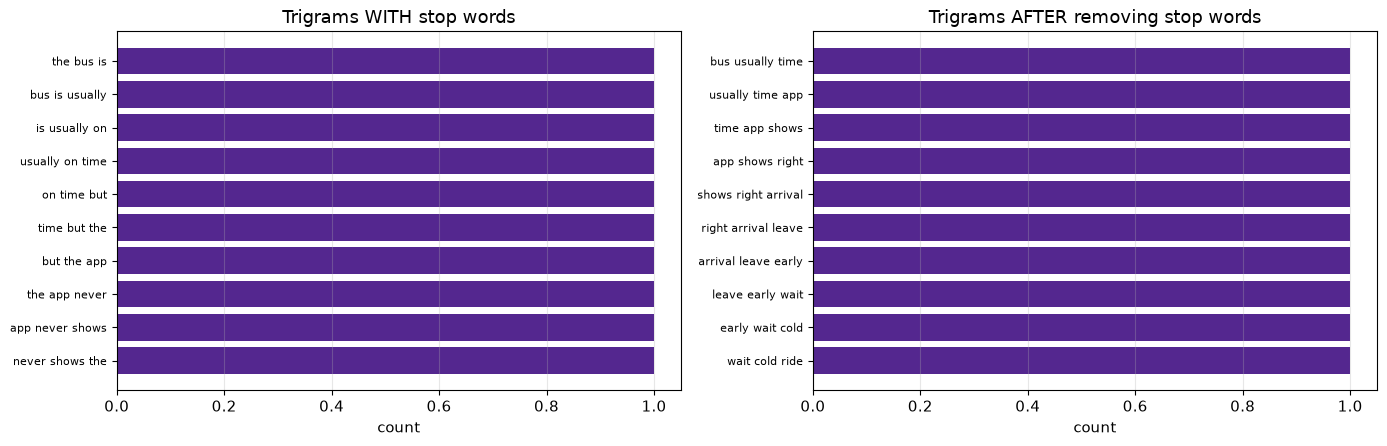

Removing stop words BEFORE building n-grams creates phrases that never occurred in the
text -- words get glued together across the gaps left behind. For topic discovery that
is often acceptable. For any claim about what people actually SAID, it is not.
Order of operations in preprocessing is itself a research decision.


In [120]:
# ANSWER 11
tri_with_stops = Counter(tg for t in corpus for tg in ngrams(tokenize(t), 3))
tri_no_stops = Counter(tg for t in corpus
                       for tg in ngrams([w for w in tokenize(t) if w not in STOP_WORDS], 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, counter, title in [(ax1, tri_with_stops, "Trigrams WITH stop words"),
                           (ax2, tri_no_stops, "Trigrams AFTER removing stop words")]:
    top = counter.most_common(10)[::-1]
    ax.barh([w for w, _ in top], [c for _, c in top], color="#54278f")
    ax.set_xlabel("count")
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Removing stop words BEFORE building n-grams creates phrases that never occurred in the")
print("text -- words get glued together across the gaps left behind. For topic discovery that")
print("is often acceptable. For any claim about what people actually SAID, it is not.")
print("Order of operations in preprocessing is itself a research decision.")


Degrees after adding 'Pitt':
Gkantsidis       3
Krishnamurthy    3
Kaemarungsi      2
Pelechrinis      2
Pitt             2

Density: 6/10 = 0.60
(Before: 4/6 = 0.67. Adding a node ADDS possible edges faster
 than it adds actual ones, so density usually falls as networks grow.)


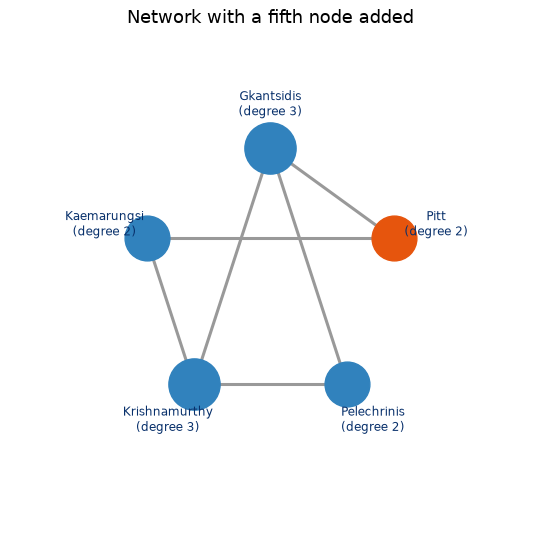

In [121]:
# ANSWER 12
edges_v2 = edges + [("Pitt", "Gkantsidis"), ("Pitt", "Kaemarungsi")]
nodes_v2 = sorted({n for e in edges_v2 for n in e})

adj2 = pd.DataFrame(0, index=nodes_v2, columns=nodes_v2)
for a, b in edges_v2:
    adj2.loc[a, b] = 1
    adj2.loc[b, a] = 1
degree2 = adj2.sum(axis=1).sort_values(ascending=False)

print("Degrees after adding 'Pitt':")
print(degree2.to_string())
possible = len(nodes_v2) * (len(nodes_v2) - 1) / 2
print(f"\nDensity: {len(edges_v2)}/{possible:.0f} = {len(edges_v2)/possible:.2f}")
print(f"(Before: {len(edges)}/6 = {len(edges)/6:.2f}. Adding a node ADDS possible edges faster")
print(" than it adds actual ones, so density usually falls as networks grow.)")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ang2 = np.linspace(np.pi/2, np.pi/2 + 2*np.pi, len(nodes_v2), endpoint=False)
pos2 = {n: (np.cos(a), np.sin(a)) for n, a in zip(nodes_v2, ang2)}
for a, b in edges_v2:
    ax.plot([pos2[a][0], pos2[b][0]], [pos2[a][1], pos2[b][1]],
            color="#999999", linewidth=2.2, zorder=1)
for n, (x, y) in pos2.items():
    ax.scatter([x], [y], s=400 + 320 * degree2[n],
               color="#e6550d" if n == "Pitt" else "#3182bd", zorder=2)
    ax.text(x * 1.34, y * 1.34, f"{n}\n(degree {degree2[n]})", ha="center", va="center",
            fontsize=8.5, color="#08306b", zorder=3)
ax.set_xlim(-2.0, 2.0); ax.set_ylim(-1.9, 1.9)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Network with a fifth node added")
plt.tight_layout(); plt.show()


               band low_readable high_readable longest_wave shortest_wave
     VLF (3-30 kHz)        3 kHz        30 kHz     100.0 km       10.0 km
    LF (30-300 kHz)       30 kHz       300 kHz      10.0 km        1.0 km
 MF (300 kHz-3 MHz)      300 kHz         3 MHz       1.0 km       100.0 m
      HF (3-30 MHz)        3 MHz        30 MHz      100.0 m        10.0 m
   VHF (30-300 MHz)       30 MHz       300 MHz       10.0 m         1.0 m
UHF (300 MHz-3 GHz)      300 MHz         3 GHz        1.0 m      100.0 mm
     SHF (3-30 GHz)        3 GHz        30 GHz     100.0 mm       10.0 mm
   EHF (30-300 GHz)       30 GHz       300 GHz      10.0 mm        1.0 mm
THF (300 GHz-3 THz)      300 GHz         3 THz       1.0 mm      100.0 um


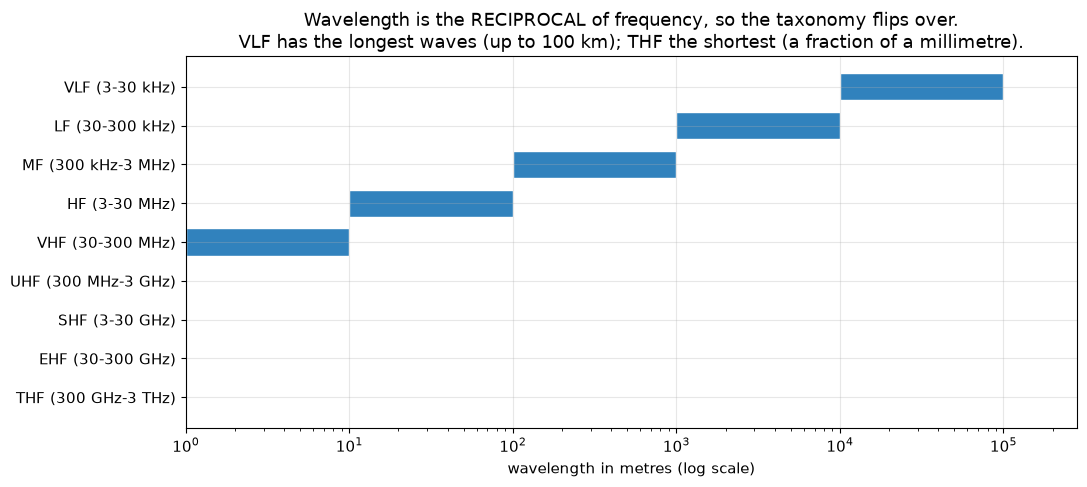


Longest wave in the table : 100.00 km
Shortest wave in the table: 100.00 um
The tree diagram in Section 13 gave no hint that one end is the size of a city and the
other the size of a dust grain.


In [122]:
# ANSWER 13
SPEED_OF_LIGHT = 3e8        # metres per second

spectrum["wavelength_long_m"] = SPEED_OF_LIGHT / spectrum["low_hz"]    # low freq = long wave
spectrum["wavelength_short_m"] = SPEED_OF_LIGHT / spectrum["high_hz"]

print(spectrum[["band", "low_readable", "high_readable"]].assign(
    longest_wave=spectrum["wavelength_long_m"].apply(lambda v: humanise(v, "m", 1)),
    shortest_wave=spectrum["wavelength_short_m"].apply(lambda v: humanise(v, "m", 1)),
).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
for i, (_, row) in enumerate(spectrum.iterrows()):
    ax.barh(i, width=row["wavelength_long_m"] - row["wavelength_short_m"],
            left=row["wavelength_short_m"], color="#3182bd", edgecolor="white", height=0.7)
ax.set_yticks(range(len(spectrum))); ax.set_yticklabels(spectrum["band"])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("wavelength in metres (log scale)")
ax.set_title("Wavelength is the RECIPROCAL of frequency, so the taxonomy flips over.\n"
             "VLF has the longest waves (up to 100 km); THF the shortest (a fraction of a millimetre).")
plt.tight_layout(); plt.show()

print(f"\nLongest wave in the table : {humanise(spectrum['wavelength_long_m'].max(), 'm')}")
print(f"Shortest wave in the table: {humanise(spectrum['wavelength_short_m'].min(), 'm')}")
print("The tree diagram in Section 13 gave no hint that one end is the size of a city and the")
print("other the size of a dust grain.")


In [123]:
# ANSWER 14
QUASI_PLUS = QUASI + ["diagnosis"]
sizes_plus = hospital.groupby(QUASI_PLUS).size()
pct_plus = 100 * sizes_plus[sizes_plus == 1].sum() / len(hospital)

sizes_base = hospital.groupby(QUASI).size()
pct_base = 100 * sizes_base[sizes_base == 1].sum() / len(hospital)

print(f"Uniquely identifiable with (zip, birth_year, gender)            : {pct_base:.1f}%")
print(f"Uniquely identifiable with (zip, birth_year, gender, diagnosis) : {pct_plus:.1f}%")
print(f"k dropped from {sizes_base.min()} to {sizes_plus.min()}.")

print()
print("One-sentence answer: adding an ORDINARY column raises the chance that someone can be")
print("picked out, whereas adding a SENSITIVE column means that when they ARE picked out, the")
print("thing revealed is the very fact they most needed protected -- so the same increase in")
print("uniqueness carries far greater harm.")


Uniquely identifiable with (zip, birth_year, gender)            : 8.4%
Uniquely identifiable with (zip, birth_year, gender, diagnosis) : 56.9%
k dropped from 1 to 1.

One-sentence answer: adding an ORDINARY column raises the chance that someone can be
picked out, whereas adding a SENSITIVE column means that when they ARE picked out, the
thing revealed is the very fact they most needed protected -- so the same increase in
uniqueness carries far greater harm.
